# Modelo OLS — Propiedades nuevas: preparación y baseline

## 1. Fuente y alcance

Se consume exclusivamente **`data/newbuilds_ols.csv`**. No se repiten joins, logaritmos, ingeniería de variables ni encoding de los notebooks anteriores. Las secciones 1–6 preparan matrices en memoria sin entrenar ni crear archivos de particiones. Las secciones 7–13 implementan el baseline, su validación temporal interna y el seguimiento remoto; no realizan selección de características.

`log_price_rub` es y; `price_rub` se reserva para métricas posteriores en RUB. `id`, `complex_id` y `date_posted_dt` son metadatos. Las demás columnas son candidatas explicativas numéricas. El intercepto se considerará al verificar el rango, pero no se añade a X: deberá incorporarse una sola vez al entrenar el baseline.

Test queda fuera del ajuste de parámetros y de las decisiones sobre columnas. Las inspecciones de Test se limitan a integridad, aplicación del esquema definido con Train y documentación de la partición.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.linalg import qr
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 180)

bases = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
rutas_candidatas = [p / "data" / "newbuilds_ols.csv" for p in bases]
rutas_candidatas += [p / "Propiedades_Nuevas" / "data" / "newbuilds_ols.csv" for p in bases]
rutas_candidatas += [p / "Ventas" / "Propiedades_Nuevas" / "data" / "newbuilds_ols.csv" for p in bases]
ruta_datos = next((p for p in rutas_candidatas if p.is_file()), None)
if ruta_datos is None:
    raise FileNotFoundError("No se encontró Propiedades_Nuevas/data/newbuilds_ols.csv.")

df_original = pd.read_csv(ruta_datos, parse_dates=["date_posted_dt"], float_precision="round_trip")
df_modelado = df_original.copy(deep=True)
objetivo = "log_price_rub"
metadatos_columnas = ["id", "complex_id", "date_posted_dt"]
columnas_reservadas = metadatos_columnas + ["price_rub", objetivo]
assert set(columnas_reservadas).issubset(df_modelado.columns)
assert df_modelado.shape == (8000, 160)
assert df_modelado.columns.is_unique and df_modelado.id.notna().all() and df_modelado.id.is_unique
assert df_modelado.complex_id.notna().all() and df_modelado.date_posted_dt.notna().all()
assert pd.api.types.is_datetime64_any_dtype(df_modelado.date_posted_dt)
assert not df_modelado.duplicated().any()
columnas_candidatas = [c for c in df_modelado if c not in columnas_reservadas]
assert all(pd.api.types.is_numeric_dtype(df_modelado[c]) and not pd.api.types.is_bool_dtype(df_modelado[c])
           for c in columnas_candidatas + [objetivo, "price_rub"])
assert np.isfinite(df_modelado[[objetivo, "price_rub"]].to_numpy()).all()
assert df_modelado.price_rub.gt(0).all()
# Validación de la coherencia del objetivo ya recibido, sin volver a crearlo.
assert np.allclose(np.exp(df_modelado[objetivo]), df_modelado.price_rub)

inspeccion_inicial = pd.DataFrame({"tipo_pandas": df_modelado.dtypes.astype(str),
                                   "nulos": df_modelado.isna().sum(),
                                   "porcentaje_nulos": df_modelado.isna().mean()*100})
inspeccion_inicial["infinitos"] = 0
inspeccion_inicial.loc[columnas_candidatas, "infinitos"] = np.isinf(df_modelado[columnas_candidatas]).sum()
print("Fuente:", ruta_datos)
print("Dimensiones:", df_modelado.shape, "| Predictores disponibles:", len(columnas_candidatas))
display(inspeccion_inicial.rename_axis("variable").reset_index())
display(pd.DataFrame({"predictor_disponible": columnas_candidatas}))


Fuente: C:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\Ventas\Propiedades_Nuevas\data\newbuilds_ols.csv
Dimensiones: (8000, 160) | Predictores disponibles: 155


,variable,tipo_pandas,nulos,porcentaje_nulos,infinitos
0,log_price_rub,float64,0,0.0,0
1,price_rub,int64,0,0.0,0
2,id,str,0,0.0,0
3,complex_id,str,0,0.0,0
4,date_posted_dt,datetime64[us],0,0.0,0
5,total_area,float64,0,0.0,0
6,rooms,float64,0,0.0,0
7,floor,float64,0,0.0,0
8,total_floors,float64,0,0.0,0
9,to_center_km,float64,0,0.0,0


,predictor_disponible
0,total_area
1,rooms
2,floor
3,total_floors
4,to_center_km
5,lat
6,lon
7,mortgage_rate_at_listing
8,metro_lat
9,metro_lon


## 2. Partición cronológica exacta 80/20

Se ordena por `date_posted_dt` y luego por `id`, con orden estable. Se conservan **6.400 anuncios antiguos en Train y 1.600 recientes en Test**. Las filas mantienen una correspondencia única con su ID, y se comprueban cobertura, disyunción y reproducibilidad del orden.

Si el límite cae dentro de una fecha, se mantiene el 80/20 exacto y el desempate por ID: Train y Test pueden compartir el día de corte, sin que Train contenga fechas posteriores a Test. No se interpreta ese desempate como orden intradiario real.

Este protocolo permite repetir complejos entre periodos. Su objetivo es evaluar anuncios posteriores, incluidos los de complejos conocidos; no mide exclusivamente generalización a complejos nuevos. `complex_id` se conserva por separado para posteriores evaluaciones agrupadas.


In [2]:
df_modelado = df_modelado.sort_values(["date_posted_dt", "id"], kind="mergesort").reset_index(drop=True)
corte = int(len(df_modelado)*0.80)
df_train = df_modelado.iloc[:corte].copy()
df_test = df_modelado.iloc[corte:].copy()
assert (len(df_train), len(df_test)) == (6400, 1600)
assert len(df_train)+len(df_test) == len(df_original)
assert set(df_train.id).isdisjoint(df_test.id)
assert set(df_train.id) | set(df_test.id) == set(df_original.id)
assert df_train.date_posted_dt.max() <= df_test.date_posted_dt.min()
pd.testing.assert_frame_equal(df_modelado, df_modelado.sort_values(["date_posted_dt", "id"], kind="mergesort").reset_index(drop=True))

fecha_limite = df_train.date_posted_dt.max()
corte_comparte_fecha = fecha_limite == df_test.date_posted_dt.min()
resumen_particion = pd.DataFrame([
    {"conjunto": nombre, "registros":len(tabla), "porcentaje":len(tabla)/len(df_modelado)*100,
     "fecha_minima":tabla.date_posted_dt.min(), "fecha_maxima":tabla.date_posted_dt.max(),
     "complejos":tabla.complex_id.nunique()}
    for nombre, tabla in [("Train", df_train), ("Test", df_test)]
])
display(resumen_particion)
print("¿El corte divide una misma fecha?:", corte_comparte_fecha)
if corte_comparte_fecha:
    print("Fecha compartida:", fecha_limite.date())
    print("Anuncios de esa fecha en Train:", int(df_train.date_posted_dt.eq(fecha_limite).sum()))
    print("Anuncios de esa fecha en Test:", int(df_test.date_posted_dt.eq(fecha_limite).sum()))
    print("Último ID de Train:", df_train.iloc[-1].id, "| Primer ID de Test:", df_test.iloc[0].id)
    assert df_train.iloc[-1].id < df_test.iloc[0].id
complejos_compartidos = set(df_train.complex_id) & set(df_test.complex_id)
print("Complejos compartidos entre Train y Test:", len(complejos_compartidos))


,conjunto,registros,porcentaje,fecha_minima,fecha_maxima,complejos
0,Train,6400,80.0,2021-01-01,2025-04-05,250
1,Test,1600,20.0,2025-04-05,2026-04-29,250


¿El corte divide una misma fecha?: True
Fecha compartida: 2025-04-05
Anuncios de esa fecha en Train: 4
Anuncios de esa fecha en Test: 2
Último ID de Train: N003567 | Primer ID de Test: N005207
Complejos compartidos entre Train y Test: 250


## 3. Separación de predictores, objetivo y metadatos

Se conservan matrices iniciales para auditar los cambios y se separan los precios en RUB. Ningún identificador, fecha, objetivo o precio original ingresa a los predictores. No se vuelven a transformar categorías: se usa el encoding numérico recibido.


In [3]:
X_train_inicial = df_train[columnas_candidatas].copy()
X_test_inicial = df_test[columnas_candidatas].copy()
y_train = df_train[objetivo].copy()
y_test = df_test[objetivo].copy()
price_rub_train = df_train["price_rub"].copy()
price_rub_test = df_test["price_rub"].copy()
metadatos_train = df_train[metadatos_columnas].copy()
metadatos_test = df_test[metadatos_columnas].copy()
assert X_train_inicial.index.equals(y_train.index) and X_test_inicial.index.equals(y_test.index)
assert not set(columnas_reservadas).intersection(X_train_inicial.columns)
assert X_train_inicial.columns.equals(X_test_inicial.columns)
print("X_train inicial:", X_train_inicial.shape, "| X_test inicial:", X_test_inicial.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)


X_train inicial: (6400, 155) | X_test inicial: (1600, 155)
y_train: (6400,) | y_test: (1600,)


## 4. Ajustes aprendidos exclusivamente con Train

### 4.1. Faltantes e infinitos

Los infinitos, si aparecieran, se identifican y marcan como faltantes en copias de trabajo, sin alterar el CSV. Una columna sin ningún dato finito en Train no admite una mediana estimable y se reserva fuera de X. Para las demás se calculan medianas **solo en Train**, y se aplican a los faltantes de ambas matrices. Se registran parámetros y reemplazos. En la ejecución actual no hay faltantes ni infinitos, por lo que no se reemplaza ningún valor.

La conservación o exclusión de columnas nunca depende de sus valores en Test. No se imputan objetivo, precio ni metadatos: un error en esos campos debe revisarse explícitamente.


In [4]:
conteo_previo = pd.DataFrame({
    "nulos_train": X_train_inicial.isna().sum(), "infinitos_train": np.isinf(X_train_inicial).sum(),
    "nulos_test": X_test_inicial.isna().sum(), "infinitos_test": np.isinf(X_test_inicial).sum(),
})
display(conteo_previo)
X_train_ajuste = X_train_inicial.replace([np.inf, -np.inf], np.nan).astype("float64")
X_test_ajuste = X_test_inicial.replace([np.inf, -np.inf], np.nan).astype("float64")
columnas_sin_datos_train = X_train_ajuste.columns[X_train_ajuste.isna().all()].tolist()
X_train_ajuste = X_train_ajuste.drop(columns=columnas_sin_datos_train)
X_test_ajuste = X_test_ajuste.drop(columns=columnas_sin_datos_train)
medianas_train = X_train_ajuste.median()
assert medianas_train.notna().all()
registro_imputacion = pd.DataFrame({"mediana_train":medianas_train,
                                    "reemplazos_train":X_train_ajuste.isna().sum(),
                                    "reemplazos_test":X_test_ajuste.isna().sum()})
X_train_ajuste = X_train_ajuste.fillna(medianas_train)
X_test_ajuste = X_test_ajuste.fillna(medianas_train)
# Los parámetros quedan en memoria aunque en esta ejecución no se necesite imputar.
display(registro_imputacion)
print("Columnas sin datos finitos en Train:", columnas_sin_datos_train)
print("Reemplazos efectivos Train:", int(registro_imputacion.reemplazos_train.sum()),
      "| Test:", int(registro_imputacion.reemplazos_test.sum()))


,nulos_train,infinitos_train,nulos_test,infinitos_test
total_area,0,0,0,0
rooms,0,0,0,0
floor,0,0,0,0
total_floors,0,0,0,0
to_center_km,0,0,0,0
lat,0,0,0,0
lon,0,0,0,0
mortgage_rate_at_listing,0,0,0,0
metro_lat,0,0,0,0
metro_lon,0,0,0,0


,mediana_train,reemplazos_train,reemplazos_test
total_area,5.480000e+01,0,0
rooms,2.000000e+00,0,0
floor,1.200000e+01,0,0
total_floors,2.500000e+01,0,0
to_center_km,1.369000e+01,0,0
lat,5.575289e+01,0,0
lon,3.755786e+01,0,0
mortgage_rate_at_listing,1.200000e+01,0,0
metro_lat,5.575510e+01,0,0
metro_lon,3.760620e+01,0,0


Columnas sin datos finitos en Train: []
Reemplazos efectivos Train: 0 | Test: 0


### 4.2. Constantes y categorías sin observaciones en Train

Se retiran de ambas matrices las columnas constantes de Train. Una dummy siempre cero identifica un nivel sin observaciones en Train; no se puede estimar un coeficiente propio. Si ese nivel aparece en Test, se mantiene la observación y se elimina solo esa columna, según la decisión obtenida de Train. La contribución del nivel no estimable queda sin efecto propio, igual que la referencia en ese bloque; esto limita la interpretación de su predicción.

Una dummy siempre uno tampoco tiene efecto separable del intercepto. Si la referencia original no aparece en Train y las dummies restantes agotan el bloque, el chequeo de dependencias de la siguiente sección debe resolver la redundancia. No se vuelven a elegir categorías con Test.

En esta partición todas las dummies recibidas tienen observaciones en Train y no hay columnas constantes. Se informa el número de filas con el patrón de referencia omitida (bloque de ceros) para cada nominal.


In [5]:
columnas_constantes_train = X_train_ajuste.columns[X_train_ajuste.nunique(dropna=False).le(1)].tolist()
nominales_origen = ["district", "developer", "complex_class", "ready_status", "deal_type", "metro_line"]
bloques_nominales = {c:[v for v in columnas_candidatas if v.startswith(c+"_")] for c in nominales_origen}
columnas_dummy = [v for bloque in bloques_nominales.values() for v in bloque]
categorias_sin_train = [c for c in columnas_dummy if c in X_train_ajuste and X_train_ajuste[c].eq(0).all()]
reporte_constantes = pd.DataFrame([
    {"columna":c, "valor_constante_train":X_train_ajuste[c].iloc[0],
     "motivo":"Constante en Train; sin coeficiente separado del intercepto."}
    for c in columnas_constantes_train
], columns=["columna","valor_constante_train","motivo"])
display(reporte_constantes)
display(pd.DataFrame([
    {"nominal":c, "dummies_en_CSV":len(bloque),
     "dummies_sin_observaciones_train":sum(v in categorias_sin_train for v in bloque),
     "filas_referencia_omitida_train":int(X_train_inicial[bloque].eq(0).all(axis=1).sum())}
    for c,bloque in bloques_nominales.items()
]))
X_train_base = X_train_ajuste.drop(columns=columnas_constantes_train).copy()
X_test_base = X_test_ajuste.drop(columns=columnas_constantes_train).copy()
print("Constantes Train:", columnas_constantes_train)
print("Dummies sin observaciones Train:", categorias_sin_train)


,columna,valor_constante_train,motivo


,nominal,dummies_en_CSV,dummies_sin_observaciones_train,filas_referencia_omitida_train
0,district,108,0,25
1,developer,10,0,494
2,complex_class,3,0,1402
3,ready_status,1,0,285
4,deal_type,3,0,3543
5,metro_line,11,0,795


Constantes Train: []
Dummies sin observaciones Train: []


### 4.3. Dependencias lineales exactas e intercepto

Se comprueba el rango usando exclusivamente Train y sin consultar y. Para diagnóstico se centra cada predictor por su media de Train y se divide por su norma; estas operaciones numéricas **no se aplican a las matrices que se usarán para OLS**, que conservan su escala original. Centrar y reescalar no cambia las dependencias al considerar un intercepto.

Se usa SVD y la tolerancia `max(n, p) * eps * singular_máximo`. Si el rango es deficiente, QR con pivoteo determina un conjunto independiente; se conservan esas columnas en su orden original y se retiran exactamente las mismas de Test. El pivoteo resuelve identificabilidad algebraica, no compara capacidad predictiva ni utiliza el objetivo. Se registra el residuo de representación de cada columna retirada. Dependencias casi exactas pero por encima de la tolerancia y multicolinealidad alta requieren un diagnóstico posterior; rango completo no comprueba todos los supuestos de OLS.


In [6]:
assert X_train_base.shape[1] > 0
medias_diagnostico_train = X_train_base.mean()
centrada_train = X_train_base.to_numpy() - medias_diagnostico_train.to_numpy()
normas_diagnostico_train = np.linalg.norm(centrada_train, axis=0)
assert np.isfinite(normas_diagnostico_train).all() and (normas_diagnostico_train > 0).all()
normalizada_train = centrada_train / normas_diagnostico_train
singulares = np.linalg.svd(normalizada_train, compute_uv=False)
tolerancia_dependencias = max(normalizada_train.shape)*np.finfo(float).eps*singulares[0]
rango_centrado_train = int((singulares > tolerancia_dependencias).sum())
columnas_dependientes_train = []
registro_dependencias = []
if rango_centrado_train < X_train_base.shape[1]:
    Q, R, pivotes = qr(normalizada_train, mode="economic", pivoting=True)
    posiciones_independientes = sorted(pivotes[:rango_centrado_train].tolist())
    posiciones_dependientes = pivotes[rango_centrado_train:].tolist()
    columnas_dependientes_train = X_train_base.columns[posiciones_dependientes].tolist()
    for posicion in posiciones_dependientes:
        vector = normalizada_train[:,posicion]
        residuo = vector - Q[:,:rango_centrado_train] @ (Q[:,:rango_centrado_train].T @ vector)
        registro_dependencias.append({"columna":X_train_base.columns[posicion],
                                      "norma_residuo_representacion":float(np.linalg.norm(residuo)),
                                      "motivo":"Dependencia algebraica en Train considerando intercepto; QR/SVD, sin y."})
    columnas_finales = X_train_base.columns[posiciones_independientes].tolist()
else:
    columnas_finales = X_train_base.columns.tolist()
X_train = X_train_base[columnas_finales].copy()
X_test = X_test_base[columnas_finales].copy()
display(pd.DataFrame(registro_dependencias, columns=["columna","norma_residuo_representacion","motivo"]))
print("Columnas antes del chequeo:", X_train_base.shape[1], "| rango centrado:", rango_centrado_train)
print("Dependencias retiradas:", columnas_dependientes_train)
print("Tolerancia SVD:", tolerancia_dependencias)
# Rango final con intercepto, mediante una representación equivalente normalizada.
centrada_final = X_train.to_numpy()-X_train.mean().to_numpy()
diseno_train_diagnostico = np.column_stack([
    np.ones(len(X_train))/np.sqrt(len(X_train)),
    centrada_final/np.linalg.norm(centrada_final,axis=0),
])
singulares_finales = np.linalg.svd(diseno_train_diagnostico,compute_uv=False)
tolerancia_final = max(diseno_train_diagnostico.shape)*np.finfo(float).eps*singulares_finales[0]
rango_final_con_intercepto = int((singulares_finales > tolerancia_final).sum())
assert rango_final_con_intercepto == X_train.shape[1]+1
print("Rango final incluyendo intercepto:", rango_final_con_intercepto)


,columna,norma_residuo_representacion,motivo


Columnas antes del chequeo: 155 | rango centrado: 155
Dependencias retiradas: []
Tolerancia SVD: 2.998138440940856e-12
Rango final incluyendo intercepto: 156


## 5. Verificaciones finales

La variación y la independencia lineal necesarias para estimar coeficientes se verifican en **Train**. Test conserva siempre el esquema de Train; no se exige que cada nivel aparezca ni que todos los predictores varíen en ese periodo. Una constante o una dependencia propia de Test no justifica cambiar el modelo aprendido con Train.

Se comprueban tipos, finitud, índices y correspondencia con objetivo, precios e IDs, además de ausencia de pérdidas. Se preservan los ID y fechas para recuperar cualquier predicción en su anuncio original.


In [7]:
assert X_train.columns.equals(X_test.columns)
assert not set(columnas_reservadas).intersection(X_train.columns)
assert X_train.columns.is_unique
assert all(pd.api.types.is_numeric_dtype(t) and not pd.api.types.is_bool_dtype(t) for t in X_train.dtypes)
assert all(pd.api.types.is_numeric_dtype(t) and not pd.api.types.is_bool_dtype(t) for t in X_test.dtypes)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all() and np.isfinite(y_test.to_numpy()).all()
assert X_train.nunique(dropna=False).gt(1).all()
assert not X_train.T.duplicated().any()
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.index.equals(price_rub_train.index) and X_test.index.equals(price_rub_test.index)
assert X_train.index.equals(metadatos_train.index) and X_test.index.equals(metadatos_test.index)
assert y_train.equals(df_train[objetivo]) and y_test.equals(df_test[objetivo])
assert price_rub_train.equals(df_train.price_rub) and price_rub_test.equals(df_test.price_rub)
assert len(X_train)+len(X_test) == len(df_original) == 8000
assert set(metadatos_train.id).isdisjoint(metadatos_test.id)
assert set(metadatos_train.id) | set(metadatos_test.id) == set(df_original.id)
# La carga se conserva sin mutaciones y no se vuelve a leer ningún otro archivo.
pd.testing.assert_frame_equal(df_original.sort_values("id").reset_index(drop=True),
                              df_modelado.sort_values("id").reset_index(drop=True))
parametros_train = {
    "medianas":medianas_train.copy(), "columnas_sin_datos":columnas_sin_datos_train.copy(),
    "columnas_constantes":columnas_constantes_train.copy(),
    "columnas_dependientes":columnas_dependientes_train.copy(), "columnas_finales":columnas_finales.copy(),
    "tolerancia_dependencias":tolerancia_dependencias,
}
print("Comprobaciones aprobadas; parámetros y matrices disponibles exclusivamente en memoria.")


Comprobaciones aprobadas; parámetros y matrices disponibles exclusivamente en memoria.


## 6. Resumen de preparación para el baseline OLS

Una característica conceptual (por ejemplo, `district`) puede generar varias columnas OLS. Se distinguen las seis nominales de sus dummies y las numéricas/derivadas. El linaje documentado en la transformación anterior se explicita a continuación para contar campos originales sin volver a leer o transformar ese dataset.

Los objetos para la siguiente etapa son `X_train`, `X_test`, `y_train`, `y_test`, `price_rub_train`, `price_rub_test`, `metadatos_train`, `metadatos_test` y `parametros_train`. Ninguno se exporta. En esta ejecución no se han imputado valores ni eliminado columnas: las 155 candidatas recibidas son estimables con el intercepto en Train.


In [8]:
numericas_conceptuales = [c for c in columnas_candidatas if c not in columnas_dummy]
# Solo documentación de procedencia: no calcula ni vuelve a crear estas variables.
linaje_derivadas = {
    "listing_year":{"date_posted_dt"}, "listing_month_sin":{"date_posted_dt"},
    "listing_month_cos":{"date_posted_dt"}, "months_to_completion":{"date_posted_dt","completion_year"},
    "relative_floor":{"floor","total_floors"},
    "nearest_metro_km":{"lat","lon","metro_lat","metro_lon","metro_year_opened","date_posted_dt"},
}
campos_originales = set(nominales_origen)
for c in numericas_conceptuales:
    campos_originales.update(linaje_derivadas.get(c,{c}))
reporte_esquema = pd.DataFrame([
    {"caracteristica":c,"columnas_recibidas":len(bloque),"columnas_finales":sum(v in columnas_finales for v in bloque)}
    for c,bloque in bloques_nominales.items()
])
display(reporte_esquema)
exclusiones_algebraicas = pd.DataFrame(
    [{"columna":c,"motivo":"Sin datos finitos en Train."} for c in columnas_sin_datos_train]
    + [{"columna":c,"motivo":"Constante en Train."} for c in columnas_constantes_train]
    + [{"columna":c,"motivo":"Dependencia exacta con predictores e intercepto en Train."} for c in columnas_dependientes_train],
    columns=["columna","motivo"],
)
display(exclusiones_algebraicas)
resumen_final = pd.Series({
    "observaciones_totales":len(df_original),"filas_Train":len(X_train),"filas_Test":len(X_test),
    "porcentaje_Train":len(X_train)/len(df_original)*100,"porcentaje_Test":len(X_test)/len(df_original)*100,
    "campos_originales_que_aportan_al_linaje":len(campos_originales),
    "caracteristicas_conceptuales_antes_encoding":len(numericas_conceptuales)+len(nominales_origen),
    "columnas_dummy_recibidas":len(columnas_dummy),"columnas_OLS_iniciales":len(columnas_candidatas),
    "columnas_OLS_definitivas":len(columnas_finales),"rango_Train_con_intercepto":rango_final_con_intercepto,
    "imputaciones_Train":int(registro_imputacion.reemplazos_train.sum()),
    "imputaciones_Test":int(registro_imputacion.reemplazos_test.sum()),
    "columnas_excluidas_por_algebra_o_falta_de_datos":len(exclusiones_algebraicas),
    "observaciones_no_asignadas":len(df_original)-len(X_train)-len(X_test),
    "nulos_finales_Train":int(X_train.isna().sum().sum()),"nulos_finales_Test":int(X_test.isna().sum().sum()),
    "complejos_compartidos":len(complejos_compartidos),
}, name="valor")
display(resumen_final.to_frame())
display(resumen_particion)
display(pd.DataFrame([{"conjunto":nombre,"X":str(x.shape),"y":str(y.shape),"precio_RUB":str(precio.shape),"metadatos":str(meta.shape)}
                      for nombre,x,y,precio,meta in [
                          ("Train",X_train,y_train,price_rub_train,metadatos_train),
                          ("Test",X_test,y_test,price_rub_test,metadatos_test)]]))
print("Matrices preparadas para entrenar el baseline OLS; añadir un único intercepto al ajustar.")
print("No se entrenó OLS, no se ejecutó selección ni se exportaron particiones o parámetros.")


,caracteristica,columnas_recibidas,columnas_finales
0,district,108,108
1,developer,10,10
2,complex_class,3,3
3,ready_status,1,1
4,deal_type,3,3
5,metro_line,11,11


,columna,motivo


,valor
observaciones_totales,8000.0
filas_Train,6400.0
filas_Test,1600.0
porcentaje_Train,80.0
porcentaje_Test,20.0
campos_originales_que_aportan_al_linaje,21.0
caracteristicas_conceptuales_antes_encoding,25.0
columnas_dummy_recibidas,136.0
columnas_OLS_iniciales,155.0
columnas_OLS_definitivas,155.0


,conjunto,registros,porcentaje,fecha_minima,fecha_maxima,complejos
0,Train,6400,80.0,2021-01-01,2025-04-05,250
1,Test,1600,20.0,2025-04-05,2026-04-29,250


,conjunto,X,y,precio_RUB,metadatos
0,Train,"(6400, 155)","(6400,)","(6400,)","(6400, 3)"
1,Test,"(1600, 155)","(1600,)","(1600,)","(1600, 3)"


Matrices preparadas para entrenar el baseline OLS; añadir un único intercepto al ajustar.
No se entrenó OLS, no se ejecutó selección ni se exportaron particiones o parámetros.


La preparación numérica y algebraica está completada. Se conserva el corte por ID del 5 de abril de 2025 y la repetición de complejos entre periodos queda documentada. La disponibilidad histórica de `ready_status` y `months_to_completion`, así como el alcance del catálogo usado en `nearest_metro_km`, mantiene las condiciones declaradas en la etapa de transformación: este notebook no puede certificar su procedencia con un CSV sin historial. Las matrices están listas para el siguiente paso; no se emplearon resultados predictivos de Test para prepararlas.


## 7. Baseline OLS completo y características conceptuales

Desde aquí se entrena únicamente el baseline, sin modificar la partición externa, rehacer transformaciones ni consultar métricas de Test. `diccionario_caracteristicas` asigna todas las columnas a bloques conceptuales sin solapamientos. Las dummies de cada nominal forman un único bloque. Seno y coseno del mes se agrupan como `listing_month`: son dos representaciones del mismo concepto. `floor`, `total_floors` y `relative_floor` son conceptos distintos.

El resultado es **24 características conceptuales y 155 columnas OLS**, más intercepto. El conteo previo de 25 entradas contaba seno y coseno por separado; para futuras selecciones se usarán los 24 bloques. Las referencias omitidas no son columnas existentes. Cada futura incorporación o eliminación deberá actuar sobre un bloque completo. Las exclusiones técnicas se documentan separadamente y no equivalen a selección predictiva.


In [9]:
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
import matplotlib.pyplot as plt
import hashlib
import json

huellas_test_baseline = {k:hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest()
    for k,v in {"X_test":X_test,"y_test":y_test,"price_rub_test":price_rub_test}.items()}
diccionario_caracteristicas = {}
for c in nominales_origen:
    bloque = [v for v in X_train if v.startswith(c+"_")]
    if bloque: diccionario_caracteristicas[c] = bloque
bloque_mes = [c for c in ["listing_month_sin","listing_month_cos"] if c in X_train]
if bloque_mes: diccionario_caracteristicas["listing_month"] = bloque_mes
asignadas = [v for bloque in diccionario_caracteristicas.values() for v in bloque]
for c in X_train:
    if c not in asignadas: diccionario_caracteristicas[c] = [c]
columnas_mapeadas = [v for bloque in diccionario_caracteristicas.values() for v in bloque]
assert len(columnas_mapeadas) == len(set(columnas_mapeadas)) == X_train.shape[1]
assert set(columnas_mapeadas) == set(X_train.columns)
caracteristicas_baseline = list(diccionario_caracteristicas)
tabla_caracteristicas = pd.DataFrame([
    {"Característica":c,"Columnas OLS":len(bloque),"Estado":"Incluida completa, columnas estimables"}
    for c,bloque in diccionario_caracteristicas.items()])
display(tabla_caracteristicas)
display(exclusiones_algebraicas)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(y_train.to_numpy()).all()
assert X_train.nunique(dropna=False).gt(1).all()
assert rango_final_con_intercepto == X_train.shape[1]+1
print("Bloques conceptuales:",len(diccionario_caracteristicas),"| columnas OLS:",X_train.shape[1])


,Característica,Columnas OLS,Estado
0,district,108,"Incluida completa, columnas estimables"
1,developer,10,"Incluida completa, columnas estimables"
2,complex_class,3,"Incluida completa, columnas estimables"
3,ready_status,1,"Incluida completa, columnas estimables"
4,deal_type,3,"Incluida completa, columnas estimables"
5,metro_line,11,"Incluida completa, columnas estimables"
6,listing_month,2,"Incluida completa, columnas estimables"
7,total_area,1,"Incluida completa, columnas estimables"
8,rooms,1,"Incluida completa, columnas estimables"
9,floor,1,"Incluida completa, columnas estimables"


,columna,motivo


Bloques conceptuales: 24 | columnas OLS: 155


## 8. Validación temporal interna exclusivamente en Train

Se fija un holdout reutilizable: el último 20 % de Train es validación. La fecha situada en el 80 % define el inicio; se agrupa el día completo en validación para exigir que sus fechas sean estrictamente posteriores al ajuste. El corte externo 80/20 no cambia.

Se parte de `X_train_inicial`, anterior a las medianas y decisiones de todo Train. La función siguiente aprende medianas, constantes y dependencias solo de la porción de ajuste. No consulta y ni Test. El esquema se aplica a validación sin eliminar observaciones. Las columnas no estimables se omiten técnicamente; un nivel que solo aparece después no tiene efecto propio estimable. Se conservan protocolo e índices para repetir este procedimiento en los futuros experimentos por bloques.


In [10]:
def preparar_ajuste_temporal(X_ajuste, X_validacion):
    a = X_ajuste.replace([np.inf,-np.inf],np.nan).astype(float).copy()
    b = X_validacion.replace([np.inf,-np.inf],np.nan).astype(float).copy()
    sin_datos = a.columns[a.isna().all()].tolist()
    a,b = a.drop(columns=sin_datos),b.drop(columns=sin_datos)
    medianas = a.median()
    a,b = a.fillna(medianas),b.fillna(medianas)
    constantes = a.columns[a.nunique(dropna=False).le(1)].tolist()
    a,b = a.drop(columns=constantes),b.drop(columns=constantes)
    centrada = (a-a.mean()).to_numpy()
    normas = np.linalg.norm(centrada,axis=0)
    assert (normas>0).all()
    z = centrada/normas
    singulares = np.linalg.svd(z,compute_uv=False)
    tolerancia = max(z.shape)*np.finfo(float).eps*singulares[0]
    rango = int((singulares>tolerancia).sum())
    dependientes = []
    if rango < a.shape[1]:
        _,_,pivotes = qr(z,mode="economic",pivoting=True)
        conservar = sorted(pivotes[:rango].tolist())
        dependientes = a.columns[pivotes[rango:]].tolist()
        a,b = a.iloc[:,conservar],b.iloc[:,conservar]
    diseno_a = sm.add_constant(a,has_constant="raise")
    diseno_b = sm.add_constant(b,has_constant="add").reindex(columns=diseno_a.columns)
    assert np.isfinite(diseno_a.to_numpy()).all() and np.isfinite(diseno_b.to_numpy()).all()
    z_final = (a-a.mean()).to_numpy()
    diagnostico = np.column_stack([np.ones(len(a))/np.sqrt(len(a)),z_final/np.linalg.norm(z_final,axis=0)])
    assert np.linalg.matrix_rank(diagnostico) == diseno_a.shape[1]
    return diseno_a,diseno_b,{"medianas":medianas,"sin_datos":sin_datos,"constantes":constantes,
        "dependientes":dependientes,"columnas":a.columns.tolist(),"tolerancia":float(tolerancia)}

fecha_inicio_validacion = df_train.iloc[int(len(df_train)*.80)].date_posted_dt
indices_ajuste_interno = df_train.index[df_train.date_posted_dt.lt(fecha_inicio_validacion)]
indices_validacion_interna = df_train.index[df_train.date_posted_dt.ge(fecha_inicio_validacion)]
assert len(indices_ajuste_interno)+len(indices_validacion_interna) == len(df_train)
assert df_train.loc[indices_ajuste_interno,"date_posted_dt"].max() < df_train.loc[indices_validacion_interna,"date_posted_dt"].min()
protocolo_validacion_baseline = {"tipo":"holdout_temporal_ultimo_20pct_Train_fecha_completa",
    "inicio_validacion":fecha_inicio_validacion.date().isoformat(),"indices_ajuste":indices_ajuste_interno.tolist(),
    "indices_validacion":indices_validacion_interna.tolist(),"fit_transformaciones":"solo_ajuste_interno","usa_test":False}
X_ajuste_interno,X_validacion_interna,parametros_validacion = preparar_ajuste_temporal(
    X_train_inicial.loc[indices_ajuste_interno,columnas_finales],
    X_train_inicial.loc[indices_validacion_interna,columnas_finales])
y_ajuste_interno = y_train.loc[indices_ajuste_interno]
price_rub_validacion = price_rub_train.loc[indices_validacion_interna]
modelo_validacion_baseline = sm.OLS(y_ajuste_interno,X_ajuste_interno,missing="raise").fit()
assert modelo_validacion_baseline.model.rank == X_ajuste_interno.shape[1]
reporte_bloques_validacion = pd.DataFrame([
    {"caracteristica":c,"columnas_baseline":len(bloque),"estimables_ajuste_interno":sum(v in parametros_validacion["columnas"] for v in bloque)}
    for c,bloque in diccionario_caracteristicas.items()])
display(reporte_bloques_validacion)
print("Ajuste interno:",X_ajuste_interno.shape,"| validación:",X_validacion_interna.shape)
print("Constantes solo en ajuste interno:",parametros_validacion["constantes"])
print("Dependencias solo en ajuste interno:",parametros_validacion["dependientes"])


,caracteristica,columnas_baseline,estimables_ajuste_interno
0,district,108,108
1,developer,10,10
2,complex_class,3,3
3,ready_status,1,1
4,deal_type,3,3
5,metro_line,11,11
6,listing_month,2,2
7,total_area,1,1
8,rooms,1,1
9,floor,1,1


Ajuste interno: (5120, 155) | validación: (1280, 155)
Constantes solo en ajuste interno: ['subsidized_mortgage']
Dependencias solo en ajuste interno: []


## 9. Retransformación y reajuste con todo Train

Se fija de antemano smearing de Duan: `factor = media(exp(residuos_log_del_ajuste))`, `pred_RUB = exp(pred_log)*factor`. Para validación, el factor se estima solo con el ajuste interno; para el modelo final, se estima con todo Train. No se elige el método con Test. Un factor global no garantiza corregir perfectamente la media condicional si hay heterocedasticidad.

Las métricas predictivas en RUB son exclusivamente del holdout interno. R², R² ajustado, AIC y BIC describen el reajuste final en **log(RUB) sobre todo Train**. Se cuenta el rango efectivo con intercepto como número de parámetros. Todo Train incluye la hipoteca subsidiada; en el ajuste interno es constante y su coeficiente propio no es estimable. Se mantienen todas las características completas donde sus columnas son estimables, sin selección.


In [11]:
factor_smearing_validacion = float(np.exp(modelo_validacion_baseline.resid).mean())
pred_validacion_log = modelo_validacion_baseline.predict(X_validacion_interna)
pred_validacion_rub = np.exp(pred_validacion_log)*factor_smearing_validacion
assert np.isfinite(pred_validacion_rub).all()
X_train_ols_baseline = sm.add_constant(X_train.astype(float),has_constant="raise")
modelo_ols_baseline = sm.OLS(y_train,X_train_ols_baseline,missing="raise").fit()
assert modelo_ols_baseline.model.rank == X_train_ols_baseline.shape[1] == rango_final_con_intercepto
assert int(modelo_ols_baseline.df_model+1) == int(modelo_ols_baseline.model.rank)
factor_smearing_baseline = float(np.exp(modelo_ols_baseline.resid).mean())
metricas_baseline = {"train_r2_log":float(modelo_ols_baseline.rsquared),
    "train_adj_r2_log":float(modelo_ols_baseline.rsquared_adj),"train_aic":float(modelo_ols_baseline.aic),
    "train_bic":float(modelo_ols_baseline.bic),
    "validation_mae_rub":float(mean_absolute_error(price_rub_validacion,pred_validacion_rub)),
    "validation_rmse_rub":float(np.sqrt(mean_squared_error(price_rub_validacion,pred_validacion_rub))),
    "validation_r2_rub":float(r2_score(price_rub_validacion,pred_validacion_rub))}
assert all(np.isfinite(v) for v in metricas_baseline.values())
limites_coef = modelo_ols_baseline.conf_int()
tabla_coeficientes_baseline = pd.DataFrame({"columna":modelo_ols_baseline.params.index,
    "coef_log":modelo_ols_baseline.params.to_numpy(),"error_estandar_OLS":modelo_ols_baseline.bse.to_numpy(),
    "p_value_OLS":modelo_ols_baseline.pvalues.to_numpy(),"IC95_inferior":limites_coef.iloc[:,0].to_numpy(),
    "IC95_superior":limites_coef.iloc[:,1].to_numpy()})
inferencia_agrupada = modelo_ols_baseline.get_robustcov_results(cov_type="cluster",groups=metadatos_train.complex_id)
tabla_coeficientes_baseline["error_estandar_cluster_complejo"] = inferencia_agrupada.bse
tabla_coeficientes_baseline["p_value_cluster_complejo"] = inferencia_agrupada.pvalues
print(modelo_ols_baseline.summary().as_text())
display(pd.Series(metricas_baseline,name="valor").to_frame())
print("Smearing ajuste interno:",factor_smearing_validacion,"| todo Train:",factor_smearing_baseline)
print("Parámetros estimables finales:",int(modelo_ols_baseline.model.rank))


                            OLS Regression Results                            
Dep. Variable:          log_price_rub   R-squared:                       0.966
Model:                            OLS   Adj. R-squared:                  0.965
Method:                 Least Squares   F-statistic:                     1136.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:12:05   Log-Likelihood:                 4905.3
No. Observations:                6400   AIC:                            -9499.
Df Residuals:                    6244   BIC:                            -8443.
Df Model:                         155                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

,valor
train_r2_log,9.657430e-01
train_adj_r2_log,9.648926e-01
train_aic,-9.498550e+03
train_bic,-8.443358e+03
validation_mae_rub,1.745629e+06
validation_rmse_rub,2.670162e+06
validation_r2_rub,9.114037e-01


Smearing ajuste interno: 1.0061678671419965 | todo Train: 1.0062852487057603
Parámetros estimables finales: 156


## 10. Diagnósticos de OLS en Train

Se muestran residuos logarítmicos, residuos frente a ajustados, Q-Q e influencia. Breusch–Pagan (Koenker robusto por defecto), Jarque–Bera, Cook y leverage son diagnósticos, no criterios de exclusión. `4/n` para Cook y `2p/n` para leverage son umbrales exploratorios. Se usa residuo studentizado interno, sin reajustar un modelo por fila.

Para un diseño de rango completo con intercepto, VIF es la diagonal de la inversa de la matriz de correlación de los predictores. Se guarda la tabla completa y se muestran sus mayores valores. El número de condición original refleja escalas y colinealidad; también se informa una versión centrada y normalizada solo para diagnóstico. No se excluyen características por VIF, p-values o magnitud de coeficientes.

Los anuncios de un complejo no son independientes. Se reportan errores estándar clásicos y agrupados por complejo; ello no elimina otros sesgos. Los p-values de pruebas globales requieren supuestos que la agrupación y dependencia temporal pueden incumplir.


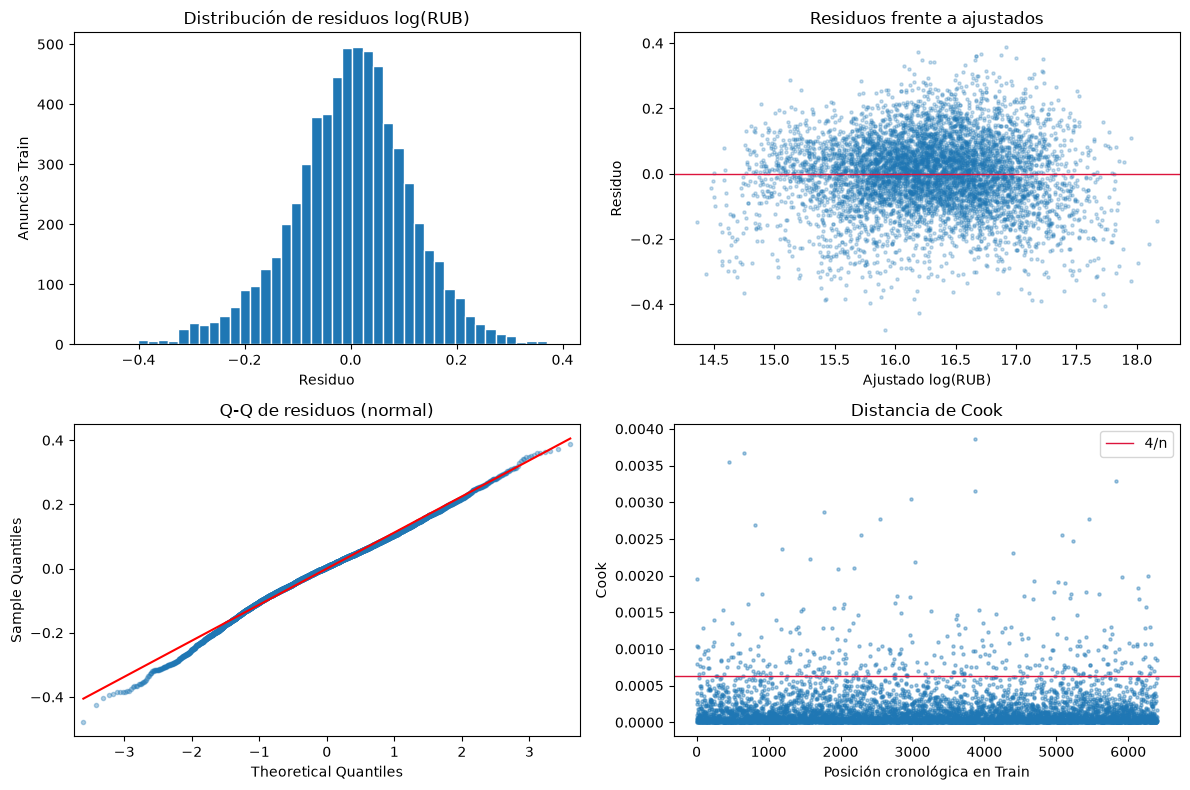

,valor
breusch_pagan_LM,4.579672e+02
breusch_pagan_p,1.086256e-31
jarque_bera,1.420494e+02
jarque_bera_p,1.426776e-31
asimetria_residuos,-2.478469e-01
curtosis_residuos,3.535699e+00
condicion_original,2.594831e+07
condicion_normalizada,7.928807e+01
vif_maximo,7.433233e+02
n_cook_mayor_4_n,3.420000e+02


,columna,VIF
0,nearest_metro_km,743.323267
1,to_center_km,740.584433
2,lat,397.036690
3,lon,380.753984
4,district_Kievsky,211.527926
5,district_Novofyodorovskoye,143.594169
6,district_Voronovskoye,101.709531
7,district_Rogovskoye,98.005073
8,district_Pervomayskoye,95.834005
9,district_Zelenograd,72.131020


,indice_train,residuo_log,residuo_studentizado_interno,leverage,cook
3875,3875,-0.288613,-2.642743,0.079530,0.003868
655,655,0.372615,3.355757,0.048462,0.003676
448,448,-0.385332,-3.462497,0.044178,0.003552
5825,5825,-0.320145,-2.897298,0.057691,0.003294
3871,3871,-0.345930,-3.115189,0.048315,0.003158
2977,2977,0.255681,2.341286,0.079601,0.003039
1768,1768,0.288504,2.615966,0.061302,0.002865
5455,5455,0.351892,3.157738,0.041585,0.002773
2552,2552,-0.275585,-2.503045,0.064461,0.002767
807,807,-0.324987,-2.924220,0.046770,0.002689


No se eliminan observaciones o características a partir de estos diagnósticos.


In [12]:
residuos_baseline = modelo_ols_baseline.resid
ajustados_baseline = modelo_ols_baseline.fittedvalues
influencia_baseline = modelo_ols_baseline.get_influence()
cook_baseline = influencia_baseline.cooks_distance[0]
leverage_baseline = influencia_baseline.hat_matrix_diag
student_baseline = influencia_baseline.resid_studentized_internal
n_baseline,p_baseline = len(X_train),int(modelo_ols_baseline.model.rank)
bp_lm,bp_p,bp_f,bp_fp = het_breuschpagan(residuos_baseline,X_train_ols_baseline)
jb_stat,jb_p,asimetria,curtosis = jarque_bera(residuos_baseline)
vif_baseline = pd.DataFrame({"columna":X_train.columns,"VIF":np.diag(np.linalg.inv(X_train.corr().to_numpy()))}).sort_values("VIF",ascending=False).reset_index(drop=True)
diagnosticos_baseline = {"breusch_pagan_LM":float(bp_lm),"breusch_pagan_p":float(bp_p),
    "jarque_bera":float(jb_stat),"jarque_bera_p":float(jb_p),"asimetria_residuos":float(asimetria),"curtosis_residuos":float(curtosis),
    "condicion_original":float(modelo_ols_baseline.condition_number),"condicion_normalizada":float(np.linalg.cond(diseno_train_diagnostico)),
    "vif_maximo":float(vif_baseline.VIF.max()),"n_cook_mayor_4_n":int((cook_baseline>4/n_baseline).sum()),
    "n_leverage_mayor_2p_n":int((leverage_baseline>2*p_baseline/n_baseline).sum()),
    "n_residuos_student_abs_mayor_3":int((np.abs(student_baseline)>3).sum())}
influencia_tabla = pd.DataFrame({"indice_train":X_train.index,"residuo_log":residuos_baseline.to_numpy(),
    "residuo_studentizado_interno":student_baseline,"leverage":leverage_baseline,"cook":cook_baseline})
top_influencia = influencia_tabla.nlargest(10,"cook")
fig_diagnosticos,axes = plt.subplots(2,2,figsize=(12,8))
axes[0,0].hist(residuos_baseline,bins=45,edgecolor="white")
axes[0,0].set(title="Distribución de residuos log(RUB)",xlabel="Residuo",ylabel="Anuncios Train")
axes[0,1].scatter(ajustados_baseline,residuos_baseline,s=5,alpha=.25)
axes[0,1].axhline(0,color="crimson",linewidth=1)
axes[0,1].set(title="Residuos frente a ajustados",xlabel="Ajustado log(RUB)",ylabel="Residuo")
sm.qqplot(residuos_baseline,line="s",ax=axes[1,0],marker=".",alpha=.35)
axes[1,0].set_title("Q-Q de residuos (normal)")
axes[1,1].scatter(np.arange(n_baseline),cook_baseline,s=5,alpha=.4)
axes[1,1].axhline(4/n_baseline,color="crimson",linewidth=1,label="4/n")
axes[1,1].set(title="Distancia de Cook",xlabel="Posición cronológica en Train",ylabel="Cook")
axes[1,1].legend();fig_diagnosticos.tight_layout();plt.show()
display(pd.Series(diagnosticos_baseline,name="valor").to_frame())
display(vif_baseline.head(15));display(top_influencia)
print("No se eliminan observaciones o características a partir de estos diagnósticos.")


## 11. Configuración remota DagsHub y MLflow

Se reutiliza la configuración funcional de propiedades usadas, sin modificarla: repositorio `matiasgastonlonghino/MOSCOW_IDA`, token del `.env` existente, `dagshub.init(..., patch_mlflow=False)` y Tracking URI remota explícita. Se comprueba que el repositorio ya existe antes de inicializar, por lo que no se crea otro.

Cada ejecución se registra en el experimento independiente **`Propiedades_Nuevas_OLS`**, bajo el run **`Baseline_OLS_LogPrice`**. La credencial no se imprime, copia al notebook ni registra como artefacto. Ante un error remoto se detiene el seguimiento: no se cambia silenciosamente a un almacén local.

Referencias del procedimiento: [configuración oficial DagsHub](https://dagshub.com/docs/client/reference/setup/) y [registro statsmodels en MLflow](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.statsmodels.html).


In [13]:
import os
import sys
import subprocess
from importlib.metadata import version
from dotenv import load_dotenv

raiz_proyecto = next((p for p in [ruta_datos.parent,*ruta_datos.parents]
                      if (p/".env").is_file() and (p/"Data").is_dir() and (p/"Ventas").is_dir()),None)
assert raiz_proyecto is not None
assert Path(sys.prefix).resolve() == (raiz_proyecto/".venv").resolve(), "Seleccionar el kernel .venv del proyecto."
assert subprocess.run(["git","check-ignore","-q",".env"],cwd=raiz_proyecto,capture_output=True).returncode == 0
assert subprocess.run(["git","ls-files","--error-unmatch",".env"],cwd=raiz_proyecto,capture_output=True).returncode != 0
load_dotenv(raiz_proyecto/".env",override=True)
assert os.environ.get("DAGSHUB_USER_TOKEN","").strip(), "Falta DAGSHUB_USER_TOKEN en el .env existente."
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT","1")
import dagshub
import mlflow
import mlflow.statsmodels
from dagshub.common.api import RepoAPI
from mlflow.tracking import MlflowClient

tracking_uri_dagshub = "https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow"
nombre_experimento = "Propiedades_Nuevas_OLS"
nombre_run_baseline = "Baseline_OLS_LogPrice"
assert mlflow.active_run() is None
try:
    RepoAPI("matiasgastonlonghino/MOSCOW_IDA",host="https://dagshub.com").get_repo_info()
    dagshub.init(repo_owner="matiasgastonlonghino",repo_name="MOSCOW_IDA",mlflow=True,dvc=False,patch_mlflow=False)
    mlflow.set_tracking_uri(tracking_uri_dagshub)
    assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
    cliente_baseline = MlflowClient(tracking_uri=tracking_uri_dagshub)
    experimento_existente = cliente_baseline.get_experiment_by_name(nombre_experimento)
except Exception as error:
    mensaje = str(error).replace(os.environ["DAGSHUB_USER_TOKEN"],"[credencial ocultada]")
    raise RuntimeError(f"Falló conexión remota ({type(error).__name__}): {mensaje}. No se habilitó seguimiento local.") from None
print("Servidor remoto autenticado:",mlflow.get_tracking_uri())
print("Experimento independiente:",nombre_experimento)
print("Credencial reutilizada desde .env, ignorado y no versionado en Git.")


c:\Users\mglon\OneDrive\Desktop\UNIVERSIDAD\Introduccion al analisis de datos\MOSCOW DATASET\Moscow_EDA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Accessing as matiasgastonlonghino

Initialized MLflow to track repo "matiasgastonlonghino/MOSCOW_IDA"

Repository matiasgastonlonghino/MOSCOW_IDA initialized!

Servidor remoto autenticado: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow
Experimento independiente: Propiedades_Nuevas_OLS
Credencial reutilizada desde .env, ignorado y no versionado en Git.


## 12. Registro del baseline y verificación de persistencia

Se registra el reajuste con todo Train, cuya salida está en log(RUB), y el factor smearing se guarda por separado. No se registran métricas de Test. El número de parámetros es el rango real del diseño con intercepto; las métricas predictivas en RUB corresponden al ajuste interno de 5.120 filas y validación de 1.280.

Los artefactos contienen resúmenes estadísticos, lista conceptual, correspondencia de bloques, protocolo temporal, parámetros de preparación, exclusiones de cada ámbito, coeficientes, VIF, influencia, gráficos, métricas y modelo statsmodels. Dataset y código se identifican por SHA-256, además del commit y estado del árbol Git. Los ficheros de descargas de verificación son temporales; no se guardan particiones.

Se consulta el run remoto finalizado, se descargan sus artefactos y se recupera el modelo para reproducir predicciones de **Train**, sin evaluar Test.


In [14]:
from copy import deepcopy
from tempfile import TemporaryDirectory
from mlflow.models import infer_signature
import platform

assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
assert mlflow.active_run() is None
experimento_baseline = mlflow.set_experiment(nombre_experimento)
assert experimento_baseline.name == nombre_experimento and experimento_baseline.lifecycle_stage == "active"
versiones_baseline = {p:version(p) for p in ["statsmodels","numpy","pandas","scipy","scikit-learn","mlflow","dagshub"]}
resultado_git = subprocess.run(["git","rev-parse","HEAD"],cwd=raiz_proyecto,capture_output=True,text=True)
commit_baseline = resultado_git.stdout.strip() if resultado_git.returncode==0 else "no_disponible"
git_dirty = bool(subprocess.run(["git","status","--porcelain"],cwd=raiz_proyecto,capture_output=True,text=True).stdout.strip())
notebook_baseline = raiz_proyecto/"Ventas"/"Propiedades_Nuevas"/"Modelo_OLS.ipynb"
codigo_baseline = ["".join(c["source"]) for c in json.loads(notebook_baseline.read_text(encoding="utf-8"))["cells"] if c["cell_type"]=="code"]
sha_codigo_baseline = hashlib.sha256("\n".join(codigo_baseline).encode("utf-8")).hexdigest()
sha_dataset_baseline = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
parametros_baseline = {
    "tipo_modelo":"statsmodels.OLS","target":"log_price_rub","transformacion":"logaritmo_natural",
    "particion":"80_20_cronologico_date_posted_dt_id","n_train":len(X_train),"n_test_reservado":len(X_test),
    "fecha_corte_externo":df_train.date_posted_dt.max().date().isoformat(),"desempate_fecha_externa":"id_ascendente",
    "validacion":protocolo_validacion_baseline["tipo"],"fecha_inicio_validacion":fecha_inicio_validacion.date().isoformat(),
    "n_ajuste_interno":len(X_ajuste_interno),"n_validacion":len(X_validacion_interna),
    "n_caracteristicas_conceptuales":len(diccionario_caracteristicas),"n_columnas_OLS":X_train.shape[1],
    "n_parametros_estimables":int(modelo_ols_baseline.model.rank),"n_parametros_ajuste_interno":int(modelo_validacion_baseline.model.rank),
    "intercepto":True,"seleccion":"ninguna","retransformacion":"exp_por_smearing_Duan_estimado_en_ajuste",
    "smearing_ajuste_interno":factor_smearing_validacion,"smearing_Train_completo":factor_smearing_baseline,
    "dataset":"newbuilds_ols.csv","dataset_sha256":sha_dataset_baseline,"codigo_sha256":sha_codigo_baseline,
    "git_commit":commit_baseline,"git_dirty":git_dirty,"python":platform.python_version(),
    **{f"version_{p}":v for p,v in versiones_baseline.items()},
}
artefactos_texto_baseline = {
    "resumen_ols_log.txt":modelo_ols_baseline.summary().as_text(),
    "resumen_ajuste_interno_log.txt":modelo_validacion_baseline.summary().as_text(),
    "coeficientes_log.csv":tabla_coeficientes_baseline.to_csv(index=False),
    "vif_train.csv":vif_baseline.to_csv(index=False),"top_influencia_train.csv":top_influencia.to_csv(index=False),
    "metricas.csv":pd.Series(metricas_baseline,name="valor").rename_axis("metrica").reset_index().to_csv(index=False),
    "bloques_conceptuales.csv":tabla_caracteristicas.to_csv(index=False),
    "bloques_validacion.csv":reporte_bloques_validacion.to_csv(index=False),
    "limitaciones.md":"Test sin evaluar. Holdout temporal único. Complejos repetidos, errores estándar clásicos y agrupados. Heterocedasticidad y VIF no causan exclusiones. Disponibilidad histórica de ready_status y months_to_completion pendiente; nearest_metro_km usa catálogo parcial observado. Smearing global no garantiza corrección condicional.\n",
}
artefactos_json_baseline = {
    "caracteristicas.json":{"caracteristicas":caracteristicas_baseline},
    "caracteristicas_columnas_OLS.json":diccionario_caracteristicas,
    "protocolo_validacion.json":protocolo_validacion_baseline,"diagnosticos.json":diagnosticos_baseline,
    "retransformacion.json":{"metodo":"exp(pred_log)*factor_smearing","factor_ajuste_interno":factor_smearing_validacion,
        "factor_Train_completo":factor_smearing_baseline,"estimacion":"media(exp(residuos_log_del_ajuste))","usa_test":False},
    "preprocesamiento.json":{"medianas_Train":{k:float(v) for k,v in medianas_train.items()},
        "columnas_Train":columnas_finales,"exclusiones_Train":exclusiones_algebraicas.to_dict(orient="records"),
        "medianas_ajuste_interno":{k:float(v) for k,v in parametros_validacion["medianas"].items()},
        "constantes_ajuste_interno":parametros_validacion["constantes"],
        "dependencias_ajuste_interno":parametros_validacion["dependientes"],
        "columnas_ajuste_interno":parametros_validacion["columnas"],"predecir":"Columnas transformadas en orden más const=1; salida log(RUB)."},
}
with mlflow.start_run(experiment_id=experimento_baseline.experiment_id,run_name=nombre_run_baseline,
    tags={"segmento":"propiedades_nuevas","familia_modelo":"OLS","iteracion":"baseline","target":"log_price_rub",
          "seleccion":"ninguna","validacion":"temporal","test_evaluado":"false",
          "revision":"verificacion_portable_CSV","run_previo_registrado":"38a22888827b4e9590c2ff5bc3e4e725"}) as run_baseline:
    run_id_baseline = run_baseline.info.run_id
    mlflow.log_params(parametros_baseline)
    mlflow.log_metrics(metricas_baseline)
    for nombre,contenido in artefactos_texto_baseline.items(): mlflow.log_text(contenido,nombre)
    for nombre,contenido in artefactos_json_baseline.items(): mlflow.log_dict(contenido,nombre)
    mlflow.log_figure(fig_diagnosticos,"diagnosticos_train.png")
    firma_baseline = infer_signature(X_train_ols_baseline.head(5),modelo_ols_baseline.predict(X_train_ols_baseline.head(5)))
    info_modelo_baseline = mlflow.statsmodels.log_model(deepcopy(modelo_ols_baseline),name="modelo",remove_data=True,
        signature=firma_baseline,pip_requirements=[f"{p}=={versiones_baseline[p]}" for p in ["statsmodels","numpy","pandas","scipy","mlflow"]])
    registro_baseline = {"run_id":run_id_baseline,"experiment_id":experimento_baseline.experiment_id,
        "model_uri":info_modelo_baseline.model_uri,"model_id":info_modelo_baseline.model_id}
    mlflow.log_dict(registro_baseline,"modelo_uri.json")
print("Run enviado y finalizado:",run_id_baseline)
print("Tracking remoto:",mlflow.get_tracking_uri())


🏃 View run Baseline_OLS_LogPrice at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/b384a2ec00ed40239a2f7eb4fb65f49d
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3
Run enviado y finalizado: b384a2ec00ed40239a2f7eb4fb65f49d
Tracking remoto: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow


In [15]:
import math
from io import StringIO
assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
run_remoto_baseline = cliente_baseline.get_run(registro_baseline["run_id"])
assert run_remoto_baseline.info.status == "FINISHED"
assert run_remoto_baseline.info.experiment_id == registro_baseline["experiment_id"]
assert run_remoto_baseline.data.tags["mlflow.runName"] == nombre_run_baseline
assert cliente_baseline.get_experiment(registro_baseline["experiment_id"]).name == nombre_experimento
for k,v in parametros_baseline.items(): assert run_remoto_baseline.data.params[k] == str(v)
for k,v in metricas_baseline.items(): assert math.isclose(run_remoto_baseline.data.metrics[k],v,rel_tol=1e-10,abs_tol=1e-12)
assert not any(k.lower().startswith("test_") or k.lower().endswith("_test") for k in run_remoto_baseline.data.metrics)
assert run_remoto_baseline.data.tags["test_evaluado"] == "false"
archivos_remotos = {a.path for a in cliente_baseline.list_artifacts(registro_baseline["run_id"])}
assert set(artefactos_texto_baseline)|set(artefactos_json_baseline)|{"diagnosticos_train.png","modelo_uri.json"} <= archivos_remotos
with TemporaryDirectory(prefix="verificacion_nuevas_OLS_") as temporal:
    for nombre,esperado in artefactos_json_baseline.items():
        descargado = cliente_baseline.download_artifacts(registro_baseline["run_id"],nombre,dst_path=temporal)
        assert json.loads(Path(descargado).read_text(encoding="utf-8")) == esperado
    for nombre,esperado in artefactos_texto_baseline.items():
        descargado = cliente_baseline.download_artifacts(registro_baseline["run_id"],nombre,dst_path=temporal)
        if nombre.endswith(".csv"):
            # Comparar datos, no convenciones CRLF/LF de Windows al transferir texto.
            pd.testing.assert_frame_equal(pd.read_csv(descargado),pd.read_csv(StringIO(esperado)),
                                           check_exact=False,rtol=1e-12,atol=1e-12)
        else:
            assert Path(descargado).read_text(encoding="utf-8").replace("\r\n","\n") == esperado.replace("\r\n","\n"), nombre
    grafico = cliente_baseline.download_artifacts(registro_baseline["run_id"],"diagnosticos_train.png",dst_path=temporal)
    assert Path(grafico).stat().st_size > 0
    modelo_recuperado = mlflow.statsmodels.load_model(registro_baseline["model_uri"],dst_path=temporal)
    assert modelo_recuperado.model.exog_names == X_train_ols_baseline.columns.tolist()
    np.testing.assert_allclose(modelo_recuperado.predict(X_train_ols_baseline.head(20)),
        modelo_ols_baseline.predict(X_train_ols_baseline.head(20)),rtol=1e-10,atol=1e-10)
assert cliente_baseline.get_logged_model(registro_baseline["model_id"]).source_run_id == registro_baseline["run_id"]
assert mlflow.active_run() is None
url_run_baseline = tracking_uri_dagshub+"/#/experiments/"+registro_baseline["experiment_id"]+"/runs/"+registro_baseline["run_id"]
print("FINISHED: parámetros, métricas, artefactos y modelo recuperados y verificados en DagsHub.")
print("Run ID:",registro_baseline["run_id"])
print("Run:",url_run_baseline)


FINISHED: parámetros, métricas, artefactos y modelo recuperados y verificados en DagsHub.
Run ID: b384a2ec00ed40239a2f7eb4fb65f49d
Run: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/b384a2ec00ed40239a2f7eb4fb65f49d


## 13. Resumen del baseline y próximos experimentos

Se distinguen el ajuste logarítmico final con todo Train y el desempeño en RUB en validación interna. Las exclusiones técnicas solo afectan el ajuste interno: allí `subsidized_mortgage` es constante y no tiene coeficiente separado. El reajuste con todo Train incluye todos los bloques completos.

Los futuros experimentos deberán reutilizar `diccionario_caracteristicas`, `preparar_ajuste_temporal` y `protocolo_validacion_baseline`, incorporar o retirar características completas y registrarse como runs independientes en `Propiedades_Nuevas_OLS`. AIC, BIC y R² ajustado penalizan el rango real con intercepto, no el número de bloques. Esta iteración termina sin Forward, Backward, Best Subset ni regularización.


In [16]:
from IPython.display import Markdown
resumen_baseline = pd.DataFrame([{"Modelo":"Baseline_OLS_LogPrice","Características":len(diccionario_caracteristicas),
    "Columnas OLS":X_train.shape[1],"R² ajustado":metricas_baseline["train_adj_r2_log"],
    "AIC":metricas_baseline["train_aic"],"BIC":metricas_baseline["train_bic"],
    "MAE validación (RUB)":metricas_baseline["validation_mae_rub"],"RMSE validación (RUB)":metricas_baseline["validation_rmse_rub"],
    "R² validación":metricas_baseline["validation_r2_rub"]}])
tabla_resumen_baseline = "| "+" | ".join(resumen_baseline.columns)+" |\n| "+" | ".join(["---"]*len(resumen_baseline.columns))+" |\n"
for fila in resumen_baseline.itertuples(index=False,name=None):
    tabla_resumen_baseline += "| "+" | ".join(f"{v:,.4f}" if isinstance(v,float) else str(v) for v in fila)+" |\n"
display(Markdown(tabla_resumen_baseline))
tabla_bloques_md = "| Característica | Columnas OLS | Estado |\n| --- | --- | --- |\n"
for fila in tabla_caracteristicas.itertuples(index=False,name=None): tabla_bloques_md += "| "+" | ".join(map(str,fila))+" |\n"
display(Markdown(tabla_bloques_md))
for k,v in {"X_test":X_test,"y_test":y_test,"price_rub_test":price_rub_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest() == huellas_test_baseline[k]
print("Test intacto; no se calcularon predicciones ni métricas de Test.")
display(Markdown(f"Registro remoto verificado: [Baseline_OLS_LogPrice]({url_run_baseline})."))
print("No se eliminaron observaciones por extremos ni características por p-values o VIF.")


| Modelo | Características | Columnas OLS | R² ajustado | AIC | BIC | MAE validación (RUB) | RMSE validación (RUB) | R² validación |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Baseline_OLS_LogPrice | 24 | 155 | 0.9649 | -9,498.5505 | -8,443.3582 | 1,745,629.0619 | 2,670,162.4139 | 0.9114 |


| Característica | Columnas OLS | Estado |
| --- | --- | --- |
| district | 108 | Incluida completa, columnas estimables |
| developer | 10 | Incluida completa, columnas estimables |
| complex_class | 3 | Incluida completa, columnas estimables |
| ready_status | 1 | Incluida completa, columnas estimables |
| deal_type | 3 | Incluida completa, columnas estimables |
| metro_line | 11 | Incluida completa, columnas estimables |
| listing_month | 2 | Incluida completa, columnas estimables |
| total_area | 1 | Incluida completa, columnas estimables |
| rooms | 1 | Incluida completa, columnas estimables |
| floor | 1 | Incluida completa, columnas estimables |
| total_floors | 1 | Incluida completa, columnas estimables |
| to_center_km | 1 | Incluida completa, columnas estimables |
| lat | 1 | Incluida completa, columnas estimables |
| lon | 1 | Incluida completa, columnas estimables |
| mortgage_rate_at_listing | 1 | Incluida completa, columnas estimables |
| metro_lat | 1 | Incluida completa, columnas estimables |
| metro_lon | 1 | Incluida completa, columnas estimables |
| metro_year_opened | 1 | Incluida completa, columnas estimables |
| metro_to_center_km | 1 | Incluida completa, columnas estimables |
| subsidized_mortgage | 1 | Incluida completa, columnas estimables |
| listing_year | 1 | Incluida completa, columnas estimables |
| months_to_completion | 1 | Incluida completa, columnas estimables |
| relative_floor | 1 | Incluida completa, columnas estimables |
| nearest_metro_km | 1 | Incluida completa, columnas estimables |


Test intacto; no se calcularon predicciones ni métricas de Test.


Registro remoto verificado: [Baseline_OLS_LogPrice](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/b384a2ec00ed40239a2f7eb4fb65f49d).

No se eliminaron observaciones por extremos ni características por p-values o VIF.


Las limitaciones incluyen la repetición de complejos, un único holdout interno y posible dependencia temporal. La disponibilidad histórica de `ready_status` y `months_to_completion` continúa condicionada a que representen lo declarado al publicar; este CSV no contiene versiones para demostrarlo. `nearest_metro_km` se basa en un catálogo parcial de estaciones observadas. Estas condiciones afectan la interpretación y validez predictiva histórica; no se presentan coeficientes como efectos causales.

Los residuos extremos, heterocedasticidad y colinealidad se diagnostican sin retirar datos. El factor smearing global es una aproximación a la retransfomación de la media y requiere cautela ante errores heterocedásticos. El baseline queda como referencia, con Test todavía reservado para una evaluación final posterior.

En esta ejecución, Breusch–Pagan arroja p≈1,09×10⁻³¹ y Jarque–Bera p≈1,43×10⁻³¹: hay evidencia de heterocedasticidad y desviaciones de normalidad bajo los supuestos de esas pruebas. Se observan 37 residuos studentizados internos con |r|>3 y 342 anuncios por encima del umbral exploratorio de Cook 4/n, sin excluirlos. El VIF máximo es aproximadamente 743,3; el número de condición pasa de 2,59×10⁷ en escalas originales a 79,3 en la representación normalizada de diagnóstico. Se requiere cautela al interpretar coeficientes individuales, aun con rango completo.


## 14. Forward Stepwise por características completas

Se reutilizan las matrices, el diccionario y el holdout temporal del baseline. Estas secciones no cargan el dataset, rehacen transformaciones o consultan métricas de Test. El run del baseline queda inmutable. El algoritmo comienza con intercepto y evalúa la adición de cada bloque pendiente; solo acepta la mayor mejora superior a una tolerancia fija. Los empates dentro de esa tolerancia se resuelven por el orden estable del diccionario.

AIC/BIC se minimizan y R² ajustado se maximiza. Se toman los valores de [OLSResults de statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.html), con penalización por parámetros estimables, no por cantidad de bloques. Se exige rango completo y al menos dos grados de libertad residuales; todos los candidatos de un ámbito usan exactamente las mismas filas. No se filtran p-values.

Forward es una búsqueda voraz: entrega el punto de parada de su recorrido, **no garantiza el óptimo global entre todos los subconjuntos**. Cada criterio comienza de cero. Las columnas previamente no estimables en el ajuste interno se documentan como exclusiones técnicas; no se eligen dummies individuales. Los bloques que conservan columnas estimables se incorporan enteros.


In [17]:
from IPython.display import Markdown
from threadpoolctl import threadpool_limits
from copy import deepcopy
from tempfile import TemporaryDirectory
from io import StringIO
from mlflow.models import infer_signature
import math

assert all(k in globals() for k in ["X_train","X_test","y_train","y_test","diccionario_caracteristicas",
    "X_ajuste_interno","X_validacion_interna","protocolo_validacion_baseline","metricas_baseline","cliente_baseline"])
assert list(diccionario_caracteristicas) == caracteristicas_baseline
huellas_antes_forward = {k:hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest()
    for k,v in {"X_train":X_train,"X_test":X_test,"y_train":y_train,"y_test":y_test}.items()}
configuracion_forward = {
    "AIC":{"run":"Forward_AIC_LogPrice","tolerancia":1e-7},
    "BIC":{"run":"Forward_BIC_LogPrice","tolerancia":1e-7},
    "AdjR2":{"run":"Forward_AdjR2_LogPrice","tolerancia":1e-10},
}
# El baseline tiene un único fold temporal; no se inventan folds adicionales.
folds_temporales_forward = [{"fold":"holdout_1","indices_ajuste":indices_ajuste_interno.copy(),
    "indices_validacion":indices_validacion_interna.copy(),
    "X_ajuste":X_ajuste_interno.drop(columns="const"),
    "X_validacion":X_validacion_interna.drop(columns="const"),
    "y_ajuste":y_ajuste_interno,"price_validacion":price_rub_validacion,
    "parametros":parametros_validacion}]
assert protocolo_validacion_baseline["indices_ajuste"] == indices_ajuste_interno.tolist()
assert protocolo_validacion_baseline["indices_validacion"] == indices_validacion_interna.tolist()
print("Características candidatas:",len(diccionario_caracteristicas),"| folds:",len(folds_temporales_forward))
print("Mismo holdout y smearing del baseline; selección repetida dentro del ajuste interno.")


Características candidatas: 24 | folds: 1
Mismo holdout y smearing del baseline; selección repetida dentro del ajuste interno.


In [18]:
def forward_stepwise(X, y, grupos, criterio, tolerancia=None, min_df_resid=2):
    assert criterio in ["AIC","BIC","AdjR2"]
    tolerancia = (1e-10 if criterio=="AdjR2" else 1e-7) if tolerancia is None else tolerancia
    assert X.index.equals(y.index) and X.columns.is_unique and "const" not in X
    assert np.isfinite(X.to_numpy()).all() and np.isfinite(y.to_numpy()).all()
    mapeadas = [c for bloque in grupos.values() for c in bloque]
    assert len(mapeadas)==len(set(mapeadas)) and set(X).issubset(mapeadas)
    efectivos = {g:[c for c in bloque if c in X] for g,bloque in grupos.items()}
    exclusiones_tecnicas = [{"caracteristica":g,"columna":c,"motivo":"Columna no estimable en la preparación de este ámbito."}
        for g,bloque in grupos.items() for c in bloque if c not in X]
    no_evaluables = [{"iteracion":0,"caracteristica":g,"motivo":"Bloque sin columnas estimables en este ámbito."}
        for g,bloque in efectivos.items() if not bloque]
    pendientes = [g for g,bloque in efectivos.items() if bloque]
    seleccionadas = []
    columnas = []
    modelo = sm.OLS(y,pd.DataFrame({"const":np.ones(len(X))},index=X.index),missing="raise").fit()
    atributo = {"AIC":"aic","BIC":"bic","AdjR2":"rsquared_adj"}[criterio]
    actual = float(getattr(modelo,atributo))
    direccion = 1 if criterio=="AdjR2" else -1
    historial = [{"Iteración":0,"Característica incorporada":"Intercepto",
        "Características acumuladas":0,"Columnas OLS":0,"Valor del criterio":actual,"Mejora":0.0}]
    candidatos_evaluados = []
    motivo = "todas_las_caracteristicas_elegibles_incorporadas"
    while pendientes:
        iteracion = len(seleccionadas)+1
        mejor = None
        for grupo in pendientes:
            nuevas_columnas = columnas+efectivos[grupo]
            if len(X)-(len(nuevas_columnas)+1) < min_df_resid:
                no_evaluables.append({"iteracion":iteracion,"caracteristica":grupo,"motivo":"Grados de libertad residuales insuficientes."})
                continue
            diseno = sm.add_constant(X[nuevas_columnas],has_constant="add")
            try:
                candidato = sm.OLS(y,diseno,missing="raise").fit()
            except (np.linalg.LinAlgError,ValueError) as error:
                no_evaluables.append({"iteracion":iteracion,"caracteristica":grupo,"motivo":type(error).__name__+": "+str(error)})
                continue
            if candidato.model.rank != diseno.shape[1] or candidato.df_resid < min_df_resid:
                no_evaluables.append({"iteracion":iteracion,"caracteristica":grupo,"motivo":"Diseño singular o sin grados residuales suficientes."})
                continue
            assert int(candidato.nobs)==len(X)
            valor = float(getattr(candidato,atributo))
            if not np.isfinite(valor):
                no_evaluables.append({"iteracion":iteracion,"caracteristica":grupo,"motivo":"Criterio no finito."})
                continue
            mejora = direccion*(valor-actual)
            candidatos_evaluados.append({"iteracion":iteracion,"caracteristica":grupo,"criterio":valor,"mejora":mejora,
                "n_observaciones":int(candidato.nobs),"parametros_estimables":int(candidato.model.rank),"columnas_OLS":len(nuevas_columnas)})
            if mejora>tolerancia and (mejor is None or mejora>mejor["mejora"]+tolerancia):
                mejor = {"grupo":grupo,"columnas":nuevas_columnas,"modelo":candidato,"valor":valor,"mejora":mejora}
        if mejor is None:
            motivo = "ninguna_mejora_superior_a_tolerancia_o_candidatos_no_estimables"
            break
        seleccionadas.append(mejor["grupo"])
        pendientes.remove(mejor["grupo"])
        columnas,modelo,actual = mejor["columnas"],mejor["modelo"],mejor["valor"]
        historial.append({"Iteración":iteracion,"Característica incorporada":mejor["grupo"],
            "Características acumuladas":len(seleccionadas),"Columnas OLS":len(columnas),
            "Valor del criterio":actual,"Mejora":mejor["mejora"]})
    assert columnas == [c for g in seleccionadas for c in efectivos[g]]
    for g,bloque in efectivos.items():
        assert set(columnas).intersection(bloque) == (set(bloque) if g in seleccionadas else set())
    return {"seleccionadas":seleccionadas,"columnas":columnas,"modelo":modelo,
        "historial":pd.DataFrame(historial),"candidatos":pd.DataFrame(candidatos_evaluados),
        "no_evaluables":pd.DataFrame(no_evaluables,columns=["iteracion","caracteristica","motivo"]),
        "exclusiones_tecnicas":pd.DataFrame(exclusiones_tecnicas,columns=["caracteristica","columna","motivo"]),
        "motivo":motivo,"criterio":criterio,"valor_final":actual,"tolerancia":tolerancia}

print("Forward por bloques disponible. Sin selección manual, p-values ni acceso a Test.")


Forward por bloques disponible. Sin selección manual, p-values ni acceso a Test.


## 15. Selección dentro del holdout temporal y validación

Para cada criterio y fold se comienza con intercepto, se selecciona exclusivamente en la porción de ajuste y se predice sobre su periodo posterior. Se reutilizan las matrices que el baseline preparó con parámetros aprendidos solo en ese ajuste; no se estiman nuevas transformaciones con validación. La hipoteca subsidiada, constante allí, permanece documentada como bloque no evaluable en ese ámbito.

La retransfomación es exactamente `exp(pred_log)*media(exp(residuos_log_ajuste))`. Se calcula su factor de nuevo para cada modelo del fold. El agregado es la media aritmética por métrica entre los folds; como el protocolo existente tiene **un solo holdout**, coincide con su única fila. No se atribuye a este protocolo una estabilidad entre múltiples folds que no se han observado.

Se limita BLAS a un hilo durante las búsquedas para evitar sobrecarga al ajustar muchos modelos pequeños; no cambia el método OLS ni sus criterios.


In [19]:
resultados_validacion_forward = {}
filas_metricas_folds = []
with threadpool_limits(limits=1,user_api="blas"):
    for criterio,config in configuracion_forward.items():
        resultados_validacion_forward[criterio] = []
        for fold in folds_temporales_forward:
            seleccion = forward_stepwise(fold["X_ajuste"],fold["y_ajuste"],diccionario_caracteristicas,criterio,config["tolerancia"])
            modelo = seleccion["modelo"]
            factor = float(np.exp(modelo.resid).mean())
            diseno_val = sm.add_constant(fold["X_validacion"][seleccion["columnas"]],has_constant="add")
            diseno_val = diseno_val.reindex(columns=modelo.model.exog_names)
            pred_log = modelo.predict(diseno_val)
            pred_rub = np.exp(pred_log)*factor
            assert np.isfinite(pred_rub).all() and len(pred_rub)==len(fold["price_validacion"])
            metricas_fold = {"criterio":criterio,"fold":fold["fold"],"n_ajuste":len(fold["X_ajuste"]),
                "n_validacion":len(fold["X_validacion"]),"caracteristicas":len(seleccion["seleccionadas"]),
                "columnas_OLS":len(seleccion["columnas"]),"parametros_estimables":int(modelo.model.rank),"smearing":factor,
                "validation_mae_rub":float(mean_absolute_error(fold["price_validacion"],pred_rub)),
                "validation_rmse_rub":float(np.sqrt(mean_squared_error(fold["price_validacion"],pred_rub))),
                "validation_r2_rub":float(r2_score(fold["price_validacion"],pred_rub))}
            filas_metricas_folds.append(metricas_fold)
            resultados_validacion_forward[criterio].append({"fold":fold["fold"],"seleccion":seleccion,
                "metricas":metricas_fold,"pred_log":pred_log,"pred_rub":pred_rub,"factor":factor})
            print(criterio,fold["fold"],"seleccionadas:",seleccion["seleccionadas"])
metricas_por_fold_forward = pd.DataFrame(filas_metricas_folds)
metricas_agregadas_forward = metricas_por_fold_forward.groupby("criterio",sort=False)[
    ["validation_mae_rub","validation_rmse_rub","validation_r2_rub"]].mean()
display(metricas_por_fold_forward)
display(metricas_agregadas_forward)


AIC holdout_1 seleccionadas: ['district', 'total_area', 'complex_class', 'listing_year', 'listing_month', 'metro_to_center_km', 'nearest_metro_km', 'lat', 'developer', 'total_floors', 'metro_year_opened', 'months_to_completion', 'mortgage_rate_at_listing', 'to_center_km', 'relative_floor', 'rooms', 'metro_lon', 'ready_status']
BIC holdout_1 seleccionadas: ['district', 'total_area', 'complex_class', 'listing_year', 'listing_month', 'metro_to_center_km', 'nearest_metro_km', 'lat', 'metro_year_opened', 'total_floors']
AdjR2 holdout_1 seleccionadas: ['district', 'total_area', 'complex_class', 'listing_year', 'listing_month', 'metro_to_center_km', 'nearest_metro_km', 'developer', 'lat', 'total_floors', 'metro_year_opened', 'metro_line', 'months_to_completion', 'mortgage_rate_at_listing', 'to_center_km', 'relative_floor', 'rooms', 'deal_type', 'ready_status']


,criterio,fold,n_ajuste,n_validacion,caracteristicas,columnas_OLS,parametros_estimables,smearing,validation_mae_rub,validation_rmse_rub,validation_r2_rub
0,AIC,holdout_1,5120,1280,18,137,138,1.006199,1.749158e+06,2.678705e+06,0.910836
1,BIC,holdout_1,5120,1280,10,120,121,1.006300,1.673634e+06,2.586593e+06,0.916863
2,AdjR2,holdout_1,5120,1280,19,150,151,1.006172,1.747186e+06,2.668124e+06,0.911539


,validation_mae_rub,validation_rmse_rub,validation_r2_rub
criterio,,,
AIC,1.749158e+06,2.678705e+06,0.910836
BIC,1.673634e+06,2.586593e+06,0.916863
AdjR2,1.747186e+06,2.668124e+06,0.911539


## 16. Selecciones definitivas sobre todo Train

Después de completar la validación del proceso de selección, cada criterio vuelve a comenzar con intercepto usando todo Train. Estas selecciones definitivas no se reutilizan retroactivamente para las métricas del holdout. Se conservan modelos, columnas, listas y factores en memoria; Test no recibe predicciones.

Los historiales incluyen el modelo inicial con intercepto y cada incorporación conceptual. AIC/BIC solo se comparan entre candidatos del mismo ámbito y con las mismas filas; no se comparan sus valores absolutos entre ajuste interno y todo Train.


In [20]:
selecciones_forward = {}
modelos_forward = {}
resultados_forward = {}
with threadpool_limits(limits=1,user_api="blas"):
    for criterio,config in configuracion_forward.items():
        seleccion = forward_stepwise(X_train,y_train,diccionario_caracteristicas,criterio,config["tolerancia"])
        modelo = seleccion["modelo"]
        factor = float(np.exp(modelo.resid).mean())
        metricas = {"train_r2_log":float(modelo.rsquared),"train_adj_r2_log":float(modelo.rsquared_adj),
            "train_aic":float(modelo.aic),"train_bic":float(modelo.bic),
            **{k:float(v) for k,v in metricas_agregadas_forward.loc[criterio].items()}}
        coef = pd.DataFrame({"columna":modelo.params.index,"coef_log":modelo.params.to_numpy(),
            "error_estandar":modelo.bse.to_numpy(),"p_value":modelo.pvalues.to_numpy()})
        seleccion["metricas"] = metricas
        selecciones_forward[criterio] = seleccion
        modelos_forward[criterio] = modelo
        resultados_forward[criterio] = {"modelo":modelo,"metricas":metricas,"seleccion":seleccion,
            "coeficientes":coef,"factor_smearing":factor}
        assert int(modelo.nobs)==len(X_train) and int(modelo.model.rank)==len(seleccion["columnas"])+1
        print(criterio,"definitivo:",seleccion["seleccionadas"],"| parada:",seleccion["motivo"])
Forward_AIC = selecciones_forward["AIC"]["seleccionadas"].copy()
Forward_BIC = selecciones_forward["BIC"]["seleccionadas"].copy()
Forward_AdjR2 = selecciones_forward["AdjR2"]["seleccionadas"].copy()
print("Tres modelos definitivos y sus selecciones disponibles en memoria.")


AIC definitivo: ['district', 'total_area', 'complex_class', 'listing_year', 'listing_month', 'subsidized_mortgage', 'metro_to_center_km', 'nearest_metro_km', 'lat', 'floor', 'metro_year_opened', 'developer', 'total_floors', 'metro_line', 'months_to_completion', 'to_center_km', 'rooms', 'mortgage_rate_at_listing', 'ready_status', 'relative_floor'] | parada: ninguna_mejora_superior_a_tolerancia_o_candidatos_no_estimables
BIC definitivo: ['district', 'total_area', 'complex_class', 'listing_year', 'listing_month', 'subsidized_mortgage', 'metro_to_center_km', 'nearest_metro_km', 'lat', 'floor', 'metro_year_opened', 'total_floors'] | parada: ninguna_mejora_superior_a_tolerancia_o_candidatos_no_estimables
AdjR2 definitivo: ['district', 'total_area', 'complex_class', 'listing_year', 'listing_month', 'subsidized_mortgage', 'metro_to_center_km', 'nearest_metro_km', 'lat', 'developer', 'floor', 'metro_year_opened', 'metro_line', 'total_floors', 'months_to_completion', 'to_center_km', 'rooms', 'mo

## 17. Recorridos, coincidencias y estabilidad descriptiva

Cada gráfico corresponde al historial de todo Train, no a desempeño de validación. Los historiales y candidatos del holdout se conservan por separado. Se muestran también las exclusiones técnicas por ámbito. El contraste entre la selección del único holdout y la de todo Train describe sensibilidad al periodo de ajuste; no es una estimación de variación entre múltiples folds.


Historial definitivo: AIC


,Iteración,Característica incorporada,Características acumuladas,Columnas OLS,Valor del criterio,Mejora
0,0,Intercepto,0,0,11784.181007,0.000000
1,1,district,1,108,6359.955699,5424.225308
2,2,total_area,2,109,-960.333652,7320.289351
3,3,complex_class,3,112,-6904.501290,5944.167638
4,4,listing_year,4,113,-8950.230286,2045.728996
5,5,listing_month,5,115,-9084.001746,133.771459
6,6,subsidized_mortgage,6,116,-9221.289587,137.287841
7,7,metro_to_center_km,7,117,-9327.427095,106.137507
8,8,nearest_metro_km,8,118,-9416.559045,89.131950
9,9,lat,9,119,-9435.104755,18.545710


No evaluables en todo Train:


,iteracion,caracteristica,motivo


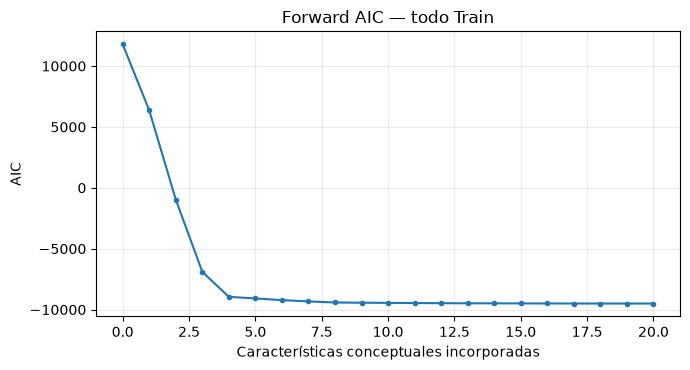

Exclusiones técnicas del ajuste interno: AIC


,caracteristica,columna,motivo
0,subsidized_mortgage,subsidized_mortgage,Columna no estimable en la preparación de este...


,iteracion,caracteristica,motivo
0,0,subsidized_mortgage,Bloque sin columnas estimables en este ámbito.


Historial definitivo: BIC


,Iteración,Característica incorporada,Características acumuladas,Columnas OLS,Valor del criterio,Mejora
0,0,Intercepto,0,0,11790.945061,0.000000
1,1,district,1,108,7097.237505,4693.707555
2,2,total_area,2,109,-216.287793,7313.525298
3,3,complex_class,3,112,-6140.163271,5923.875478
4,4,listing_year,4,113,-8179.128214,2038.964943
5,5,listing_month,5,115,-8299.371567,120.243353
6,6,subsidized_mortgage,6,116,-8429.895355,130.523788
7,7,metro_to_center_km,7,117,-8529.268809,99.373454
8,8,nearest_metro_km,8,118,-8611.636706,82.367897
9,9,lat,9,119,-8623.418363,11.781657


No evaluables en todo Train:


,iteracion,caracteristica,motivo


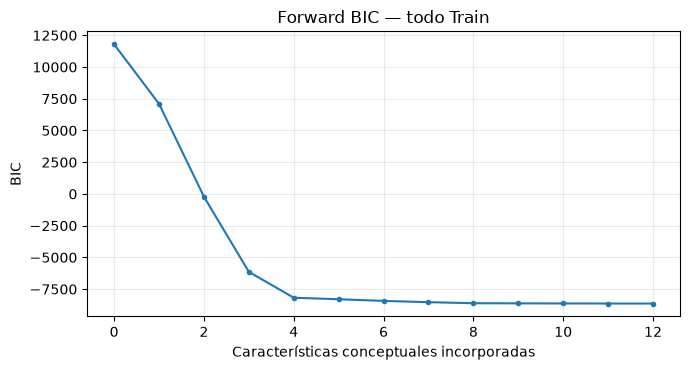

Exclusiones técnicas del ajuste interno: BIC


,caracteristica,columna,motivo
0,subsidized_mortgage,subsidized_mortgage,Columna no estimable en la preparación de este...


,iteracion,caracteristica,motivo
0,0,subsidized_mortgage,Bloque sin columnas estimables en este ámbito.


Historial definitivo: AdjR2


,Iteración,Característica incorporada,Características acumuladas,Columnas OLS,Valor del criterio,Mejora
0,0,Intercepto,0,0,0.000000,0.000000
1,1,district,1,108,0.578638,0.578638
2,2,total_area,2,109,0.865772,0.287133
3,3,complex_class,3,112,0.946999,0.081228
4,4,listing_year,4,113,0.961506,0.014507
5,5,listing_month,5,115,0.962314,0.000808
6,6,subsidized_mortgage,6,116,0.963119,0.000805
7,7,metro_to_center_km,7,117,0.963731,0.000612
8,8,nearest_metro_km,8,118,0.964238,0.000507
9,9,lat,9,119,0.964347,0.000109


No evaluables en todo Train:


,iteracion,caracteristica,motivo


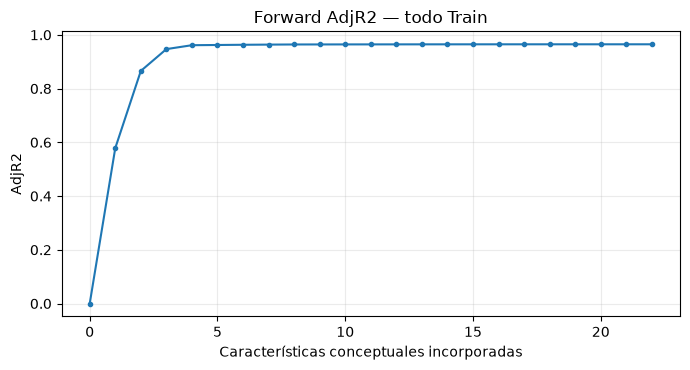

Exclusiones técnicas del ajuste interno: AdjR2


,caracteristica,columna,motivo
0,subsidized_mortgage,subsidized_mortgage,Columna no estimable en la preparación de este...


,iteracion,caracteristica,motivo
0,0,subsidized_mortgage,Bloque sin columnas estimables en este ámbito.


,criterio,fold,seleccion_fold,seleccion_Train,solo_fold,solo_Train,Jaccard_fold_vs_Train
0,AIC,holdout_1,"district, total_area, complex_class, listing_y...","district, total_area, complex_class, listing_y...",metro_lon,"floor, metro_line, subsidized_mortgage",0.809524
1,BIC,holdout_1,"district, total_area, complex_class, listing_y...","district, total_area, complex_class, listing_y...",,"floor, subsidized_mortgage",0.833333
2,AdjR2,holdout_1,"district, total_area, complex_class, listing_y...","district, total_area, complex_class, listing_y...",,"floor, metro_lon, subsidized_mortgage",0.863636


,criterio_1,criterio_2,mismo_subconjunto,solo_criterio_1,solo_criterio_2
0,AIC,BIC,False,"[developer, metro_line, months_to_completion, ...",[]
1,AIC,AdjR2,False,[],"[deal_type, metro_lon]"
2,BIC,AdjR2,False,[],"[deal_type, developer, metro_line, metro_lon, ..."


In [21]:
figuras_forward = {}
filas_estabilidad = []
for criterio,seleccion in selecciones_forward.items():
    print("Historial definitivo:",criterio)
    display(seleccion["historial"])
    print("No evaluables en todo Train:")
    display(seleccion["no_evaluables"])
    fig,ax = plt.subplots(figsize=(7,3.8))
    ax.plot(seleccion["historial"]["Características acumuladas"],seleccion["historial"]["Valor del criterio"],marker="o",markersize=3)
    ax.set(title="Forward "+criterio+" — todo Train",xlabel="Características conceptuales incorporadas",ylabel=criterio)
    ax.grid(alpha=.25);fig.tight_layout();plt.show()
    figuras_forward[criterio] = fig
    for fold in resultados_validacion_forward[criterio]:
        a,b = set(fold["seleccion"]["seleccionadas"]),set(seleccion["seleccionadas"])
        filas_estabilidad.append({"criterio":criterio,"fold":fold["fold"],"seleccion_fold":", ".join(fold["seleccion"]["seleccionadas"]),
            "seleccion_Train":", ".join(seleccion["seleccionadas"]),"solo_fold":", ".join(sorted(a-b)),
            "solo_Train":", ".join(sorted(b-a)),"Jaccard_fold_vs_Train":len(a&b)/len(a|b) if a|b else 1.0})
        print("Exclusiones técnicas del ajuste interno:",criterio)
        display(fold["seleccion"]["exclusiones_tecnicas"])
        display(fold["seleccion"]["no_evaluables"])
estabilidad_forward = pd.DataFrame(filas_estabilidad)
display(estabilidad_forward)
coincidencias_forward = []
claves_criterios = list(selecciones_forward)
for i,a in enumerate(claves_criterios):
    for b in claves_criterios[i+1:]:
        sa,sb = set(selecciones_forward[a]["seleccionadas"]),set(selecciones_forward[b]["seleccionadas"])
        coincidencias_forward.append({"criterio_1":a,"criterio_2":b,"mismo_subconjunto":sa==sb,
            "solo_criterio_1":sorted(sa-sb),"solo_criterio_2":sorted(sb-sa)})
display(pd.DataFrame(coincidencias_forward))


## 18. Comparación con el baseline registrado

Se recupera el baseline verificado de la iteración anterior por ID y se comprueban experimento, dataset, diccionario, protocolo y métricas. No se abre ese run para escritura; se guarda una instantánea de su estado para comprobar que queda intacto.

El ajuste se compara sobre todo Train; la predicción en RUB se compara sobre la selección realizada dentro del mismo holdout temporal. Las reducciones usan al baseline como denominador. Una diferencia negativa de MAE significa mejora. No se comparan AIC/BIC entre muestras diferentes.


In [22]:
assert mlflow.get_tracking_uri().rstrip("/")==tracking_uri_dagshub and mlflow.active_run() is None
run_baseline_forward_id = "82012b9c352b417aba1b5ed5fda90834"
ref_baseline_forward = cliente_baseline.get_run(run_baseline_forward_id)
assert ref_baseline_forward.info.status=="FINISHED"
assert ref_baseline_forward.data.tags["mlflow.runName"]=="Baseline_OLS_LogPrice"
assert cliente_baseline.get_experiment(ref_baseline_forward.info.experiment_id).name=="Propiedades_Nuevas_OLS"
assert ref_baseline_forward.data.params["dataset_sha256"]==hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
metricas_baseline_referencia = dict(ref_baseline_forward.data.metrics)
for k,v in metricas_baseline.items():assert np.isclose(v,metricas_baseline_referencia[k],rtol=1e-9,atol=1e-9)
with TemporaryDirectory(prefix="baseline_forward_referencia_") as temporal:
    for nombre,esperado in [("caracteristicas_columnas_OLS.json",diccionario_caracteristicas),("protocolo_validacion.json",protocolo_validacion_baseline)]:
        archivo=cliente_baseline.download_artifacts(run_baseline_forward_id,nombre,dst_path=temporal)
        assert json.loads(Path(archivo).read_text(encoding="utf-8"))==esperado
snapshot_baseline_forward = {"params":dict(ref_baseline_forward.data.params),"metrics":dict(ref_baseline_forward.data.metrics),
    "tags":dict(ref_baseline_forward.data.tags),"estado":ref_baseline_forward.info.status,
    "artefactos":sorted(a.path for a in cliente_baseline.list_artifacts(run_baseline_forward_id))}
filas_comparacion = []
for nombre,m,n_features,n_cols in [("Baseline OLS",metricas_baseline_referencia,len(diccionario_caracteristicas),X_train.shape[1])]+[
    ("Forward "+k,r["metricas"],len(r["seleccion"]["seleccionadas"]),len(r["seleccion"]["columnas"])) for k,r in resultados_forward.items()]:
    filas_comparacion.append({"Modelo":nombre,"Características":n_features,"Columnas OLS":n_cols,
        "R² ajustado":m["train_adj_r2_log"],"AIC":m["train_aic"],"BIC":m["train_bic"],
        "MAE Validación (RUB)":m["validation_mae_rub"],"RMSE Validación (RUB)":m["validation_rmse_rub"],"R² Validación":m["validation_r2_rub"]})
comparacion_forward = pd.DataFrame(filas_comparacion)
reducciones_forward = comparacion_forward[["Modelo"]].copy()
reducciones_forward["Reducción características (%)"] = 100*(1-comparacion_forward["Características"]/len(diccionario_caracteristicas))
reducciones_forward["Reducción columnas OLS (%)"] = 100*(1-comparacion_forward["Columnas OLS"]/X_train.shape[1])
reducciones_forward["Diferencia MAE validación (%)"] = 100*(comparacion_forward["MAE Validación (RUB)"]/metricas_baseline_referencia["validation_mae_rub"]-1)
orden_caracteristicas = sorted(diccionario_caracteristicas,key=lambda c:(-sum(c in r["seleccionadas"] for r in selecciones_forward.values()),c))
presencia_caracteristicas_forward = pd.DataFrame([
    {"Característica":c,"Baseline":"Sí",**{"Forward "+k:"Sí" if c in r["seleccionadas"] else "No" for k,r in selecciones_forward.items()}}
    for c in orden_caracteristicas])
for titulo,tabla in [("Comparación con baseline",comparacion_forward),("Cambios porcentuales",reducciones_forward),
                    ("Características por coincidencia entre criterios",presencia_caracteristicas_forward)]:
    texto="### "+titulo+"\n\n| "+" | ".join(tabla.columns)+" |\n| "+" | ".join(["---"]*len(tabla.columns))+" |\n"
    for fila in tabla.itertuples(index=False,name=None):
        texto+="| "+" | ".join(f"{v:,.6f}" if isinstance(v,float) else str(v) for v in fila)+" |\n"
    display(Markdown(texto))
print("Referencia remota y protocolo del baseline comprobados.")


### Comparación con baseline

| Modelo | Características | Columnas OLS | R² ajustado | AIC | BIC | MAE Validación (RUB) | RMSE Validación (RUB) | R² Validación |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Baseline OLS | 24 | 155 | 0.964893 | -9,498.550475 | -8,443.358165 | 1,745,629.061856 | 2,670,162.413894 | 0.911404 |
| Forward AIC | 20 | 149 | 0.964880 | -9,502.143948 | -8,487.535958 | 1,749,158.164805 | 2,678,705.424330 | 0.910836 |
| Forward BIC | 12 | 122 | 0.964550 | -9,468.708032 | -8,636.729480 | 1,673,633.877273 | 2,586,593.158458 | 0.916863 |
| Forward AdjR2 | 22 | 153 | 0.964894 | -9,500.688502 | -8,459.024299 | 1,747,186.026404 | 2,668,123.716809 | 0.911539 |


### Cambios porcentuales

| Modelo | Reducción características (%) | Reducción columnas OLS (%) | Diferencia MAE validación (%) |
| --- | --- | --- | --- |
| Baseline OLS | 0.000000 | 0.000000 | 0.000000 |
| Forward AIC | 16.666667 | 3.870968 | 0.202168 |
| Forward BIC | 50.000000 | 21.290323 | -4.124312 |
| Forward AdjR2 | 8.333333 | 1.290323 | 0.089192 |


### Características por coincidencia entre criterios

| Característica | Baseline | Forward AIC | Forward BIC | Forward AdjR2 |
| --- | --- | --- | --- | --- |
| complex_class | Sí | Sí | Sí | Sí |
| district | Sí | Sí | Sí | Sí |
| floor | Sí | Sí | Sí | Sí |
| lat | Sí | Sí | Sí | Sí |
| listing_month | Sí | Sí | Sí | Sí |
| listing_year | Sí | Sí | Sí | Sí |
| metro_to_center_km | Sí | Sí | Sí | Sí |
| metro_year_opened | Sí | Sí | Sí | Sí |
| nearest_metro_km | Sí | Sí | Sí | Sí |
| subsidized_mortgage | Sí | Sí | Sí | Sí |
| total_area | Sí | Sí | Sí | Sí |
| total_floors | Sí | Sí | Sí | Sí |
| developer | Sí | Sí | No | Sí |
| metro_line | Sí | Sí | No | Sí |
| months_to_completion | Sí | Sí | No | Sí |
| mortgage_rate_at_listing | Sí | Sí | No | Sí |
| ready_status | Sí | Sí | No | Sí |
| relative_floor | Sí | Sí | No | Sí |
| rooms | Sí | Sí | No | Sí |
| to_center_km | Sí | Sí | No | Sí |
| deal_type | Sí | No | No | Sí |
| metro_lon | Sí | No | No | Sí |
| lon | Sí | No | No | No |
| metro_lat | Sí | No | No | No |


Referencia remota y protocolo del baseline comprobados.


## 19. Tres runs Forward independientes en DagsHub

Se reutiliza `Propiedades_Nuevas_OLS`. Cada run registra criterio, tolerancia, tamaños, parámetros estimables, detención, linaje y retransfomación, junto con métricas del modelo definitivo y del proceso validado dentro del holdout. No se registra Test ni se modifica el run del baseline.

Los artefactos guardan listas conceptuales, mapas de columnas, historiales y candidatos evaluados por ámbito, no evaluabilidad, métricas por fold y agregadas, comparación, estabilidad descriptiva, factores smearing, coeficientes, gráfico y modelo. Se recuperan artefactos y modelo para comprobar persistencia y predicciones de Train. No se sustituye un fallo remoto por almacenamiento local.


In [23]:
import mlflow.statsmodels
assert mlflow.get_tracking_uri().rstrip("/")==tracking_uri_dagshub and mlflow.active_run() is None
experimento_forward=mlflow.set_experiment("Propiedades_Nuevas_OLS")
assert experimento_forward.experiment_id==ref_baseline_forward.info.experiment_id
versiones_forward={p:version(p) for p in ["statsmodels","numpy","pandas","scipy","mlflow"]}
notebook_forward=raiz_proyecto/"Ventas"/"Propiedades_Nuevas"/"Modelo_OLS.ipynb"
codigo_forward=["".join(c["source"]) for c in json.loads(notebook_forward.read_text(encoding="utf-8"))["cells"] if c["cell_type"]=="code"]
sha_codigo_forward=hashlib.sha256("\n".join(codigo_forward).encode("utf-8")).hexdigest()
git_forward=subprocess.run(["git","rev-parse","HEAD"],cwd=raiz_proyecto,capture_output=True,text=True)
commit_forward=git_forward.stdout.strip() if git_forward.returncode==0 else "no_disponible"
git_dirty_forward=bool(subprocess.run(["git","status","--porcelain"],cwd=raiz_proyecto,capture_output=True,text=True).stdout.strip())
registros_forward={}
verificaciones_forward=[]
for criterio,r in resultados_forward.items():
    seleccion,modelo,config=r["seleccion"],r["modelo"],configuracion_forward[criterio]
    parametros={"algoritmo":"Forward Stepwise","criterio":criterio,"target":"log_price_rub","nivel_seleccion":"caracteristicas_completas",
        "validacion":protocolo_validacion_baseline["tipo"],"n_train":len(X_train),"n_folds":len(folds_temporales_forward),
        "n_caracteristicas_candidatas":len(diccionario_caracteristicas),"n_caracteristicas_seleccionadas":len(seleccion["seleccionadas"]),
        "n_columnas_OLS":len(seleccion["columnas"]),"n_parametros_estimables":int(modelo.model.rank),
        "n_iteraciones":len(seleccion["seleccionadas"]),"motivo_detencion":seleccion["motivo"],"tolerancia":config["tolerancia"],
        "min_df_resid":2,"intercepto":True,"retransformacion":"exp_por_smearing_Duan_estimado_en_ajuste",
        "smearing_Train":r["factor_smearing"],"agregacion_folds":"media_aritmetica_por_metrica","baseline_run_id":run_baseline_forward_id,
        "dataset":"newbuilds_ols.csv","dataset_sha256":ref_baseline_forward.data.params["dataset_sha256"],
        "codigo_sha256":sha_codigo_forward,"git_commit":commit_forward,"git_dirty":git_dirty_forward,
        "fecha_inicio_validacion":protocolo_validacion_baseline["inicio_validacion"],
        "n_ajuste_interno":len(indices_ajuste_interno),"n_validacion":len(indices_validacion_interna),
        **{f"version_{p}":v for p,v in versiones_forward.items()}}
    metricas_folds=metricas_por_fold_forward.loc[metricas_por_fold_forward.criterio.eq(criterio)].copy()
    textos={"resumen_OLS_log.txt":modelo.summary().as_text(),"coeficientes_log.csv":r["coeficientes"].to_csv(index=False),
        "historial_Train.csv":seleccion["historial"].to_csv(index=False),"candidatos_Train.csv":seleccion["candidatos"].to_csv(index=False),
        "no_evaluables_Train.csv":seleccion["no_evaluables"].to_csv(index=False),
        "exclusiones_tecnicas_Train.csv":seleccion["exclusiones_tecnicas"].to_csv(index=False),
        "metricas_folds.csv":metricas_folds.to_csv(index=False),"comparacion_baseline.csv":comparacion_forward.to_csv(index=False),
        "cambios_porcentuales.csv":reducciones_forward.to_csv(index=False),"presencia_caracteristicas.csv":presencia_caracteristicas_forward.to_csv(index=False),
        "estabilidad_descriptiva.csv":estabilidad_forward.loc[estabilidad_forward.criterio.eq(criterio)].to_csv(index=False)}
    folds_json=[]
    for fold in resultados_validacion_forward[criterio]:
        sf=fold["seleccion"];nombre_fold=fold["fold"]
        for nombre,tabla in [("historial",sf["historial"]),("candidatos",sf["candidatos"]),("no_evaluables",sf["no_evaluables"]),("exclusiones_tecnicas",sf["exclusiones_tecnicas"])]:
            textos[nombre+"_"+nombre_fold+".csv"]=tabla.to_csv(index=False)
        folds_json.append({"fold":nombre_fold,"seleccionadas":sf["seleccionadas"],"columnas":sf["columnas"],"smearing":fold["factor"],"metricas":fold["metricas"],"motivo":sf["motivo"]})
    jsons={"seleccion_forward.json":{"criterio":criterio,"seleccionadas":seleccion["seleccionadas"],"orden_incorporacion":seleccion["seleccionadas"],
        "columnas_OLS":seleccion["columnas"],"motivo":seleccion["motivo"],"tolerancia":seleccion["tolerancia"],"inicio":"solo_intercepto"},
        "caracteristicas_columnas_OLS.json":diccionario_caracteristicas,"validacion.json":{"protocolo":protocolo_validacion_baseline,"folds":folds_json},
        "metricas.json":r["metricas"],"retransformacion.json":{"metodo":"exp(pred_log)*factor_smearing","factor_Train":r["factor_smearing"],"usa_test":False},
        "coincidencias_criterios.json":coincidencias_forward,
        "preprocesamiento_validacion.json":{"medianas_ajuste":{k:float(v) for k,v in parametros_validacion["medianas"].items()},
            "constantes_ajuste":parametros_validacion["constantes"],"dependencias_ajuste":parametros_validacion["dependientes"],
            "columnas_ajuste":parametros_validacion["columnas"],"fit_solo_ajuste":True}}
    train_diseno=sm.add_constant(X_train[seleccion["columnas"]],has_constant="add").reindex(columns=modelo.model.exog_names)
    with mlflow.start_run(experiment_id=experimento_forward.experiment_id,run_name=config["run"],
        tags={"segmento":"propiedades_nuevas","familia_modelo":"OLS","iteracion":"forward","target":"log_price_rub",
              "seleccion":"forward_por_caracteristicas","criterio":criterio,"validacion":"temporal","test_evaluado":"false"}) as run:
        mlflow.log_params(parametros);mlflow.log_metrics(r["metricas"])
        for nombre,texto in textos.items():mlflow.log_text(texto,nombre)
        for nombre,contenido in jsons.items():mlflow.log_dict(contenido,nombre)
        mlflow.log_figure(figuras_forward[criterio],"evolucion_criterio.png")
        info_modelo=mlflow.statsmodels.log_model(deepcopy(modelo),name="modelo",remove_data=True,
            signature=infer_signature(train_diseno.head(5),modelo.predict(train_diseno.head(5))),
            pip_requirements=[f"{p}=={v}" for p,v in versiones_forward.items()])
        registro={"run_id":run.info.run_id,"experiment_id":experimento_forward.experiment_id,
            "model_uri":info_modelo.model_uri,"model_id":info_modelo.model_id}
        mlflow.log_dict(registro,"modelo_uri.json")
    registros_forward[criterio]=registro
    remoto=cliente_baseline.get_run(registro["run_id"])
    assert remoto.info.status=="FINISHED" and remoto.data.tags["mlflow.runName"]==config["run"]
    assert remoto.info.experiment_id==experimento_forward.experiment_id
    for k,v in parametros.items():assert remoto.data.params[k]==str(v)
    for k,v in r["metricas"].items():assert math.isclose(remoto.data.metrics[k],v,rel_tol=1e-10,abs_tol=1e-12)
    assert not any(k.lower().startswith("test_") or k.lower().endswith("_test") for k in remoto.data.metrics)
    assert set(textos)|set(jsons)|{"evolucion_criterio.png","modelo_uri.json"} <= {a.path for a in cliente_baseline.list_artifacts(registro["run_id"])}
    with TemporaryDirectory(prefix="forward_nuevas_verificacion_") as temporal:
        for nombre,esperado in jsons.items():
            archivo=cliente_baseline.download_artifacts(registro["run_id"],nombre,dst_path=temporal)
            assert json.loads(Path(archivo).read_text(encoding="utf-8"))==esperado
        for nombre,esperado in textos.items():
            archivo=cliente_baseline.download_artifacts(registro["run_id"],nombre,dst_path=temporal)
            if nombre.endswith(".csv"):
                pd.testing.assert_frame_equal(pd.read_csv(archivo),pd.read_csv(StringIO(esperado)),check_exact=False,rtol=1e-12,atol=1e-12)
            else:assert Path(archivo).read_text(encoding="utf-8").splitlines()==esperado.splitlines()
        grafico=cliente_baseline.download_artifacts(registro["run_id"],"evolucion_criterio.png",dst_path=temporal)
        assert Path(grafico).stat().st_size>0
        recuperado=mlflow.statsmodels.load_model(registro["model_uri"],dst_path=temporal)
        assert recuperado.model.exog_names==modelo.model.exog_names
        np.testing.assert_allclose(recuperado.predict(train_diseno.head(20)),modelo.predict(train_diseno.head(20)),rtol=1e-10,atol=1e-10)
    assert cliente_baseline.get_logged_model(registro["model_id"]).source_run_id==registro["run_id"]
    url=tracking_uri_dagshub+"/#/experiments/"+registro["experiment_id"]+"/runs/"+registro["run_id"]
    verificaciones_forward.append({"criterio":criterio,"run_id":registro["run_id"],"estado":"FINISHED","artefactos_y_modelo_verificados":True,"url":url})
    print(config["run"],"FINISHED; artefactos y modelo recuperados:",url)
assert len({r["run_id"] for r in registros_forward.values()})==len(configuracion_forward)
assert run_baseline_forward_id not in {r["run_id"] for r in registros_forward.values()}
ref_despues=cliente_baseline.get_run(run_baseline_forward_id)
assert {"params":dict(ref_despues.data.params),"metrics":dict(ref_despues.data.metrics),"tags":dict(ref_despues.data.tags),
    "estado":ref_despues.info.status,"artefactos":sorted(a.path for a in cliente_baseline.list_artifacts(run_baseline_forward_id))}==snapshot_baseline_forward
assert mlflow.active_run() is None and mlflow.get_tracking_uri().rstrip("/")==tracking_uri_dagshub
for k,v in {"X_train":X_train,"X_test":X_test,"y_train":y_train,"y_test":y_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest()==huellas_antes_forward[k]
display(pd.DataFrame(verificaciones_forward))
print("Baseline remoto y matrices intactos; Test no evaluado. Sin Backward ni regularización.")


🏃 View run Forward_AIC_LogPrice at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/6bcb62a79d004a00bc314edb3b2a5265
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Forward_AIC_LogPrice FINISHED; artefactos y modelo recuperados: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/6bcb62a79d004a00bc314edb3b2a5265
🏃 View run Forward_BIC_LogPrice at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/64d4f9d54a2a4dd09f304b08eaf7e27c
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Forward_BIC_LogPrice FINISHED; artefactos y modelo recuperados: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/64d4f9d54a2a4dd09f304b08eaf7e27c
🏃 View run Forward_AdjR2_LogPrice at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/eff09351d1414208bbc3eff3697d4b4e
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Forward_AdjR2_LogPrice FINISHED; artefactos y modelo recuperados: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/eff09351d1414208bbc3eff3697d4b4e


,criterio,run_id,estado,artefactos_y_modelo_verificados,url
0,AIC,6bcb62a79d004a00bc314edb3b2a5265,FINISHED,True,https://dagshub.com/matiasgastonlonghino/MOSCO...
1,BIC,64d4f9d54a2a4dd09f304b08eaf7e27c,FINISHED,True,https://dagshub.com/matiasgastonlonghino/MOSCO...
2,AdjR2,eff09351d1414208bbc3eff3697d4b4e,FINISHED,True,https://dagshub.com/matiasgastonlonghino/MOSCO...


Baseline remoto y matrices intactos; Test no evaluado. Sin Backward ni regularización.


## 20. Conclusiones de esta iteración

Cada holdout seleccionó con su propio ajuste; el modelo definitivo se volvió a seleccionar con todo Train. Las reducciones y diferencias de error se resumen a continuación sin declarar un ganador con Test ni un óptimo global de subconjuntos.

El único holdout permite estudiar sensibilidad frente al ajuste con todo Train, pero no estimar variación entre múltiples ventanas. Continúan las limitaciones sobre dependencia por complejo, heterocedasticidad, disponibilidad histórica de atributos y catálogo geográfico parcial. Test permanece reservado para una evaluación final posterior.


In [24]:
for criterio,r in resultados_forward.items():
    cambio=reducciones_forward.loc[reducciones_forward.Modelo.eq("Forward "+criterio)].iloc[0]
    display(Markdown(f"**Forward {criterio}**: {len(r['seleccion']['seleccionadas'])} características, {len(r['seleccion']['columnas'])} columnas OLS; reducción de características {cambio['Reducción características (%)']:.2f} %, reducción de columnas {cambio['Reducción columnas OLS (%)']:.2f} % y diferencia de MAE temporal {cambio['Diferencia MAE validación (%)']:+.3f} % respecto del baseline."))
for coincidencia in coincidencias_forward:
    if coincidencia["mismo_subconjunto"]:print(coincidencia["criterio_1"],"y",coincidencia["criterio_2"],"coinciden; sus runs se conservan independientes.")
for verificacion in verificaciones_forward:
    display(Markdown(f"[{configuracion_forward[verificacion['criterio']]['run']}]({verificacion['url']}) — FINISHED, verificado."))
print("Forward_AIC, Forward_BIC, Forward_AdjR2, modelos_forward, resultados_forward y diccionario_caracteristicas disponibles en memoria.")
print("Iteración finalizada sin consultar Test ni iniciar Backward.")


**Forward AIC**: 20 características, 149 columnas OLS; reducción de características 16.67 %, reducción de columnas 3.87 % y diferencia de MAE temporal +0.202 % respecto del baseline.

**Forward BIC**: 12 características, 122 columnas OLS; reducción de características 50.00 %, reducción de columnas 21.29 % y diferencia de MAE temporal -4.124 % respecto del baseline.

**Forward AdjR2**: 22 características, 153 columnas OLS; reducción de características 8.33 %, reducción de columnas 1.29 % y diferencia de MAE temporal +0.089 % respecto del baseline.

[Forward_AIC_LogPrice](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/6bcb62a79d004a00bc314edb3b2a5265) — FINISHED, verificado.

[Forward_BIC_LogPrice](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/64d4f9d54a2a4dd09f304b08eaf7e27c) — FINISHED, verificado.

[Forward_AdjR2_LogPrice](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/eff09351d1414208bbc3eff3697d4b4e) — FINISHED, verificado.

Forward_AIC, Forward_BIC, Forward_AdjR2, modelos_forward, resultados_forward y diccionario_caracteristicas disponibles en memoria.
Iteración finalizada sin consultar Test ni iniciar Backward.


## 21. Backward desde Forward BIC y referencia fija de MAE

Se parte del subconjunto definitivo de Forward BIC registrado anteriormente, con 12 características y 122 columnas OLS. Se reutilizan matrices, bloques conceptuales y el mismo holdout temporal, sin cargar datasets ni ejecutar nuevamente Forward. Test permanece reservado.

Se toma el **MAE exacto del run original**, no su versión redondeada ni el error del último paso, como denominador de todas las tolerancias: `límite(t) = MAE_Forward_BIC * (1+t/100)` para t=0,…,10.

Importa distinguir dos resultados anteriores: las 12 características pertenecen al modelo definitivo con todo Train, mientras que el MAE original procede de la selección Forward realizada dentro del ajuste del holdout, que podía elegir otro subconjunto. Backward reevaluará subconjuntos fijos de esas 12 características sobre el mismo holdout. No se fuerza que la reevaluación inicial reproduzca el MAE original; ambos valores se documentan.

**Estas métricas son resultados de selección sobre un holdout reutilizado, no estimaciones independientes de generalización.** Además, el subconjunto inicial fue seleccionado con todo Train, que incluye ese holdout. No se declara una evaluación independiente ni se utilizan datos de Test para elegir modelos.


In [25]:
from IPython.display import Markdown
from copy import deepcopy
from tempfile import TemporaryDirectory
from io import StringIO
from mlflow.models import infer_signature
from threadpoolctl import threadpool_limits
import math

assert all(k in globals() for k in ["X_train","X_test","y_train","y_test","diccionario_caracteristicas",
    "X_ajuste_interno","X_validacion_interna","protocolo_validacion_baseline","cliente_baseline"])
assert mlflow.get_tracking_uri().rstrip("/")==tracking_uri_dagshub and mlflow.active_run() is None
run_origen_backward_id="af758e48730d4a75ae0e18bb8168d241"
run_baseline_backward_id="82012b9c352b417aba1b5ed5fda90834"
run_origen_backward=cliente_baseline.get_run(run_origen_backward_id)
assert run_origen_backward.info.status=="FINISHED"
assert run_origen_backward.data.tags["mlflow.runName"]=="Forward_BIC_LogPrice"
assert cliente_baseline.get_experiment(run_origen_backward.info.experiment_id).name=="Propiedades_Nuevas_OLS"
assert run_origen_backward.data.params["dataset_sha256"]==hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
with TemporaryDirectory(prefix="backward_origen_") as temporal:
    artefactos_origen_backward={}
    for archivo in ["seleccion_forward.json","caracteristicas_columnas_OLS.json","validacion.json"]:
        descargado=cliente_baseline.download_artifacts(run_origen_backward_id,archivo,dst_path=temporal)
        artefactos_origen_backward[archivo]=json.loads(Path(descargado).read_text(encoding="utf-8"))
assert artefactos_origen_backward["caracteristicas_columnas_OLS.json"]==diccionario_caracteristicas
assert artefactos_origen_backward["validacion.json"]["protocolo"]==protocolo_validacion_baseline
caracteristicas_iniciales_backward=artefactos_origen_backward["seleccion_forward.json"]["seleccionadas"].copy()
if "Forward_BIC" in globals():assert Forward_BIC==caracteristicas_iniciales_backward
assert len(caracteristicas_iniciales_backward)==int(run_origen_backward.data.params["n_caracteristicas_seleccionadas"])==12
grupos_backward={c:diccionario_caracteristicas[c].copy() for c in caracteristicas_iniciales_backward}
columnas_iniciales_backward=[v for bloque in grupos_backward.values() for v in bloque]
assert columnas_iniciales_backward==artefactos_origen_backward["seleccion_forward.json"]["columnas_OLS"]
assert set(columnas_iniciales_backward).issubset(X_train.columns)
mae_referencia_backward=float(run_origen_backward.data.metrics["validation_mae_rub"])
tolerancias_backward=list(range(11))
epsilon_mae_backward=1e-6
limite_max_backward=mae_referencia_backward*1.10
folds_backward=[{"fold":"holdout_1","X_ajuste":X_ajuste_interno.drop(columns="const"),
    "X_validacion":X_validacion_interna.drop(columns="const"),"y_ajuste":y_ajuste_interno,
    "precio_validacion":price_rub_validacion}]
assert len(folds_backward)==int(run_origen_backward.data.params["n_folds"])==1
huellas_backward={k:hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest()
    for k,v in {"X_train":X_train,"X_test":X_test,"y_train":y_train,"y_test":y_test}.items()}
snapshots_remotos_backward={}
for run_id in [run_origen_backward_id,run_baseline_backward_id]:
    ref=cliente_baseline.get_run(run_id)
    snapshots_remotos_backward[run_id]={"params":dict(ref.data.params),"metrics":dict(ref.data.metrics),
        "tags":dict(ref.data.tags),"estado":ref.info.status,"artefactos":sorted(a.path for a in cliente_baseline.list_artifacts(run_id))}
print("Inicio:",len(caracteristicas_iniciales_backward),"características y",len(columnas_iniciales_backward),"columnas.")
print(f"MAE de referencia exacto: {mae_referencia_backward:,.6f} RUB; límite 10 %: {limite_max_backward:,.6f} RUB.")


Inicio: 12 características y 122 columnas.
MAE de referencia exacto: 1,673,633.877273 RUB; límite 10 %: 1,840,997.265001 RUB.


## 22. Búsqueda de eliminación y conservación interna del historial

En cada paso se evalúa quitar individualmente cada característica restante y se elige la eliminación de menor MAE agregado. Se eliminan simultáneamente todas sus columnas; los empates numéricos se resuelven por menos columnas y el orden estable de evaluación. Se continúa hasta el intercepto aunque una etapa supere el 10 %, porque un deterioro intermedio no prueba que todas las reducciones posteriores sean inviables.

Cada candidato usa exactamente las mismas filas y matrices preparadas por el baseline con estadísticas aprendidas exclusivamente en el ajuste interno. La retransfomación sigue siendo `exp(pred_log)*media(exp(residuos_log_ajuste))`, con su factor propio para cada candidato. Las columnas no estimables en ese ajuste (por ejemplo, hipoteca subsidiada constante) siguen excluidas técnicamente solo allí; no se elimina manualmente esa característica del universo del modelo definitivo con todo Train.

Se conservan métricas de todos los subconjuntos únicos evaluados, el camino elegido y las causas de no evaluabilidad en memoria. No se imprimen tablas por candidato ni se retienen todos sus modelos pesados. Las columnas OLS que se resumen corresponden al esquema del modelo definitivo en Train; los tamaños efectivos del ajuste interno también quedan registrados.


In [26]:
cache_backward={}
no_evaluables_backward=[]

def evaluar_subconjunto_backward(caracteristicas):
    clave=tuple(c for c in caracteristicas_iniciales_backward if c in caracteristicas)
    assert len(clave)==len(caracteristicas)
    if clave in cache_backward:return cache_backward[clave]
    columnas=[v for c in clave for v in grupos_backward[c]]
    assert len(columnas)==len(set(columnas))
    metricas_folds=[]
    for fold in folds_backward:
        disponibles=[c for c in columnas if c in fold["X_ajuste"]]
        a=pd.DataFrame({"const":np.ones(len(fold["X_ajuste"]))},index=fold["X_ajuste"].index).join(fold["X_ajuste"][disponibles])
        b=pd.DataFrame({"const":np.ones(len(fold["X_validacion"]))},index=fold["X_validacion"].index).join(fold["X_validacion"][disponibles])
        assert a.index.equals(fold["y_ajuste"].index) and b.index.equals(fold["precio_validacion"].index)
        assert np.isfinite(a.to_numpy()).all() and np.isfinite(b.to_numpy()).all()
        try:
            modelo=sm.OLS(fold["y_ajuste"],a,missing="raise").fit()
            if int(modelo.model.rank)!=a.shape[1] or modelo.df_resid<2:
                raise ValueError("Diseño singular o sin grados residuales suficientes.")
            assert int(modelo.nobs)==len(a)
            factor=float(np.exp(modelo.resid).mean())
            pred=np.exp(modelo.predict(b))*factor
            assert np.isfinite(pred).all()
        except (ValueError,np.linalg.LinAlgError,AssertionError) as error:
            no_evaluables_backward.append({"caracteristicas":list(clave),"fold":fold["fold"],"motivo":type(error).__name__+": "+str(error)})
            cache_backward[clave]=None
            return None
        metricas_folds.append({"fold":fold["fold"],"n_ajuste":len(a),"n_validacion":len(b),
            "columnas_OLS_ajuste":len(disponibles),"parametros_estimables":int(modelo.model.rank),
            "columnas_no_estimables_ajuste":[c for c in columnas if c not in disponibles],"smearing":factor,
            "validation_mae_rub":float(mean_absolute_error(fold["precio_validacion"],pred)),
            "validation_rmse_rub":float(np.sqrt(mean_squared_error(fold["precio_validacion"],pred))),
            "validation_r2_rub":float(r2_score(fold["precio_validacion"],pred))})
    metricas={k:float(np.mean([f[k] for f in metricas_folds]))
        for k in ["validation_mae_rub","validation_rmse_rub","validation_r2_rub"]}
    registro={"subset_id":f"S{len(cache_backward):03d}","caracteristicas":list(clave),"columnas":columnas,
        "n_caracteristicas":len(clave),"n_columnas_OLS":len(columnas),"metricas":metricas,"folds":metricas_folds,
        "deterioro_pct":100*(metricas["validation_mae_rub"]/mae_referencia_backward-1)}
    cache_backward[clave]=registro
    return registro

trayectoria_backward=[]
with threadpool_limits(limits=1,user_api="blas"):
    actuales=caracteristicas_iniciales_backward.copy()
    inicial_backward=evaluar_subconjunto_backward(actuales)
    assert inicial_backward is not None
    trayectoria_backward.append({"iteracion":0,"eliminada":"Ninguna","subset_id":inicial_backward["subset_id"],
        "n_caracteristicas":len(actuales),"n_columnas_OLS":inicial_backward["n_columnas_OLS"],
        "mae_rub":inicial_backward["metricas"]["validation_mae_rub"],"deterioro_pct":inicial_backward["deterioro_pct"]})
    while actuales:
        alternativas=[]
        for caracteristica in actuales:
            candidato=evaluar_subconjunto_backward([c for c in actuales if c!=caracteristica])
            if candidato is not None:alternativas.append((caracteristica,candidato))
        if not alternativas:break
        mejor_mae=min(c["metricas"]["validation_mae_rub"] for _,c in alternativas)
        empatados=[(c,r) for c,r in alternativas if r["metricas"]["validation_mae_rub"]<=mejor_mae+epsilon_mae_backward]
        eliminada,elegido=min(empatados,key=lambda item:(item[1]["n_columnas_OLS"],item[1]["subset_id"]))
        anteriores=actuales.copy()
        actuales=elegido["caracteristicas"].copy()
        assert set(anteriores)-set(actuales)=={eliminada}
        trayectoria_backward.append({"iteracion":len(trayectoria_backward),"eliminada":eliminada,"subset_id":elegido["subset_id"],
            "n_caracteristicas":elegido["n_caracteristicas"],"n_columnas_OLS":elegido["n_columnas_OLS"],
            "mae_rub":elegido["metricas"]["validation_mae_rub"],"deterioro_pct":elegido["deterioro_pct"]})
historial_backward=pd.DataFrame(trayectoria_backward)
registros_evaluados_backward=[r for r in cache_backward.values() if r is not None]
por_id_backward={r["subset_id"]:r for r in registros_evaluados_backward}
evaluaciones_backward=pd.DataFrame([{"subset_id":r["subset_id"],"caracteristicas":r["caracteristicas"],
    "n_caracteristicas":r["n_caracteristicas"],"n_columnas_OLS":r["n_columnas_OLS"],
    "mae_rub":r["metricas"]["validation_mae_rub"],"rmse_rub":r["metricas"]["validation_rmse_rub"],
    "r2_rub":r["metricas"]["validation_r2_rub"],"deterioro_pct":r["deterioro_pct"]} for r in registros_evaluados_backward])
assert historial_backward.n_caracteristicas.diff().dropna().eq(-1).all()
print("Subconjuntos únicos evaluados:",len(evaluaciones_backward),"| etapas del camino:",len(historial_backward))
print("Candidatos no evaluables:",len(no_evaluables_backward))
display(Markdown(f"El procedimiento Forward BIC original registró **{mae_referencia_backward:,.2f} RUB** de MAE. Sus folds seleccionaron {', '.join(str(len(f['seleccionadas'])) for f in artefactos_origen_backward['validacion.json']['folds'])} características dentro del ajuste. La reevaluación fija de las {len(caracteristicas_iniciales_backward)} iniciales para Backward obtiene **{inicial_backward['metricas']['validation_mae_rub']:,.2f} RUB** ({inicial_backward['deterioro_pct']:+.3f} %). Las tolerancias siguen referidas al MAE original, no a esta reevaluación."))


Subconjuntos únicos evaluados: 79 | etapas del camino: 13
Candidatos no evaluables: 0


El procedimiento Forward BIC original registró **1,673,633.88 RUB** de MAE. Sus folds seleccionaron 10 características dentro del ajuste. La reevaluación fija de las 12 iniciales para Backward obtiene **1,672,481.78 RUB** (-0.069 %). Las tolerancias siguen referidas al MAE original, no a esta reevaluación.

## 23. Tolerancias de 0 % a 10 % y candidatos únicos

Para cada tolerancia se consideran todos los subconjuntos únicos realmente evaluados, no solo el último paso del camino. Se elige primero el menor número de características y después el menor MAE. Si ambos empatan se priorizan menos columnas y un ID reproducible. Una tolerancia sin candidato se informa como tal; nunca se sustituye por resultados inventados. El deterioro siempre se calcula respecto del MAE original de Forward BIC.

Los subconjuntos que ganan varias tolerancias se identifican por el mismo ID y se conservan una sola vez. El historial exhaustivo queda en memoria, sin tablas extensas en la salida.


In [27]:
filas_tolerancias_backward=[]
ganadores_tolerancias_backward={}
for tolerancia in tolerancias_backward:
    limite=mae_referencia_backward*(1+tolerancia/100)
    admisibles=evaluaciones_backward.loc[evaluaciones_backward.mae_rub.le(limite+epsilon_mae_backward)]
    if admisibles.empty:
        filas_tolerancias_backward.append({"Tolerancia":f"{tolerancia} %","Características":"—","Columnas OLS":"—", "MAE (RUB)":"Sin candidato","Deterioro real":"—"})
        continue
    mejor=admisibles.sort_values(["n_caracteristicas","mae_rub","n_columnas_OLS","subset_id"],kind="mergesort").iloc[0]
    ganadores_tolerancias_backward[tolerancia]=mejor.subset_id
    filas_tolerancias_backward.append({"Tolerancia":f"{tolerancia} %","Características":int(mejor.n_caracteristicas),
        "Columnas OLS":int(mejor.n_columnas_OLS),"MAE (RUB)":float(mejor.mae_rub),"Deterioro real":f"{mejor.deterioro_pct:+.3f} %"})
tabla_tolerancias_backward=pd.DataFrame(filas_tolerancias_backward)
ids_unicos_tolerancias_backward=list(dict.fromkeys(ganadores_tolerancias_backward.values()))
texto="| "+" | ".join(tabla_tolerancias_backward.columns)+" |\n| "+" | ".join(["---"]*len(tabla_tolerancias_backward.columns))+" |\n"
for fila in tabla_tolerancias_backward.itertuples(index=False,name=None):
    texto+="| "+" | ".join(f"{v:,.2f}" if isinstance(v,float) else str(v) for v in fila)+" |\n"
display(Markdown(texto))
print("Subconjuntos diferentes ganadores de tolerancias:",len(ids_unicos_tolerancias_backward),ids_unicos_tolerancias_backward)


| Tolerancia | Características | Columnas OLS | MAE (RUB) | Deterioro real |
| --- | --- | --- | --- | --- |
| 0 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 1 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 2 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 3 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 4 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 5 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 6 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 7 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 8 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 9 % | 4 | 113 | 1,664,212.31 | -0.563 % |
| 10 % | 3 | 112 | 1,830,837.53 | +9.393 % |


Subconjuntos diferentes ganadores de tolerancias: 2 ['S068', 'S072']


## 24. Tres compromisos sobre la frontera de Pareto

Se descartan candidatos por encima del límite máximo y los dominados en número de características y MAE. A igual cantidad solo se conserva el de menor error; empates de objetivos se resuelven por menos columnas e ID. Un modelo con igual o mayor error y mayor complejidad no aporta otro compromiso.

Se conserva el extremo de menor MAE y el extremo de menor cantidad de características. Si existen puntos interiores distintos, el equilibrado es el que minimiza la distancia euclídea al ideal en los dos objetivos normalizados entre 0 y 1 sobre la frontera (pesos iguales), excluyendo los extremos ya elegidos. Esta regla se fija antes de observar sus resultados y no elige características manualmente.

Si no hay tres puntos no dominados diferentes se conservan solo los disponibles. La frontera describe la búsqueda voraz evaluada; no garantiza que se hayan explorado todos los subconjuntos posibles.


In [28]:
admisibles_max_backward=evaluaciones_backward.loc[evaluaciones_backward.mae_rub.le(limite_max_backward+epsilon_mae_backward)].copy()
assert not admisibles_max_backward.empty, "Ningún candidato evaluado cumple el límite máximo; no se inventan modelos finales."
mejores_por_tamano=admisibles_max_backward.sort_values(["n_caracteristicas","mae_rub","n_columnas_OLS","subset_id"],kind="mergesort").drop_duplicates("n_caracteristicas",keep="first")
ids_pareto=[]
mejor_mae_anterior=np.inf
for fila in mejores_por_tamano.itertuples(index=False):
    if fila.mae_rub < mejor_mae_anterior-epsilon_mae_backward:
        ids_pareto.append(fila.subset_id);mejor_mae_anterior=fila.mae_rub
frontera_pareto_backward=admisibles_max_backward.loc[admisibles_max_backward.subset_id.isin(ids_pareto)].copy()
frontera_pareto_backward=frontera_pareto_backward.sort_values("n_caracteristicas").reset_index(drop=True)
min_id=frontera_pareto_backward.sort_values(["mae_rub","n_caracteristicas","n_columnas_OLS","subset_id"]).iloc[0].subset_id
reducido_id=frontera_pareto_backward.sort_values(["n_caracteristicas","mae_rub","n_columnas_OLS","subset_id"]).iloc[0].subset_id
rango_n=frontera_pareto_backward.n_caracteristicas.max()-frontera_pareto_backward.n_caracteristicas.min()
rango_mae=frontera_pareto_backward.mae_rub.max()-frontera_pareto_backward.mae_rub.min()
frontera_pareto_backward["distancia_ideal"]=np.hypot(
    (frontera_pareto_backward.n_caracteristicas-frontera_pareto_backward.n_caracteristicas.min())/max(float(rango_n),1),
    (frontera_pareto_backward.mae_rub-frontera_pareto_backward.mae_rub.min())/max(float(rango_mae),epsilon_mae_backward))
elegidos_backward={"MenorMAE":min_id}
interiores=frontera_pareto_backward.loc[~frontera_pareto_backward.subset_id.isin([min_id,reducido_id])]
if not interiores.empty:
    elegidos_backward["Equilibrado"]=interiores.sort_values(["distancia_ideal","mae_rub","n_caracteristicas","subset_id"]).iloc[0].subset_id
if reducido_id!=min_id:elegidos_backward["MinFeatures"]=reducido_id
assert len(set(elegidos_backward.values()))==len(elegidos_backward)<=3
etiquetas_backward={"MenorMAE":"Mayor precisión","Equilibrado":"Equilibrado","MinFeatures":"Más reducido"}
if min_id==reducido_id:etiquetas_backward["MenorMAE"]="Mayor precisión y más reducido"
resultados_backward={}
modelos_backward={}
with threadpool_limits(limits=1,user_api="blas"):
    for rol,subset_id in elegidos_backward.items():
        registro=por_id_backward[subset_id]
        columnas=registro["columnas"]
        diseno=pd.DataFrame({"const":np.ones(len(X_train))},index=X_train.index).join(X_train[columnas])
        modelo=sm.OLS(y_train,diseno,missing="raise").fit()
        assert int(modelo.model.rank)==diseno.shape[1] and modelo.df_resid>=2
        tolerancia_min=min(t for t in tolerancias_backward if registro["metricas"]["validation_mae_rub"]<=mae_referencia_backward*(1+t/100)+epsilon_mae_backward)
        metricas={**registro["metricas"],"mae_deterioration_pct":registro["deterioro_pct"],
            "train_r2_log":float(modelo.rsquared),"train_adj_r2_log":float(modelo.rsquared_adj),
            "train_aic":float(modelo.aic),"train_bic":float(modelo.bic)}
        resultados_backward[rol]={"registro":registro,"modelo":modelo,"metricas":metricas,"tolerancia":tolerancia_min,
            "factor_smearing_Train":float(np.exp(modelo.resid).mean())}
        modelos_backward[rol]=modelo
print("Frontera admisible:",len(frontera_pareto_backward),"puntos. Modelos diferentes elegidos:",len(resultados_backward))


Frontera admisible: 7 puntos. Modelos diferentes elegidos: 3


## 25. Comparación importante y gráfico único

La fila Forward BIC conserva su resultado original como referencia del procedimiento anterior. Los errores de Backward son **métricas de selección del holdout reutilizado**; la reevaluación del punto inicial de 12 características fue informada arriba para no confundir ambas mediciones. Las columnas OLS son las del reajuste definitivo con todo Train, sin contar el intercepto.

El gráfico se limita a candidatos dentro del 10 % para que la frontera y los elegidos sean legibles; las exploraciones fuera del límite permanecen en el historial interno. No se eliminan observaciones del dataset.


### Resultados de selección

| Modelo | Características | Columnas OLS | MAE (RUB) | Deterioro vs. BIC |
| --- | --- | --- | --- | --- |
| Forward BIC | 12 | 122 | 1,673,633.877 | 0.000 |
| Backward — Mayor precisión | 9 | 118 | 1,617,737.873 | -3.340 |
| Backward — Equilibrado | 4 | 113 | 1,664,212.305 | -0.563 |
| Backward — Más reducido | 3 | 112 | 1,830,837.530 | 9.393 |


### Características conservadas

| Característica | Forward BIC | Mayor precisión | Equilibrado | Más reducido |
| --- | --- | --- | --- | --- |
| district | Sí | Sí | Sí | Sí |
| total_area | Sí | Sí | Sí | Sí |
| complex_class | Sí | Sí | Sí | Sí |
| listing_year | Sí | Sí | Sí | No |
| listing_month | Sí | No | No | No |
| subsidized_mortgage | Sí | No | No | No |
| metro_to_center_km | Sí | Sí | No | No |
| nearest_metro_km | Sí | Sí | No | No |
| lat | Sí | Sí | No | No |
| floor | Sí | Sí | No | No |
| metro_year_opened | Sí | No | No | No |
| total_floors | Sí | Sí | No | No |


`Deterioro vs. BIC` se expresa en porcentaje; un valor negativo indica menor error que la referencia.

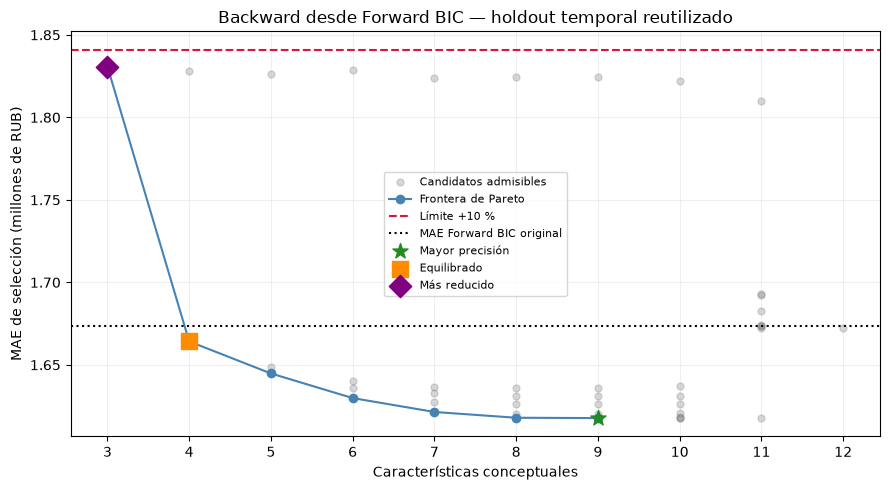

In [29]:
filas_comparacion_backward=[{"Modelo":"Forward BIC","Características":len(caracteristicas_iniciales_backward),
    "Columnas OLS":len(columnas_iniciales_backward),"MAE (RUB)":mae_referencia_backward,"Deterioro vs. BIC":0.0}]
for rol,r in resultados_backward.items():
    registro=r["registro"]
    filas_comparacion_backward.append({"Modelo":"Backward — "+etiquetas_backward[rol],"Características":registro["n_caracteristicas"],
        "Columnas OLS":registro["n_columnas_OLS"],"MAE (RUB)":registro["metricas"]["validation_mae_rub"],"Deterioro vs. BIC":registro["deterioro_pct"]})
comparacion_backward=pd.DataFrame(filas_comparacion_backward)
presencia_backward=pd.DataFrame([{"Característica":c,"Forward BIC":"Sí",**{
    etiquetas_backward[rol]:"Sí" if c in r["registro"]["caracteristicas"] else "No" for rol,r in resultados_backward.items()}}
    for c in caracteristicas_iniciales_backward])
for titulo,tabla in [("Resultados de selección",comparacion_backward),("Características conservadas",presencia_backward)]:
    texto="### "+titulo+"\n\n| "+" | ".join(tabla.columns)+" |\n| "+" | ".join(["---"]*len(tabla.columns))+" |\n"
    for fila in tabla.itertuples(index=False,name=None):
        texto+="| "+" | ".join(f"{v:,.3f}" if isinstance(v,float) else str(v) for v in fila)+" |\n"
    display(Markdown(texto))
display(Markdown("`Deterioro vs. BIC` se expresa en porcentaje; un valor negativo indica menor error que la referencia."))
fig_backward,ax=plt.subplots(figsize=(9,5))
ax.scatter(admisibles_max_backward.n_caracteristicas,admisibles_max_backward.mae_rub/1e6,s=25,alpha=.3,color="gray",label="Candidatos admisibles")
ax.plot(frontera_pareto_backward.n_caracteristicas,frontera_pareto_backward.mae_rub/1e6,color="steelblue",marker="o",label="Frontera de Pareto")
ax.axhline(limite_max_backward/1e6,color="crimson",linestyle="--",label="Límite +10 %")
ax.axhline(mae_referencia_backward/1e6,color="black",linestyle=":",label="MAE Forward BIC original")
for (rol,r),color,marca in zip(resultados_backward.items(),["forestgreen","darkorange","purple"],["*","s","D"]):
    registro=r["registro"]
    ax.scatter(registro["n_caracteristicas"],registro["metricas"]["validation_mae_rub"]/1e6,s=130,color=color,marker=marca,zorder=5,label=etiquetas_backward[rol])
ax.set(xlabel="Características conceptuales",ylabel="MAE de selección (millones de RUB)",title="Backward desde Forward BIC — holdout temporal reutilizado")
ax.set_xticks(np.arange(int(admisibles_max_backward.n_caracteristicas.min()),int(admisibles_max_backward.n_caracteristicas.max())+1))
ax.grid(alpha=.2);ax.legend(fontsize=8);fig_backward.tight_layout();plt.show()


## 26. Registro de los compromisos en DagsHub y MLflow

Solo se registran los roles diferentes y justificables encontrados; no se fabrican runs duplicados para completar tres. Se usa el experimento existente `Propiedades_Nuevas_OLS` y se identifican expresamente las métricas temporales como **selección sobre un holdout reutilizado**, no como generalización independiente. Los valores `validation_*` mantienen el esquema de nombres del proyecto, con esa interpretación declarada en parámetros, etiquetas y artefactos.

Los modelos guardados se ajustan con todo Train; su smearing para futuras predicciones se guarda por separado del smearing usado en cada evaluación de selección. Se registran listas conceptuales, correspondencia con columnas, comparación, tolerancias, presencia, trayectoria resumida y frontera de Pareto, sin tablas exhaustivas en el notebook. Se verifican parámetros, métricas, artefactos y modelo recuperado mediante predicciones de Train, nunca de Test. Los runs históricos de Forward BIC y baseline se conservan intactos.


In [30]:
import mlflow.statsmodels
assert mlflow.get_tracking_uri().rstrip("/")==tracking_uri_dagshub and mlflow.active_run() is None
experimento_backward=mlflow.set_experiment("Propiedades_Nuevas_OLS")
assert experimento_backward.experiment_id==run_origen_backward.info.experiment_id
nombres_runs_backward={"MenorMAE":"Backward_MenorMAE_LogPrice","Equilibrado":"Backward_Equilibrado_LogPrice","MinFeatures":"Backward_MinFeatures_LogPrice"}
versiones_backward={p:version(p) for p in ["statsmodels","numpy","pandas","scipy","mlflow"]}
notebook_backward=raiz_proyecto/"Ventas"/"Propiedades_Nuevas"/"Modelo_OLS.ipynb"
codigo_backward=["".join(c["source"]) for c in json.loads(notebook_backward.read_text(encoding="utf-8"))["cells"] if c["cell_type"]=="code"]
sha_codigo_backward=hashlib.sha256("\n".join(codigo_backward).encode("utf-8")).hexdigest()
git_backward=subprocess.run(["git","rev-parse","HEAD"],cwd=raiz_proyecto,capture_output=True,text=True)
commit_backward=git_backward.stdout.strip() if git_backward.returncode==0 else "no_disponible"
git_dirty_backward=bool(subprocess.run(["git","status","--porcelain"],cwd=raiz_proyecto,capture_output=True,text=True).stdout.strip())
registros_mlflow_backward={}
verificaciones_backward=[]
for rol,r in resultados_backward.items():
    registro,modelo=r["registro"],r["modelo"]
    parametros={"algoritmo":"Backward Selection","modelo_origen":"Forward BIC","origen_run_id":run_origen_backward_id,
        "rol":rol,"tolerancia_aplicada_pct":r["tolerancia"],"tolerancia_max_pct":10,"grid_tolerancias":"0..10_incremento_1pct",
        "mae_referencia_original_rub":mae_referencia_backward,"caracteristicas_iniciales":len(caracteristicas_iniciales_backward),
        "caracteristicas_seleccionadas":json.dumps(registro["caracteristicas"],ensure_ascii=False),
        "n_caracteristicas":registro["n_caracteristicas"],"n_columnas_OLS":registro["n_columnas_OLS"],
        "n_parametros_estimables":int(modelo.model.rank),"target":"log_price_rub","n_train":len(X_train),"n_folds":len(folds_backward),
        "protocolo_validacion":protocolo_validacion_baseline["tipo"],"fecha_inicio_validacion":protocolo_validacion_baseline["inicio_validacion"],
        "alcance_metricas":"seleccion_holdout_reutilizado_no_generalizacion_independiente",
        "test_evaluado":False,"busqueda":"voraz_hasta_intercepto_sin_detener_por_tolerancia",
        "regla_equilibrado":"distancia_euclidea_ideal_normalizada_pesos_iguales_pareto_interior",
        "n_subconjuntos_evaluados":len(evaluaciones_backward),"n_puntos_pareto":len(frontera_pareto_backward),
        "retransformacion":"exp_por_smearing_Duan_estimado_en_ajuste","smearing_Train":r["factor_smearing_Train"],
        "dataset":"newbuilds_ols.csv","dataset_sha256":run_origen_backward.data.params["dataset_sha256"],
        "codigo_sha256":sha_codigo_backward,"git_commit":commit_backward,"git_dirty":git_dirty_backward,
        **{f"version_{p}":v for p,v in versiones_backward.items()}}
    coeficientes=pd.DataFrame({"columna":modelo.params.index,"coef_log":modelo.params.to_numpy(),
        "error_estandar":modelo.bse.to_numpy(),"p_value":modelo.pvalues.to_numpy()})
    textos={"resumen_OLS_log.txt":modelo.summary().as_text(),"coeficientes_log.csv":coeficientes.to_csv(index=False),
        "comparacion_modelos.csv":comparacion_backward.to_csv(index=False),"tolerancias.csv":tabla_tolerancias_backward.to_csv(index=False),
        "presencia_caracteristicas.csv":presencia_backward.to_csv(index=False),"trayectoria_resumida.csv":historial_backward.to_csv(index=False),
        "frontera_pareto.csv":frontera_pareto_backward.drop(columns="caracteristicas").to_csv(index=False),
        "metricas_folds_seleccion.csv":pd.DataFrame(registro["folds"]).to_csv(index=False),
        "alcance_metricas.md":"Métricas de selección sobre el holdout reutilizado para elegir subconjuntos y roles. No son estimaciones independientes de generalización. La lista inicial de 12 características fue seleccionada con todo Train, incluido el holdout. El MAE de referencia original corresponde al procedimiento Forward BIC (su selección interna podía tener otro subconjunto). Test permanece reservado."}
    jsons={"caracteristicas_seleccionadas.json":{"rol":rol,"subset_id":registro["subset_id"],"caracteristicas":registro["caracteristicas"],
        "columnas_OLS":registro["columnas"],"tolerancia_pct":r["tolerancia"],"deterioro_real_pct":registro["deterioro_pct"]},
        "caracteristicas_columnas_OLS.json":{c:grupos_backward[c] for c in registro["caracteristicas"]},
        "universo_inicial.json":grupos_backward,
        "metricas_seleccion.json":{"interpretacion":"seleccion_no_generalizacion_independiente","metricas":r["metricas"],"folds":registro["folds"]},
        "protocolo.json":protocolo_validacion_baseline,
        "referencia_origen.json":{"run_id":run_origen_backward_id,"mae_original":mae_referencia_backward,
            "caracteristicas_definitivas_origen":caracteristicas_iniciales_backward,
            "reevaluacion_fija_inicial":inicial_backward["metricas"],"limite_10pct":limite_max_backward},
        "criterio_compromisos.json":{"regla":"pareto_y_distancia_normalizada_al_ideal_pesos_iguales_entre_interiores",
            "elegidos":elegidos_backward,"ganadores_por_tolerancia":{str(k):v for k,v in ganadores_tolerancias_backward.items()},
            "sin_evaluacion_test":True,"no_evaluables":no_evaluables_backward},
        "retransformacion.json":{"metodo":"exp(pred_log)*factor_smearing","factor_Train":r["factor_smearing_Train"],
            "factores_ajuste_por_fold":[f["smearing"] for f in registro["folds"]],"usa_test":False},
        "preparacion_fold.json":{"medianas_ajuste":{k:float(v) for k,v in parametros_validacion["medianas"].items()},
            "constantes_ajuste":parametros_validacion["constantes"],"dependencias_ajuste":parametros_validacion["dependientes"],
            "fit_solo_ajuste":True}}
    diseno_train=pd.DataFrame({"const":np.ones(len(X_train))},index=X_train.index).join(X_train[registro["columnas"]])
    assert diseno_train.columns.tolist()==modelo.model.exog_names
    with mlflow.start_run(experiment_id=experimento_backward.experiment_id,run_name=nombres_runs_backward[rol],
        tags={"segmento":"propiedades_nuevas","familia_modelo":"OLS","iteracion":"backward","target":"log_price_rub",
              "seleccion":"backward_por_caracteristicas","rol":rol,"origen":"Forward_BIC","test_evaluado":"false",
              "alcance_metricas":"seleccion_no_generalizacion_independiente"}) as run:
        mlflow.log_params(parametros);mlflow.log_metrics(r["metricas"])
        for nombre,texto in textos.items():mlflow.log_text(texto,nombre)
        for nombre,contenido in jsons.items():mlflow.log_dict(contenido,nombre)
        mlflow.log_figure(fig_backward,"compromisos_caracteristicas_MAE.png")
        info_modelo=mlflow.statsmodels.log_model(deepcopy(modelo),name="modelo",remove_data=True,
            signature=infer_signature(diseno_train.head(5),modelo.predict(diseno_train.head(5))),
            pip_requirements=[f"{p}=={v}" for p,v in versiones_backward.items()])
        info_registro={"run_id":run.info.run_id,"experiment_id":experimento_backward.experiment_id,
            "model_uri":info_modelo.model_uri,"model_id":info_modelo.model_id}
        mlflow.log_dict(info_registro,"modelo_uri.json")
    registros_mlflow_backward[rol]=info_registro
    remoto=cliente_baseline.get_run(info_registro["run_id"])
    assert remoto.info.status=="FINISHED" and remoto.data.tags["mlflow.runName"]==nombres_runs_backward[rol]
    assert remoto.info.experiment_id==experimento_backward.experiment_id
    for k,v in parametros.items():assert remoto.data.params[k]==str(v)
    for k,v in r["metricas"].items():assert math.isclose(remoto.data.metrics[k],v,rel_tol=1e-10,abs_tol=1e-12)
    assert not any(k.lower().startswith("test_") or k.lower().endswith("_test") for k in remoto.data.metrics)
    assert remoto.data.tags["alcance_metricas"]=="seleccion_no_generalizacion_independiente"
    assert set(textos)|set(jsons)|{"compromisos_caracteristicas_MAE.png","modelo_uri.json"} <= {a.path for a in cliente_baseline.list_artifacts(info_registro["run_id"])}
    with TemporaryDirectory(prefix="backward_verificacion_") as temporal:
        for nombre,esperado in jsons.items():
            descargado=cliente_baseline.download_artifacts(info_registro["run_id"],nombre,dst_path=temporal)
            assert json.loads(Path(descargado).read_text(encoding="utf-8"))==esperado
        for nombre,esperado in textos.items():
            descargado=cliente_baseline.download_artifacts(info_registro["run_id"],nombre,dst_path=temporal)
            if nombre.endswith(".csv"):
                pd.testing.assert_frame_equal(pd.read_csv(descargado),pd.read_csv(StringIO(esperado)),check_exact=False,rtol=1e-12,atol=1e-12)
            else:assert Path(descargado).read_text(encoding="utf-8").splitlines()==esperado.splitlines()
        grafico=cliente_baseline.download_artifacts(info_registro["run_id"],"compromisos_caracteristicas_MAE.png",dst_path=temporal)
        assert Path(grafico).stat().st_size>0
        recuperado=mlflow.statsmodels.load_model(info_registro["model_uri"],dst_path=temporal)
        assert recuperado.model.exog_names==modelo.model.exog_names
        np.testing.assert_allclose(recuperado.predict(diseno_train.head(20)),modelo.predict(diseno_train.head(20)),rtol=1e-10,atol=1e-10)
    assert cliente_baseline.get_logged_model(info_registro["model_id"]).source_run_id==info_registro["run_id"]
    url=tracking_uri_dagshub+"/#/experiments/"+info_registro["experiment_id"]+"/runs/"+info_registro["run_id"]
    verificaciones_backward.append({"rol":rol,"run_id":info_registro["run_id"],"estado":"FINISHED","verificado":True,"url":url})
    print(nombres_runs_backward[rol],"FINISHED; parámetros, métricas, artefactos y modelo recuperados:",url)
assert len({r["run_id"] for r in registros_mlflow_backward.values()})==len(resultados_backward)
assert not {r["run_id"] for r in registros_mlflow_backward.values()} & set(snapshots_remotos_backward)
for run_id,esperado in snapshots_remotos_backward.items():
    ref=cliente_baseline.get_run(run_id)
    assert {"params":dict(ref.data.params),"metrics":dict(ref.data.metrics),"tags":dict(ref.data.tags),
        "estado":ref.info.status,"artefactos":sorted(a.path for a in cliente_baseline.list_artifacts(run_id))}==esperado
for k,v in {"X_train":X_train,"X_test":X_test,"y_train":y_train,"y_test":y_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest()==huellas_backward[k]
assert mlflow.active_run() is None
print("Modelos históricos, matrices y Test intactos; registros Backward verificados.")


🏃 View run Backward_MenorMAE_LogPrice at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/8d6219c5279e4d60a7949fea73bd063b
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Backward_MenorMAE_LogPrice FINISHED; parámetros, métricas, artefactos y modelo recuperados: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/8d6219c5279e4d60a7949fea73bd063b
🏃 View run Backward_Equilibrado_LogPrice at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/75c51044ea4a4390a9373881a315b5c1
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Backward_Equilibrado_LogPrice FINISHED; parámetros, métricas, artefactos y modelo recuperados: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/75c51044ea4a4390a9373881a315b5c1
🏃 View run Backward_MinFeatures_LogPrice at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/7229786ac89d4ca8af59d9395feb4fc7
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Backward_MinFeatures_LogPrice FINISHED; parámetros, métricas, artefactos y modelo recuperados: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/7229786ac89d4ca8af59d9395feb4fc7
Modelos históricos, matrices y Test intactos; registros Backward verificados.


## 27. Conclusiones y modelos disponibles

Los compromisos siguientes se eligieron automáticamente entre candidatos no dominados dentro del límite del 10 %. Se informa el error respecto de la referencia original, sin acumular incrementos entre etapas. Los modelos y sus subconjuntos permanecen en `modelos_backward` y `resultados_backward`; todos los candidatos y el camino están en `evaluaciones_backward`, `cache_backward` e `historial_backward`.

El error es de selección sobre el holdout reutilizado. El gráfico y las tablas no prueban rendimiento futuro; Test continúa reservado. La búsqueda voraz y la frontera entre candidatos evaluados no garantizan el óptimo global. Esta iteración finaliza sin otros algoritmos ni nuevos experimentos.


In [31]:
for rol,r in resultados_backward.items():
    registro=r["registro"]
    eliminadas=[c for c in caracteristicas_iniciales_backward if c not in registro["caracteristicas"]]
    error_adicional=registro["metricas"]["validation_mae_rub"]-mae_referencia_backward
    display(Markdown(f"**{etiquetas_backward[rol]}:** {registro['n_caracteristicas']} características, {registro['n_columnas_OLS']} columnas OLS y MAE de selección **{registro['metricas']['validation_mae_rub']:,.2f} RUB**. Diferencia frente a Forward BIC: **{error_adicional:+,.2f} RUB ({registro['deterioro_pct']:+.3f} %)**; primera tolerancia que lo admite: {r['tolerancia']} %. Se eliminaron: {', '.join(eliminadas) if eliminadas else 'ninguna'}."))
for verificacion in verificaciones_backward:
    display(Markdown(f"[{nombres_runs_backward[verificacion['rol']]}]({verificacion['url']}) — FINISHED, modelo y artefactos verificados."))
print("Sin evaluación de Test, modificaciones del CSV ni eliminación de observaciones.")


**Mayor precisión:** 9 características, 118 columnas OLS y MAE de selección **1,617,737.87 RUB**. Diferencia frente a Forward BIC: **-55,896.00 RUB (-3.340 %)**; primera tolerancia que lo admite: 0 %. Se eliminaron: listing_month, subsidized_mortgage, metro_year_opened.

**Equilibrado:** 4 características, 113 columnas OLS y MAE de selección **1,664,212.31 RUB**. Diferencia frente a Forward BIC: **-9,421.57 RUB (-0.563 %)**; primera tolerancia que lo admite: 0 %. Se eliminaron: listing_month, subsidized_mortgage, metro_to_center_km, nearest_metro_km, lat, floor, metro_year_opened, total_floors.

**Más reducido:** 3 características, 112 columnas OLS y MAE de selección **1,830,837.53 RUB**. Diferencia frente a Forward BIC: **+157,203.65 RUB (+9.393 %)**; primera tolerancia que lo admite: 10 %. Se eliminaron: listing_year, listing_month, subsidized_mortgage, metro_to_center_km, nearest_metro_km, lat, floor, metro_year_opened, total_floors.

[Backward_MenorMAE_LogPrice](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/8d6219c5279e4d60a7949fea73bd063b) — FINISHED, modelo y artefactos verificados.

[Backward_Equilibrado_LogPrice](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/75c51044ea4a4390a9373881a315b5c1) — FINISHED, modelo y artefactos verificados.

[Backward_MinFeatures_LogPrice](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/7229786ac89d4ca8af59d9395feb4fc7) — FINISHED, modelo y artefactos verificados.

Sin evaluación de Test, modificaciones del CSV ni eliminación de observaciones.


## Evaluación final sobre Test: subconjuntos congelados

Se recuperan las listas definitivas y las métricas históricas registradas, sin repetir Forward ni Backward. Se reutilizan las matrices preparadas: 6.400 filas Train y 1.600 Test, ordenadas por fecha e ID. Los bloques categóricos ingresan completos; el intercepto no se cuenta entre las columnas OLS.

Cada subconjunto se reajusta exclusivamente con todo Train. La retransfomación permanece fija: `exp(predicción_log) × media(exp(residuo_Train))` (smearing de Duan). Test no participa en ajustes, codificaciones, imputaciones ni decisiones de selección.

Los MAE históricos de Backward son métricas de selección sobre un holdout reutilizado; el MAE Forward corresponde al procedimiento de selección interna original. Se conservan tal como fueron registrados, con esta limitación de comparabilidad. Test aporta una evaluación posterior común a los tres subconjuntos.


In [32]:
from IPython.display import Markdown
from tempfile import TemporaryDirectory
from copy import deepcopy
from mlflow.models import infer_signature
from threadpoolctl import threadpool_limits
import math

assert (len(X_train),len(X_test)) == (6400,1600)
assert X_train.columns.equals(X_test.columns)
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
# Referencias inmutables a los resultados ya registrados; no se ejecuta selección.
fuentes_test_final = {
    'Forward BIC': ('af758e48730d4a75ae0e18bb8168d241','Test_Final_Forward_BIC',12,122),
    'Backward — Mayor precisión': ('eb073b96f51c4f1fb9cc77f7cbafa900','Test_Final_Backward_Precision',9,118),
    'Backward — Equilibrado': ('bb98ead9148f4e75b08628394d890937','Test_Final_Backward_Equilibrado',4,113)}
congelados_test_final = {}
snapshots_test_final = {}
huellas_test_final = {k:hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest()
    for k,v in {'X_train':X_train,'X_test':X_test,'y_train':y_train,'y_test':y_test,
                'precio_train':price_rub_train,'precio_test':price_rub_test}.items()}
for nombre,(run_id,nombre_run,n_features,n_cols) in fuentes_test_final.items():
    remoto = cliente_baseline.get_run(run_id)
    assert remoto.info.status == 'FINISHED'
    assert remoto.data.params['dataset_sha256'] == hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
    assert cliente_baseline.get_experiment(remoto.info.experiment_id).name == 'Propiedades_Nuevas_OLS'
    snapshots_test_final[run_id] = {'params':dict(remoto.data.params),'metrics':dict(remoto.data.metrics),
        'tags':dict(remoto.data.tags),'status':remoto.info.status,
        'artefactos':sorted(a.path for a in cliente_baseline.list_artifacts(run_id))}
    es_forward = nombre == 'Forward BIC'
    archivo_seleccion = 'seleccion_forward.json' if es_forward else 'caracteristicas_seleccionadas.json'
    archivo_protocolo = 'validacion.json' if es_forward else 'protocolo.json'
    with TemporaryDirectory(prefix='test_origen_') as temporal:
        originales = {}
        for archivo in [archivo_seleccion,'caracteristicas_columnas_OLS.json',archivo_protocolo]:
            local = cliente_baseline.download_artifacts(run_id,archivo,dst_path=temporal)
            originales[archivo] = json.loads(Path(local).read_text(encoding='utf-8'))
    seleccion = originales[archivo_seleccion]
    features = seleccion['seleccionadas' if es_forward else 'caracteristicas']
    columnas = seleccion['columnas_OLS']
    mapa = {c:diccionario_caracteristicas[c].copy() for c in features}
    assert all(originales['caracteristicas_columnas_OLS.json'][c] == mapa[c] for c in features)
    assert columnas == [v for c in features for v in mapa[c]]
    assert (len(features),len(columnas)) == (n_features,n_cols)
    assert len(set(columnas)) == n_cols and set(columnas).issubset(X_train.columns)
    protocolo = originales[archivo_protocolo]
    if es_forward: protocolo = protocolo['protocolo']
    assert protocolo == protocolo_validacion_baseline
    congelados_test_final[nombre] = {'origen_run_id':run_id,'nombre_run':nombre_run,
        'caracteristicas':features,'columnas_OLS':columnas,'mapa':mapa,
        'validation_mae_rub':float(remoto.data.metrics['validation_mae_rub']),
        'seleccion_original':'Forward BIC' if es_forward else 'Backward con tolerancia progresiva',
        'dataset_sha256':remoto.data.params['dataset_sha256']}
print('Tres subconjuntos recuperados y verificados contra sus artefactos históricos.')
print('Corte original:',df_train.date_posted_dt.max().date(),'; desempate por ID; complejos compartidos:',len(complejos_compartidos))


Tres subconjuntos recuperados y verificados contra sus artefactos históricos.
Corte original: 2025-04-05 ; desempate por ID; complejos compartidos: 250


### Ajuste definitivo y predicción en rublos

Se conserva el orden de columnas de cada modelo histórico. Las correcciones de retransfomación se estiman con los residuos de sus respectivos ajustes sobre Train. Las predicciones y los identificadores de Test permanecen en memoria.


In [33]:
resultados_test_final = {}
filas_test_final = []
with threadpool_limits(limits=1,user_api='blas'):
    for nombre,config in congelados_test_final.items():
        columnas = config['columnas_OLS']
        a = pd.DataFrame({'const':np.ones(len(X_train))},index=X_train.index).join(X_train[columnas])
        b = pd.DataFrame({'const':np.ones(len(X_test))},index=X_test.index).join(X_test[columnas])
        assert a.columns.equals(b.columns) and a.index.equals(y_train.index) and b.index.equals(y_test.index)
        assert np.isfinite(a.to_numpy()).all() and np.isfinite(b.to_numpy()).all()
        modelo = sm.OLS(y_train,a,missing='raise').fit()
        assert modelo.model.rank == len(columnas)+1
        factor = float(np.exp(modelo.resid).mean())
        pred_log = modelo.predict(b)
        pred_rub = np.exp(pred_log)*factor
        assert len(pred_rub) == 1600 and np.isfinite(pred_rub).all() and pred_rub.gt(0).all()
        metricas = {'test_mae_rub':float(mean_absolute_error(price_rub_test,pred_rub)),
            'test_rmse_rub':float(np.sqrt(mean_squared_error(price_rub_test,pred_rub))),
            'test_r2_rub':float(r2_score(price_rub_test,pred_rub)),
            'validation_mae_rub':config['validation_mae_rub']}
        metricas['mae_test_vs_validation_pct'] = 100*(metricas['test_mae_rub']/metricas['validation_mae_rub']-1)
        resultados_test_final[nombre] = {'config':config,'modelo':modelo,'smearing_Train':factor,
            'metricas':metricas,'diseno_train':a,
            'predicciones_test':metadatos_test.assign(price_rub_real=price_rub_test,
                prediccion_log=pred_log,prediccion_rub=pred_rub)}
        filas_test_final.append({'Modelo':nombre,'Características':len(config['caracteristicas']),
            'Columnas OLS':len(columnas),'MAE Validación (RUB)':metricas['validation_mae_rub'],
            'MAE Test (RUB)':metricas['test_mae_rub'],'RMSE Test (RUB)':metricas['test_rmse_rub'],
            'R² Test':metricas['test_r2_rub']})
comparacion_test_final = pd.DataFrame(filas_test_final)
mae_forward_test_final = resultados_test_final['Forward BIC']['metricas']['test_mae_rub']
for r in resultados_test_final.values():
    r['metricas']['mae_test_vs_forward_bic_pct'] = 100*(r['metricas']['test_mae_rub']/mae_forward_test_final-1)
# Una sola tabla de comparación, en Markdown; se reutiliza como artefacto remoto.
lineas_tabla_test_final = ['| '+' | '.join(comparacion_test_final.columns)+' |',
                         '|---|---|---|---|---|---|---|']
for fila in comparacion_test_final.to_dict('records'):
    valores = [fila['Modelo'],str(fila['Características']),str(fila['Columnas OLS'])]
    valores += [f'{fila[c]:,.0f}'.replace(',','.') for c in ['MAE Validación (RUB)','MAE Test (RUB)','RMSE Test (RUB)']]
    valores += [f"{fila['R² Test']:.4f}"]
    lineas_tabla_test_final.append('| '+' | '.join(valores)+' |')
tabla_markdown_test_final = chr(10).join(lineas_tabla_test_final)
display(Markdown(tabla_markdown_test_final))
for nombre,r in resultados_test_final.items():
    m = r['metricas']
    print(f"{nombre}: MAE Test vs Forward BIC {m['mae_test_vs_forward_bic_pct']:+.2f} %; vs validación {m['mae_test_vs_validation_pct']:+.2f} %.")


| Modelo | Características | Columnas OLS | MAE Validación (RUB) | MAE Test (RUB) | RMSE Test (RUB) | R² Test |
|---|---|---|---|---|---|---|
| Forward BIC | 12 | 122 | 1.673.634 | 1.707.248 | 2.667.095 | 0.9087 |
| Backward — Mayor precisión | 9 | 118 | 1.617.738 | 1.813.603 | 2.820.655 | 0.8979 |
| Backward — Equilibrado | 4 | 113 | 1.664.212 | 1.844.177 | 2.842.103 | 0.8964 |

Forward BIC: MAE Test vs Forward BIC +0.00 %; vs validación +2.01 %.
Backward — Mayor precisión: MAE Test vs Forward BIC +6.23 %; vs validación +12.11 %.
Backward — Equilibrado: MAE Test vs Forward BIC +8.02 %; vs validación +10.81 %.


### Registro y verificación en DagsHub / MLflow

Se crean tres runs nuevos en `Propiedades_Nuevas_OLS`. Se registran métricas, listas y bloques congelados, modelo reajustado, retransfomación y tabla final. Se verifica la recuperación remota de los artefactos y del modelo, y se comprueba que los runs de origen permanecen intactos.


In [34]:
import mlflow.statsmodels
assert mlflow.get_tracking_uri().rstrip('/') == tracking_uri_dagshub and mlflow.active_run() is None
experimento_test_final = mlflow.set_experiment('Propiedades_Nuevas_OLS')
assert experimento_test_final.experiment_id == '3'
versiones_test_final = {p:version(p) for p in ['statsmodels','numpy','pandas','scipy','mlflow']}
ruta_notebook_test_final = raiz_proyecto/'Ventas'/'Propiedades_Nuevas'/'Modelo_OLS.ipynb'
codigo_test_final = [ ''.join(c['source']) for c in json.loads(ruta_notebook_test_final.read_text(encoding='utf-8'))['cells'] if c['cell_type']=='code']
sha_codigo_test_final = hashlib.sha256(chr(10).join(codigo_test_final).encode('utf-8')).hexdigest()
registros_test_final = {}
for nombre,r in resultados_test_final.items():
    config,modelo = r['config'],r['modelo']
    parametros = {'modelo':'OLS','target':'log_price_rub','seleccion_original':config['seleccion_original'],
        'origen_run_id':config['origen_run_id'],'n_caracteristicas':len(config['caracteristicas']),
        'n_columnas_OLS':len(config['columnas_OLS']),'intercepto':True,'n_train':len(X_train),'n_test':len(X_test),
        'protocolo_particion':'cronologico_80_20_orden_fecha_id_sin_cambios',
        'fecha_fin_train':df_train.date_posted_dt.max().date().isoformat(),
        'fecha_inicio_test':df_test.date_posted_dt.min().date().isoformat(),
        'retransformacion':'exp(pred_log)*mean(exp(residuo_Train)); smearing_Duan',
        'smearing_Train':r['smearing_Train'],'ajuste_correccion':'solo_Train',
        'dataset_sha256':config['dataset_sha256'],'codigo_sha256':sha_codigo_test_final,
        **{f'version_{p}':v for p,v in versiones_test_final.items()}}
    jsons = {'caracteristicas_seleccionadas.json':{'caracteristicas':config['caracteristicas'],'columnas_OLS':config['columnas_OLS'],
                'origen_run_id':config['origen_run_id']},
        'caracteristicas_columnas_OLS.json':config['mapa'],
        'metricas.json':r['metricas'],
        'retransformacion.json':{'metodo':'exp(pred_log)*factor_smearing','factor_Train':r['smearing_Train'],
            'estimado_con':'6400 observaciones Train; residuos del modelo definitivo','usa_test_para_ajuste':False},
        'protocolo.json':{'particion':'80/20 cronológica por fecha e ID','n_train':6400,'n_test':1600,
            'complejos_compartidos':len(complejos_compartidos),'validacion_historica':protocolo_validacion_baseline,
            'transformaciones':'matrices existentes; sin recalcular parámetros con Test',
            'seleccion_con_test':False}}
    textos = {'comparacion_final.md':tabla_markdown_test_final,
        'comparacion_final.csv':comparacion_test_final.to_csv(index=False),
        'resumen_OLS_Train.txt':modelo.summary().as_text(),
        'alcance.md':'Evaluación final descriptiva sobre Test reservado. Los MAE de validación se conservan del run de origen. Backward reutilizó el holdout para selección; Forward validó su procedimiento interno. No son estimaciones independientes y equivalentes de los tres subconjuntos definitivos. Hay complejos compartidos entre Train y Test: se evalúan anuncios posteriores, no exclusivamente complejos nuevos. No se vuelve a seleccionar ni ajustar usando Test.'}
    a = r['diseno_train']
    with mlflow.start_run(experiment_id=experimento_test_final.experiment_id,run_name=config['nombre_run'],
        tags={'segmento':'propiedades_nuevas','familia_modelo':'OLS','iteracion':'test_final',
              'origen_run_id':config['origen_run_id'],'target':'log_price_rub','seleccion_con_test':'false'}) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics(r['metricas'])
        for archivo,contenido in jsons.items(): mlflow.log_dict(contenido,archivo)
        for archivo,contenido in textos.items(): mlflow.log_text(contenido,archivo)
        info = mlflow.statsmodels.log_model(deepcopy(modelo),name='modelo',remove_data=True,
            signature=infer_signature(a.head(5),modelo.predict(a.head(5))),
            pip_requirements=[f'{p}=={v}' for p,v in versiones_test_final.items()])
        registro = {'run_id':run.info.run_id,'model_uri':info.model_uri,'model_id':info.model_id,
            'experiment_id':experimento_test_final.experiment_id}
        mlflow.log_dict(registro,'modelo_uri.json')
    registros_test_final[nombre] = registro
    remoto = cliente_baseline.get_run(registro['run_id'])
    assert remoto.info.status == 'FINISHED' and remoto.data.tags['mlflow.runName'] == config['nombre_run']
    for k,v in parametros.items(): assert remoto.data.params[k] == str(v)
    for k,v in r['metricas'].items(): assert math.isclose(remoto.data.metrics[k],v,rel_tol=1e-10,abs_tol=1e-12)
    assert set(jsons)|set(textos)|{'modelo_uri.json'} <= {a.path for a in cliente_baseline.list_artifacts(registro['run_id'])}
    with TemporaryDirectory(prefix='test_verificacion_') as temporal:
        for archivo,contenido in {**jsons,'modelo_uri.json':registro}.items():
            local = cliente_baseline.download_artifacts(registro['run_id'],archivo,dst_path=temporal)
            assert json.loads(Path(local).read_text(encoding='utf-8')) == contenido
        for archivo,contenido in textos.items():
            local = cliente_baseline.download_artifacts(registro['run_id'],archivo,dst_path=temporal)
            if archivo.endswith('.csv'):
                from io import StringIO
                pd.testing.assert_frame_equal(pd.read_csv(local),pd.read_csv(StringIO(contenido)),check_exact=False,rtol=1e-12,atol=1e-12)
            else: assert Path(local).read_text(encoding='utf-8').splitlines() == contenido.splitlines()
        recuperado = mlflow.statsmodels.load_model(registro['model_uri'],dst_path=temporal)
        assert recuperado.model.exog_names == a.columns.tolist()
        np.testing.assert_allclose(recuperado.predict(a.head(20)),modelo.predict(a.head(20)),rtol=1e-10,atol=1e-10)
    assert cliente_baseline.get_logged_model(registro['model_id']).source_run_id == registro['run_id']
    print(config['nombre_run'],'FINISHED; métricas, artefactos y modelo recuperados.',registro['run_id'])
assert len({r['run_id'] for r in registros_test_final.values()}) == 3
assert not {r['run_id'] for r in registros_test_final.values()} & set(snapshots_test_final)
for run_id,esperado in snapshots_test_final.items():
    ref = cliente_baseline.get_run(run_id)
    assert {'params':dict(ref.data.params),'metrics':dict(ref.data.metrics),'tags':dict(ref.data.tags),
        'status':ref.info.status,'artefactos':sorted(a.path for a in cliente_baseline.list_artifacts(run_id))} == esperado
for k,v in {'X_train':X_train,'X_test':X_test,'y_train':y_train,'y_test':y_test,
            'precio_train':price_rub_train,'precio_test':price_rub_test}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(v,index=True).values.tobytes()).hexdigest() == huellas_test_final[k]
assert mlflow.active_run() is None
print('Tres nuevos runs verificados. Matrices, objetivos y resultados de origen intactos.')


🏃 View run Test_Final_Forward_BIC at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/663d237b8dcd493bb9a0cfa32a5af50b
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Test_Final_Forward_BIC FINISHED; métricas, artefactos y modelo recuperados. 663d237b8dcd493bb9a0cfa32a5af50b
🏃 View run Test_Final_Backward_Precision at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/1d17a84c26894a1189c4184a84863797
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Test_Final_Backward_Precision FINISHED; métricas, artefactos y modelo recuperados. 1d17a84c26894a1189c4184a84863797
🏃 View run Test_Final_Backward_Equilibrado at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/0ac18b35bb46414da130ec17ef41899f
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3


Test_Final_Backward_Equilibrado FINISHED; métricas, artefactos y modelo recuperados. 0ac18b35bb46414da130ec17ef41899f
Tres nuevos runs verificados. Matrices, objetivos y resultados de origen intactos.


## Conclusiones — Evaluación final sobre Test

Forward BIC conserva el menor error observado. El modelo equilibrado de 4 características sigue siendo competitivo frente al de 9: su MAE Test aumenta apenas **1,69 %**, aunque supera al de referencia en **8,02 %**. Los resultados respaldan el subconjunto de 4 como alternativa más simple si ese incremento de error resulta aceptable; Forward BIC ofrece la mayor precisión observada en Test. Esta lectura mantiene la selección previa y no inicia una nueva selección basada en Test.

La comparación siguiente distingue el modelo equilibrado elegido durante validación del menor error observado en Test.


In [35]:
menor_test_final = min(resultados_test_final,key=lambda k:resultados_test_final[k]['metricas']['test_mae_rub'])
precision_test_final = resultados_test_final['Backward — Mayor precisión']['metricas']['test_mae_rub']
equilibrado_test_final = resultados_test_final['Backward — Equilibrado']['metricas']['test_mae_rub']
brecha_equilibrado_test_final = 100*(equilibrado_test_final/precision_test_final-1)
conclusiones_test_final = [f"El menor MAE observado sobre las 1.600 filas Test corresponde a **{menor_test_final}**: **{resultados_test_final[menor_test_final]['metricas']['test_mae_rub']:,.0f} RUB**."]
for nombre,r in resultados_test_final.items():
    m = r['metricas']
    conclusiones_test_final.append(f"{nombre}: el MAE Test difiere **{m['mae_test_vs_validation_pct']:+.2f} %** del histórico de validación y **{m['mae_test_vs_forward_bic_pct']:+.2f} %** del MAE Test Forward BIC.")
conclusiones_test_final.append(f"El modelo equilibrado conserva 4 características (113 columnas OLS), frente a 9 (118 columnas) del modelo de mayor precisión en validación. Su diferencia relativa de MAE Test frente a este último es **{brecha_equilibrado_test_final:+.2f} %**. La simplificación conceptual es grande, pero district conserva sus 108 dummies: reducir características no equivale a reducir proporcionalmente parámetros.")
conclusiones_test_final.append('Los porcentajes positivos frente a validación indican mayor error en anuncios posteriores; los negativos indican menor error observado. La comparación está condicionada por el distinto alcance de las métricas históricas y por el cambio de período/precios. No constituye por sí sola una prueba causal de deterioro ni una estimación de incertidumbre.')
conclusiones_test_final.append('El compromiso entre simplicidad y precisión se interpreta con estas diferencias, manteniendo como equilibrado el subconjunto de 4 características previamente seleccionado. El menor error de Test se informa como resultado final descriptivo; no se usa para volver a elegir características. La presencia de complejos compartidos limita la conclusión a anuncios posteriores del universo observado, no a complejos residenciales completamente nuevos. La evaluación final termina aquí, sin nuevos experimentos.')
for texto in conclusiones_test_final: display(Markdown(texto))
for nombre,registro in registros_test_final.items():
    url = tracking_uri_dagshub+'/#/experiments/'+registro['experiment_id']+'/runs/'+registro['run_id']
    display(Markdown(f"[{nombre}: run verificado]({url})"))


El menor MAE observado sobre las 1.600 filas Test corresponde a **Forward BIC**: **1,707,248 RUB**.

Forward BIC: el MAE Test difiere **+2.01 %** del histórico de validación y **+0.00 %** del MAE Test Forward BIC.

Backward — Mayor precisión: el MAE Test difiere **+12.11 %** del histórico de validación y **+6.23 %** del MAE Test Forward BIC.

Backward — Equilibrado: el MAE Test difiere **+10.81 %** del histórico de validación y **+8.02 %** del MAE Test Forward BIC.

El modelo equilibrado conserva 4 características (113 columnas OLS), frente a 9 (118 columnas) del modelo de mayor precisión en validación. Su diferencia relativa de MAE Test frente a este último es **+1.69 %**. La simplificación conceptual es grande, pero district conserva sus 108 dummies: reducir características no equivale a reducir proporcionalmente parámetros.

Los porcentajes positivos frente a validación indican mayor error en anuncios posteriores; los negativos indican menor error observado. La comparación está condicionada por el distinto alcance de las métricas históricas y por el cambio de período/precios. No constituye por sí sola una prueba causal de deterioro ni una estimación de incertidumbre.

El compromiso entre simplicidad y precisión se interpreta con estas diferencias, manteniendo como equilibrado el subconjunto de 4 características previamente seleccionado. El menor error de Test se informa como resultado final descriptivo; no se usa para volver a elegir características. La presencia de complejos compartidos limita la conclusión a anuncios posteriores del universo observado, no a complejos residenciales completamente nuevos. La evaluación final termina aquí, sin nuevos experimentos.

[Forward BIC: run verificado](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/663d237b8dcd493bb9a0cfa32a5af50b)

[Backward — Mayor precisión: run verificado](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/1d17a84c26894a1189c4184a84863797)

[Backward — Equilibrado: run verificado](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/0ac18b35bb46414da130ec17ef41899f)

# Conclusiones finales

Este cierre consolida la evidencia ya almacenada en los tres notebooks de Propiedades Nuevas y en sus artefactos históricos. La auditoría del 21 de octubre de 2026 no ejecutó modelos, selección, transformaciones, particiones ni predicciones. Se preservan los resultados y se distingue lo observado en el dataset de lo que puede inferirse sobre el mercado. El detalle de las afirmaciones revisadas y de su trazabilidad está en [el informe de auditoría](Auditoria_Conclusiones_Propiedades_Nuevas.md).

### 1. Primera etapa — Análisis exploratorio e integración

Se examinó `new_builds.csv`, con **8.000 anuncios y 25 variables originales**, correspondientes a **250 complejos residenciales**. Las salidas de calidad registran 8.000 identificadores de anuncio únicos, ausencia de nulos y de duplicados completos. La repetición del complejo es esperable: distintas unidades y publicaciones pueden pertenecer al mismo desarrollo. Los controles físicos no registraron infracciones de los dominios comprobados; esto no acredita la veracidad externa de cada anuncio. [E1–E2]

Los LEFT JOIN con `district_prices_monthly.csv` y `metro_stations.csv` conservaron las 8.000 observaciones y las variables originales, produciendo **41 columnas**, sin duplicación de anuncios ni pérdidas. Se verificó cardinalidad muchos-a-uno con claves auxiliares únicas: mes/distrito/okrug para los indicadores mensuales y estación/línea para metro. Ambas uniones alcanzaron 100 % de correspondencias. La exportación y recarga de `newbuilds_integrado.csv` comprobaron conservación de columnas, valores e interpretación de fechas. Una correspondencia completa no certifica, por sí sola, que el indicador auxiliar estuviera disponible en la fecha de publicación. [E1]

El precio anunciado presenta asimetría a la derecha: media **14.181.281,12 RUB**, mediana **12.410.000 RUB** y rango **1.371.000–79.083.000 RUB**. Los histogramas y boxplots muestran valores extremos; no se interpretaron automáticamente como errores ni se eliminaron anuncios. Las asociaciones marginales con `price_rub` fueron positivas para `total_area` (r≈0,520) y `rooms` (r≈0,474), y negativa para `to_center_km` (r≈−0,508). La superficie y las habitaciones estaban muy relacionadas entre sí (r≈0,917). Las referencias de precios distritales tuvieron correlaciones altas con el precio del anuncio (≈0,669 y 0,668), mientras que la tasa hipotecaria presentó una asociación lineal marginal débil (≈0,091). Son descripciones bivariadas: no identifican efectos causales ni contribuciones independientes al modelo múltiple. [E1]

### 2. Segunda etapa — Transformación y prevención de fugas

Se utilizó **`log_price_rub = ln(price_rub)`**, después de comprobar que los precios eran finitos y positivos. `price_rub` se conservó exclusivamente para interpretación y evaluación en RUB. `price_per_sqm`, calculado a partir del precio y la superficie, quedó fuera de los predictores por fuga directa. Las referencias distritales contemporáneas, variaciones y volúmenes mensuales también se excluyeron: no se acreditó su fecha histórica de difusión y podrían introducir información no disponible al publicar. Sus asociaciones exploratorias no justifican incorporarlas al modelo final. [E2]

Se evitó redundancia financiera conservando `mortgage_rate_at_listing` y excluyendo `avg_mortgage_rate_pct` y `cbr_key_rate_pct`: las dos primeras tasas eran idénticas y el promedio hipotecario difería de la tasa del banco central en una constante de **2,5 puntos porcentuales**. La disponibilidad al publicar de la tasa conservada es una interpretación del campo, sin documentación independiente de su versión histórica. `subsidized_mortgage` se mantuvo como candidata binaria 0/1; no se confundió la constancia en un ajuste interno con su irrelevancia general. [E2–E3]

El calendario se representó mediante `listing_year` y el bloque `listing_month` formado conjuntamente por `listing_month_sin` y `listing_month_cos`. Se crearon `months_to_completion`, aproximando la entrega a diciembre del año declarado, y `relative_floor = floor/total_floors`. El plazo no es una fecha exacta de entrega: se conservaron **315 valores negativos** sin corregirlos automáticamente. Las seis nominales se codificaron con K−1 dummies y referencias lexicográficas explícitas. `district` omitió **Akademichesky** y `complex_class`, **business**. Los identificadores no ingresaron a X: `id` y `complex_id` permanecieron como metadatos; `complex_name` no se utilizó como predictor. [E2]

`nearest_metro_km` representa el mínimo de distancia geográfica Haversine a **104 estaciones/líneas observadas**, con apertura anterior al año del anuncio. El catálogo es parcial, sus aperturas registradas son de 1935–2018 y se supone estabilidad histórica de coordenadas; no representa necesariamente la estación más cercana de toda Moscú, una ruta ni minutos de viaje. `metro_distance_min` se reservó fuera de X por falta de documentación verificable de su significado operativo. Su correlación ≈0,999924 con la distancia a la estación asignada motivó cautela, pero no prueba una conversión de unidades errónea. [E2]

El archivo `newbuilds_ols.csv` conserva **8.000 filas y 160 columnas**: 155 predictoras numéricas y cinco campos reservados —objetivo, precio e identificadores/fecha—, sin pérdida de anuncios. Esta preparación no fue completamente inductiva: el vocabulario categórico y el catálogo de estaciones se definieron con covariables de todo el archivo antes de particionar, aunque sin precios ni frecuencias para elegir niveles. Los tratamientos estadísticos posteriores se aprendieron en entrenamiento. Por ello, la ausencia de uso predictivo de Test no debe confundirse con un aislamiento absoluto de todas sus covariables en la definición inicial del esquema. [E2–E3]

### 3. Tercera etapa — Baseline OLS y alcance de sus diagnósticos

Se mantuvo la partición cronológica de **6.400 anuncios Train y 1.600 Test**, con orden estable por `date_posted_dt` e `id`. Train abarca 01/01/2021–05/04/2025 y Test 05/04/2025–29/04/2026. El día de corte tiene cuatro anuncios en Train y dos en Test; el desempate por ID asegura el 80/20 exacto, pero no acredita el orden real dentro de ese día. Los conjuntos no comparten identificadores de anuncio; **los 250 complejos aparecen en ambos períodos**. El objetivo evaluado es, por tanto, la predicción de anuncios posteriores de un universo de complejos ya observado, sin demostrar generalización a complejos desconocidos. [E3]

El baseline comprendió **24 características conceptuales y 155 columnas OLS**, más intercepto: **156 parámetros estimables** y rango completo. Seno y coseno del mes se consideran un solo bloque conceptual; por eso los 25 campos de entrada previos al agrupamiento no son 25 características de selección. No se requirieron imputaciones efectivas ni exclusiones por dependencia exacta en Train. La validación interna fue un único holdout temporal, con **5.120 anuncios para ajuste y 1.280 para validación**, iniciada el 28/05/2024. Sus tratamientos se aprendieron solo en el ajuste interno; allí `subsidized_mortgage` era constante y no tenía coeficiente propio estimable. [E3]

El ajuste completo obtuvo R² Train en log de **0,965743** y R² ajustado **0,964893**. En validación, las métricas en RUB fueron **MAE 1.745.629,06**, **RMSE 2.670.162,41** y **R² 0,911404**. Se estableció desde el baseline la retransfomación de Duan: `exp(predicción_log) × media(exp(residuo_log_del_ajuste))`. El factor se estimó con el ajuste interno para validar y con todo Train para el modelo definitivo; nunca con Test. Es una corrección global, sin garantía de corregir perfectamente la media condicional ante heterocedasticidad. [E3]

El buen ajuste no implica cumplimiento de los supuestos: Breusch–Pagan registró p≈**1,09×10⁻³¹**, Jarque–Bera p≈**1,43×10⁻³¹** y el VIF máximo fue **743,32**. Se señalaron **342** anuncios con Cook>4/n, **126** con leverage>2p/n y **37** residuos studentizados internos con valor absoluto>3. Son alertas de heterocedasticidad, desviaciones de normalidad, colinealidad e influencia, no reglas de eliminación automática. El baseline guardó errores estándar clásicos y agrupados por complejo; los coeficientes no deben interpretarse exclusivamente mediante inferencia clásica. [E3, E7]

Existe una condición no resuelta: la transformación recomendaba verificar la versión al publicar de `ready_status` y la entrega prevista o excluir sus representaciones del baseline histórico. Este las incluyó sin acreditar esa procedencia. Se conserva el resultado histórico con esa limitación explícita. Esos bloques no forman parte de Forward BIC ni de los dos subconjuntos Backward evaluados en Test, lo que acota esta objeción específica para sus diseños finales. [E2–E4]

### 4. Cuarta etapa — Forward Selection por bloques completos

Forward comenzó en el intercepto e incorporó características completas mediante una búsqueda voraz: minimizar AIC o BIC, o maximizar R² ajustado. Los criterios contabilizan parámetros estimables y no solo nombres conceptuales. Primero se seleccionó dentro de las 5.120 filas del ajuste temporal y se evaluó su procedimiento en las 1.280 siguientes; después se volvió a seleccionar con todo Train para fijar los diseños definitivos. [E4]

Los modelos finales fueron **20 características/149 columnas** para AIC, **12/122** para BIC y **22/153** para R² ajustado. Los MAE históricos respectivos fueron **1.749.158,16**, **1.673.633,88** y **1.747.186,03 RUB**. BIC resultó especialmente conveniente entre los procedimientos comparados: redujo a la mitad las características del baseline, redujo sus columnas un **21,29 %** y mejoró el MAE interno observado un **4,12 %**. No se demostró un óptimo global ni estabilidad en múltiples particiones independientes. [E4]

Es esencial distinguir **10 características/120 columnas seleccionadas por BIC en el ajuste interno** de las **12/122 definitivas con todo Train**. El MAE histórico 1.673.633,88 RUB describe el primer procedimiento; no es una evaluación independiente del subconjunto final fijo. Todo Train incorporó además `floor` y `subsidized_mortgage`. Las doce características definitivas fueron `district`, `total_area`, `complex_class`, `listing_year`, `listing_month`, `subsidized_mortgage`, `metro_to_center_km`, `nearest_metro_km`, `lat`, `floor`, `metro_year_opened` y `total_floors`. Los primeros cuatro bloques ingresaron en ese mismo orden en los tres criterios: evidencia de utilidad predictiva dentro de estas búsquedas, sin equivaler a un ranking de efectos individuales. [E4, E7]

### 5. Quinta etapa — Backward y compromisos de complejidad/error

Backward partió de las doce características definitivas de BIC. Evaluó eliminaciones por bloques completos sobre el mismo holdout, utilizando tolerancias de 0 % a 10 % respecto del **MAE original fijo** de BIC. La reevaluación inicial de las doce dio **1.672.481,78 RUB**, ligeramente distinta del MAE original porque el subconjunto de validación Forward tenía diez características. Se registraron **79 subconjuntos únicos**, un camino de **13 etapas** hasta intercepto y **7 puntos** en la frontera de Pareto admisible. No se exploraron todos los subconjuntos posibles. [E5, E7]

Se conservaron tres representantes: **mayor precisión de selección**, con 9 características/118 columnas y MAE **1.617.737,87 RUB**; **equilibrado**, con 4/113 y MAE **1.664.212,31 RUB**; y **más reducido**, con 3/112 y MAE **1.830.837,53 RUB**. El equilibrado minimizó la distancia al ideal normalizada con pesos iguales entre los puntos interiores de Pareto. Las tolerancias de 0 % a 9 % admitieron como ganador de menor tamaño al de cuatro; la de 10 % permitió el de tres, cuyo error superó la referencia en **9,39 %**. [E5]

El modelo equilibrado contiene **`district`, `total_area`, `complex_class` y `listing_year`**. El más reducido conserva las tres primeras. Backward reutilizó el holdout para decidir y su universo inicial había sido seleccionado con todo Train, incluido ese holdout: sus métricas son **de selección, no validación independiente**. El nombre “mayor precisión” designa su rol entre candidatos Backward; no anticipa el ganador en Test. La búsqueda y Pareto son condicionales al camino y a los candidatos evaluados. [E5]

### 6. Sexta etapa — Evaluación final de subconjuntos congelados

Los diseños de 12, 9 y 4 características se reajustaron con todo Train y se evaluaron sobre las mismas 1.600 filas Test. Se conservaron sus bloques, orden de columnas, intercepto y retransfomación; ninguna corrección se estimó con Test. La tabla reproduce las métricas históricas almacenadas, sin nuevas predicciones. [E6]

| Modelo | Características / columnas OLS | MAE histórico (RUB) | MAE Test (RUB) | RMSE Test (RUB) | R² Test |
|---|---:|---:|---:|---:|---:|
| Forward BIC | 12 / 122 | 1.673.634 | **1.707.248** | 2.667.095 | 0,9087 |
| Backward — Mayor precisión | 9 / 118 | 1.617.738 | 1.813.603 | 2.820.655 | 0,8979 |
| Backward — Equilibrado | 4 / 113 | 1.664.212 | 1.844.177 | 2.842.103 | 0,8964 |

Forward BIC obtuvo el menor MAE Test **entre los tres evaluados**. Respecto de él, el error aumentó **6,23 %** para el modelo de nueve y **8,02 %** para el equilibrado. Este último supera al de nueve en **1,69 %**, equivalente a **30.573,59 RUB** de MAE, y al de referencia en **136.929,22 RUB**. Pasar de doce a cuatro características reduce la complejidad conceptual un **66,67 %**, pero las columnas OLS solo un **7,38 %**: de 122 a 113, sin contar intercepto. Gran parte del diseño sigue concentrada en las 108 dummies de distrito. [E6–E7]

Las brechas Test frente al error histórico fueron **+2,01 %**, **+12,11 %** y **+10,81 %**, respectivamente. BIC presenta la menor brecha relativa observada y todos muestran más error en el período posterior. Sin embargo, la comparación no aísla un deterioro temporal puro: las métricas históricas tienen distinto alcance y las de Backward pueden ser optimistas por reutilización del holdout. No se dispone de una evaluación de incertidumbre que permita declarar diferencias estadísticamente significativas entre sus errores. [E5–E7]

Se mantiene la distinción entre el **equilibrado elegido durante selección** y el **menor error finalmente observado en Test**. El conjunto de tres características no se evaluó en esta comparación Test; no puede atribuírsele un error posterior. La evaluación final informa el resultado de listas previamente congeladas y no inicia una selección retrospectiva. Los runs y artefactos históricos se conservan. [E6]

### 7. Séptima etapa — Características con mayor respaldo de relevancia

La combinación de EDA, trayectorias de selección y coeficientes proporciona el mayor respaldo convergente para **ubicación (`district`), superficie (`total_area`), categoría comercial (`complex_class`) y período de publicación (`listing_year`)**. Esto no demuestra que sean exactamente las cuatro variables de mayor efecto individual ni permite ordenar cuantitativamente todas las características. El aporte de un bloque puede solaparse con otros y depende de los controles presentes. [E1, E4–E5, E7]

Los coeficientes corresponden a `log_price_rub`. Para un contraste Δ, `100 × (exp(β×Δ)−1)` expresa la diferencia porcentual asociada en el precio estimado, manteniendo los demás predictores constantes y usando el mismo factor global de retransfomación. No es un efecto causal. No se comparan coeficientes absolutos de metros cuadrados, años, kilómetros y dummies como si compartieran unidad.

| Característica y significado | Relación observada en EDA | Evidencia de selección | Interpretación de coeficientes ya estimados | Límites de interpretación |
|---|---|---|---|---|
| **`district`: ubicación geográfica** | Diferencias amplias entre distritos: mediana de Arbat 29.958.000 RUB y de Rogovskoye 3.969.000 RUB, sin ajustar por composición. | Primer bloque en los tres Forward; permanece incluso en el compromiso de tres características. | En equilibrado, `district_Arbat` β≈0,637629 implica **+89,20 %** frente a **Akademichesky**, con área, clase y año constantes. Es un ejemplo de contraste, no el efecto de todo el bloque. | Son 108 dummies, sin un coeficiente único. La magnitud cambia con los controles; distrito también resume atributos omitidos. No equivale a prima causal de localización. |
| **`total_area`: superficie total, m²** | Asociación positiva r≈0,520; dispersión y correlación elevada con habitaciones. | Segundo bloque en los tres Forward; permanece en los compromisos de 9, 4 y 3. | β≈0,019226 baseline, 0,018807 BIC y 0,018853 equilibrado. **+10 m²** se asocian con **+21,20 %, +20,69 % y +20,75 %**, respectivamente. | Los signos y órdenes de magnitud son similares, sin demostrar linealidad global del precio ni extrapolación fuera del soporte. El modelo es lineal en log, no en RUB. |
| **`complex_class`: categoría comercial del complejo** | Medianas: economy 10.027.000; comfort 11.753.500; business 16.707.500; premium 22.424.000 RUB. | Tercer bloque en los tres Forward; se conserva en los compromisos principales. | Referencia **business**. En equilibrado: comfort β≈−0,337021 (**−28,61 %**), economy −0,501932 (**−39,46 %**), premium +0,337995 (**+40,21 %**). Los signos son concordantes con baseline y BIC. | Se evalúa como bloque de tres contrastes. Las clases resumen diferencias de calidad y composición; no demuestran el efecto de cambiar una etiqueta comercial. |
| **`listing_year`: año de publicación / contexto temporal** | Las tablas mensuales describen cambios en el tiempo junto con cambios de composición; no aíslan una tendencia causal. | Cuarto bloque en los tres Forward; permanece en 9 y 4 y desaparece en el compromiso de 3. | β≈0,065555 baseline, 0,072890 BIC y 0,059319 equilibrado: un año adicional se asocia con **+6,78 %, +7,56 % y +6,11 %**. | Puede captar tendencia nominal de precios y condiciones temporales del dataset. No prueba que el mero paso del tiempo cause esa valorización ni garantiza que continúe fuera del período observado. |

Los contrastes anteriores proceden de coeficientes históricos, no de nuevas ablaciones ni importancias por permutación. El intervalo clásico del baseline para +10 m² implica aproximadamente **+20,70 % a +21,70 %**. En el equilibrado, los intervalos clásicos publicados del año [0,057; 0,062] y de premium [0,319; 0,357] se traducen aproximadamente en **+5,87 % a +6,40 %** y **+37,58 % a +42,90 %**. Estos últimos límites heredan el redondeo del resumen original. Son intervalos condicionales al diseño, con covarianza no robusta y sin corrección por selección; la heterocedasticidad, la dependencia por complejo y la búsqueda previa limitan su interpretación inferencial. No son intervalos de precio para una propiedad individual. [E7]

Otras variables también aportaron información dentro de los procedimientos. `nearest_metro_km` permaneció en BIC y en el Backward de nueve; sus coeficientes baseline≈−0,027343 y BIC≈−0,020636 corresponden a **−2,70 % y −2,04 % por km**, sujetos a la cobertura parcial y a la colinealidad geográfica. `subsidized_mortgage` se conservó en BIC definitivo, con asociación condicional ≈+6,17 %, aunque su asociación marginal con precio era negativa y no era estimable en el ajuste interno. Su eliminación posterior no acredita ausencia de efecto económico; los errores de selección, la redundancia y el ámbito de estimación son distintos. [E1, E4–E5, E7]

La divergencia entre evidencia marginal y condicional también exige cautela: `rooms` se relacionaba positivamente con el precio, pero su coeficiente baseline fue ≈−0,008022 al controlar superficie y otros atributos; `to_center_km` pasó de r≈−0,508 a β baseline≈+0,006186, con p agrupado por complejo≈0,131. La tasa hipotecaria tuvo p clásico≈0,042 y agrupado≈0,051. No corresponde extraer causalidad ni estabilidad de esos signos o de un umbral de significación. Una dummy como `district_Rogovskoye` cambió de β≈−0,9366 a −0,7658 y −1,3985 entre los tres diseños examinados: los coeficientes individuales geográficos pueden absorber información distinta al cambiar los controles. [E1, E7]

Por tanto, las cuatro características del equilibrado constituyen un **núcleo de información predictiva respaldado de manera convergente**, sin un ranking completo y cuantitativo de importancia. No se dispone de medidas históricas comparables de contribución incremental independiente para todos los bloques ni de pruebas conjuntas robustas almacenadas que permitan sostener ese ranking. No se generan nuevas para completar artificialmente la conclusión.

### 8. Octava etapa — Alcance para la decisión inmobiliaria y cierre

Para los anuncios posteriores estudiados, **Forward BIC ofrece la mayor precisión observada** entre los tres diseños evaluados, con MAE Test de 1.707.248 RUB. El **modelo de cuatro características es el compromiso equilibrado previamente seleccionado**: conserva una precisión cercana al de nueve, con mayor simplicidad conceptual, a cambio de un MAE 8,02 % superior al modelo de referencia. El **modelo de tres características aporta la mayor simplicidad conceptual entre los compromisos admisibles analizados**, pero su evidencia de error es de selección y no se ha demostrado su desempeño en Test. Estas posiciones no se redefinen retrospectivamente a partir del conjunto reservado.

El conjunto permite estimar **precios anunciados** de propiedades nuevas del universo representado en Moscú, apoyándose principalmente en ubicación, tamaño, segmento comercial y contexto temporal. No demuestra el precio efectivo de cierre de una compraventa ni el efecto de una intervención sobre esos atributos. Un MAE es el error absoluto promedio del conjunto: no constituye un margen máximo, una garantía individual ni una banda de tasación.

Según la procedencia declarada en la consigna de auditoría, los registros a nivel de anuncio fueron **generados mediante un modelo hedónico**; los notebooks no aportan el código generador para verificarlo de forma independiente. En consecuencia, las conclusiones caracterizan patrones del dataset y no prueban por sí mismas los mecanismos reales del mercado. A ello se suman la disponibilidad histórica pendiente de algunos campos, el esquema y catálogo definidos con todo el archivo, la cobertura parcial de metro, un único holdout, la reutilización de este en Backward, la dependencia entre anuncios de un mismo complejo, la heterocedasticidad y la multicolinealidad. La búsqueda voraz no acredita un óptimo global entre todos los subconjuntos posibles.

Los resultados sostienen un compromiso documentado entre precisión predictiva observada y simplicidad conceptual dentro de ese alcance. La auditoría cierra el procedimiento con las cifras, las listas y los experimentos existentes, sin nuevos ajustes ni optimización sobre Test.

**Trazabilidad de las evidencias.** Se usan índices JSON de celda desde 0, no contadores de ejecución.

- **[E1]** `Analisis_Venta_PropNueva.ipynb`: inspección/calidad 7–17; histogramas/boxplots 20–23; joins y controles 25–39; bivariado/correlaciones 40–48; exportación y recarga 50–52.
- **[E2]** `Transformacion_OLS.ipynb`: integridad/objetivo 1–3; catálogo de metro 4–5; finanzas 6–7; calendario 8–9; encoding/referencias 10–11; predictores/exportación/resumen 13–20.
- **[E3]** `Modelo_OLS.ipynb`: partición/preparación 2–20; métricas y diagnósticos baseline 22–24; resumen 31–32. Artefactos baseline `coeficientes_log.csv` y `diagnosticos.json` del [run histórico de referencia](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/82012b9c352b417aba1b5ed5fda90834).
- **[E4]** `Modelo_OLS.ipynb` 33–47; `validacion.json`, `historial_Train.csv`, `coeficientes_log.csv` y `resumen_OLS_log.txt` de [Forward BIC de referencia](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/af758e48730d4a75ae0e18bb8168d241).
- **[E5]** `Modelo_OLS.ipynb` 48–61; `frontera_pareto.csv` y `trayectoria_resumida.csv` del [equilibrado de referencia](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/bb98ead9148f4e75b08628394d890937).
- **[E6]** `Modelo_OLS.ipynb` 62–69 y runs Test visibles: [Forward BIC](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/663d237b8dcd493bb9a0cfa32a5af50b), [Backward precisión](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/1d17a84c26894a1189c4184a84863797), [Backward equilibrado](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/3/runs/0ac18b35bb46414da130ec17ef41899f).
- **[E7]** Artefactos históricos de coeficientes y resúmenes de los tres runs de referencia anteriores, con errores/intervalos clásicos y, para baseline, errores y p-valores agrupados por complejo. Los porcentajes se obtienen por aritmética de coeficientes o métricas ya almacenados. El informe de auditoría identifica también las ejecuciones históricas visibles cuyos IDs difieren de las referencias fijas del código; sus métricas y huellas de datos concordaron al consultarlas.
